In [ ]:
# Mount google drive if you have small dataset running on colab
from google.colab import drive
drive.mount('/content/drive', force_remount=True)


Mounted at /content/drive


In [ ]:
from pathlib import Path
import cv2
import numpy as np
import tifffile as tiff

# ---------------------------------------------------------------------
# CONFIG
# ---------------------------------------------------------------------
PATIENT_ROOT = Path("/content/drive/MyDrive/Patient")  # <-- change if needed
OUTPUT_ROOT  = Path("/content/Outputs_512_den_new")   # <-- where patches go
PATCH_SIZE   = 512

PATIENT_CODES = [
    "BCRAA4SF_band_overlap",
    "BCRAA22D_band_overlap",
    "BCRAA0SF_band_overlap",
    "BCRAA5DD_band_overlap",
    "BCRAA0YC_band_overlap",
    "BCRAA2DA_band_overlap",
    "BCRAA74U_band_overlap",
    "BCRAA0CK_band_overlap",
    "BCRAA04Y_band_overlap",
    "BCRAA0AY_band_overlap",
    "BCRAA0BG_band_overlap",
    "BCRAA0C1_band_overlap",
    "BCRAA0CK_band_overlap",
    "BCRAA0IP_band_overlap",
    "BCRAA0JI_band_overlap",
    "BCRAA0SD_band_overlap",
    "BCRAA0SI_band_overlap",
    "BCRAA0SH_band_overlap",
    "BCRAA0SM_band_overlap",
    "BCRAA0SP_band_overlap",
    "BCRAA0SQ_band_overlap",
    "BCRAA1FC_band_overlap",
    "BCRAA278_band_overlap",
    "BCRAA2LE_band_overlap",
    "BCRAA3OD_band_overlap",
    "BCRAA3Y0_band_overlap",
    "BCRAA3YJ_band_overlap",
    "BCRAA4S2_band_overlap",
    "BCRAAB41_band_overlap",
    "BCRAA1LI_band_overlap"
]

OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)

# ---------------------------------------------------------------------
# Helper to search for existing file variants
# ---------------------------------------------------------------------
def find_existing_image(dir_path: Path, name_candidates):
    """
    dir_path: Path to folder
    name_candidates: list of strings (filenames, no directory)
    Returns Path or None.
    """
    for nm in name_candidates:
        p = dir_path / nm
        if p.exists():
            return p
    return None

# ---------------------------------------------------------------------
# Readers
# ---------------------------------------------------------------------
def read_he_field(path: Path):
    img = cv2.imread(str(path), cv2.IMREAD_COLOR)
    if img is None:
        raise FileNotFoundError(f"Could not read HE image {path}")
    return img   # BGR; we'll convert to RGB later in dataset if needed


def read_shg_field(path: Path):
    img = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)
    if img is None:
        raise FileNotFoundError(f"Could not read SHG image {path}")
    img = img.astype(np.float32)
    # normalize per field to [0,1] then [0,255]
    img -= img.min()
    if img.max() > 0:
        img /= img.max()
    img = (img * 255.0).clip(0, 255).astype(np.uint8)
    return img


def read_tilden_field(path: Path):
    img = tiff.imread(str(path)).astype(np.float32)
    # normalize per field to [0,1]
    img -= img.min()
    if img.max() > 0:
        img /= img.max()
    return img  # float [0,1]

# ---------------------------------------------------------------------
# Tiling for ONE patient
# ---------------------------------------------------------------------
def tile_one_patient(patient_code: str):
    patient_dir = PATIENT_ROOT / patient_code / "patches_20x"
    he_dir      = patient_dir / "HE"
    shg_dir     = patient_dir / "SHG"
    til_dir     = patient_dir / "TIL"

    if not he_dir.exists() or not shg_dir.exists() or not til_dir.exists():
        print(f"[WARN] Missing HE/SHG/TIL folder(s) for {patient_code}, skipping.")
        return []

    out_he_dir   = OUTPUT_ROOT / patient_code / "HE"
    out_shg_dir  = OUTPUT_ROOT / patient_code / "SHG"
    out_til_dir  = OUTPUT_ROOT / patient_code / "TIL_DEN"
    out_he_dir.mkdir(parents=True, exist_ok=True)
    out_shg_dir.mkdir(parents=True, exist_ok=True)
    out_til_dir.mkdir(parents=True, exist_ok=True)

    til_den_fields = sorted(til_dir.glob("*_til_den.tif"))
    print(f"[{patient_code}] Found {len(til_den_fields)} TIL_DEN fields.")

    samples = []
    n_fields_used = 0
    n_patches_total = 0

    for t_path in til_den_fields:
        stem = t_path.stem   # e.g. "patch_0003_til_den"

        if stem.endswith("_til_den"):
            field_id = stem.replace("_til_den", "")   # "patch_0003"
        else:
            # fallback if the pattern ever changes
            parts = stem.split("_")
            field_id = "_".join(parts[:2])  # e.g. "patch_0003"

        # -------- robust HE filename search --------
        he_candidates = [
            f"{field_id}.png",
            f"{field_id}.tif",
            f"{field_id}.tiff",
            f"{field_id}.jpg",
            f"{field_id}.jpeg",
        ]
        he_path = find_existing_image(he_dir, he_candidates)

        # -------- robust SHG filename search --------
        shg_candidates = [
            f"shg_{field_id}.png",
            f"shg_{field_id}.tif",
            f"shg_{field_id}.tiff",
            f"{field_id}.png",
            f"{field_id}.tif",
            f"{field_id}.tiff",
        ]
        shg_path = find_existing_image(shg_dir, shg_candidates)

        if he_path is None or shg_path is None:
            print(f"[WARN] Missing HE/SHG for {field_id} in {patient_code}, skipping field.")
            continue

        try:
            he_img   = read_he_field(he_path)      # (H,W,3)
            shg_img  = read_shg_field(shg_path)    # (H,W)
            tden_img = read_tilden_field(t_path)   # (H,W) float [0,1]
        except Exception as e:
            print(f"[WARN] Could not read one or more images for {field_id} in {patient_code}: {e}")
            continue

        H, W, _ = he_img.shape
        if shg_img.shape != (H, W) or tden_img.shape != (H, W):
            print(f"[WARN] Shape mismatch for {field_id} in {patient_code}: "
                  f"HE {he_img.shape}, SHG {shg_img.shape}, TIL_DEN {tden_img.shape}, skipping field.")
            continue

        if H % PATCH_SIZE != 0 or W % PATCH_SIZE != 0:
            print(f"[WARN] Field {field_id} size {H}x{W} not divisible by {PATCH_SIZE}, skipping field.")
            continue

        n_fields_used += 1

        ny = H // PATCH_SIZE
        nx = W // PATCH_SIZE

        for iy in range(ny):
            for ix in range(nx):
                y0 = iy * PATCH_SIZE
                x0 = ix * PATCH_SIZE
                y1 = y0 + PATCH_SIZE
                x1 = x0 + PATCH_SIZE

                he_patch   = he_img[y0:y1, x0:x1, :]
                shg_patch  = shg_img[y0:y1, x0:x1]
                tden_patch = tden_img[y0:y1, x0:x1]   # float [0,1]

                tden_u8 = (tden_patch * 255.0).clip(0, 255).astype(np.uint8)

                tile_name = f"{patient_code}_{field_id}_y{y0}_x{x0}.png"

                out_he   = out_he_dir  / tile_name
                out_shg  = out_shg_dir / tile_name
                out_tden = out_til_dir / tile_name

                cv2.imwrite(str(out_he), he_patch)
                cv2.imwrite(str(out_shg), shg_patch)
                cv2.imwrite(str(out_tden), tden_u8)

                samples.append({
                    "patient": patient_code,
                    "field_id": field_id,
                    "name": tile_name,
                    "he": out_he,
                    "shg": out_shg,
                    "til_den": out_tden,
                })
                n_patches_total += 1

    print(f"[{patient_code}] Used {n_fields_used} fields, saved {n_patches_total} patches.")
    print("---------------------------------------------------------")
    return samples

# ---------------------------------------------------------------------
# Tiling for all patients
# ---------------------------------------------------------------------
def tile_patients_with_til_den():
    all_samples = []
    for code in PATIENT_CODES:
        samples = tile_one_patient(code)
        all_samples.extend(samples)

    print(f"Total patches across all patients: {len(all_samples)}")
    return all_samples

# ---------------------------------------------------------------------
# Run
# ---------------------------------------------------------------------
all_samples = tile_patients_with_til_den()

[BCRAA4SF_band_overlap] Found 3 TIL_DEN fields.
[BCRAA4SF_band_overlap] Used 3 fields, saved 48 patches.
---------------------------------------------------------
[BCRAA22D_band_overlap] Found 23 TIL_DEN fields.
[BCRAA22D_band_overlap] Used 23 fields, saved 368 patches.
---------------------------------------------------------
[BCRAA0SF_band_overlap] Found 22 TIL_DEN fields.
[BCRAA0SF_band_overlap] Used 22 fields, saved 352 patches.
---------------------------------------------------------
[BCRAA5DD_band_overlap] Found 20 TIL_DEN fields.
[BCRAA5DD_band_overlap] Used 20 fields, saved 320 patches.
---------------------------------------------------------
[BCRAA0YC_band_overlap] Found 12 TIL_DEN fields.
[BCRAA0YC_band_overlap] Used 12 fields, saved 192 patches.
---------------------------------------------------------
[BCRAA2DA_band_overlap] Found 11 TIL_DEN fields.
[BCRAA2DA_band_overlap] Used 11 fields, saved 176 patches.
---------------------------------------------------------
[BCRAA7

Computing TIL_DEN positive patch statistics ...

=== Tile-level TIL_DEN stats ===
Total tiles: 5152
Tiles with TIL_DEN > 0: 4025 (78.12%)

Per patient:
  BCRAA04Y_band_overlap     ->   114 /   128 ( 89.06% positive)
  BCRAA0AY_band_overlap     ->   191 /   192 ( 99.48% positive)
  BCRAA0BG_band_overlap     ->   191 /   192 ( 99.48% positive)
  BCRAA0C1_band_overlap     ->    80 /   176 ( 45.45% positive)
  BCRAA0CK_band_overlap     ->    72 /    96 ( 75.00% positive)
  BCRAA0IP_band_overlap     ->   180 /   192 ( 93.75% positive)
  BCRAA0JI_band_overlap     ->   119 /   144 ( 82.64% positive)
  BCRAA0SD_band_overlap     ->    82 /   160 ( 51.25% positive)
  BCRAA0SF_band_overlap     ->   348 /   352 ( 98.86% positive)
  BCRAA0SH_band_overlap     ->     9 /    96 (  9.38% positive)
  BCRAA0SI_band_overlap     ->    66 /    80 ( 82.50% positive)
  BCRAA0SM_band_overlap     ->   123 /   144 ( 85.42% positive)
  BCRAA0SP_band_overlap     ->    77 /    96 ( 80.21% positive)
  BCRAA0SQ_band_

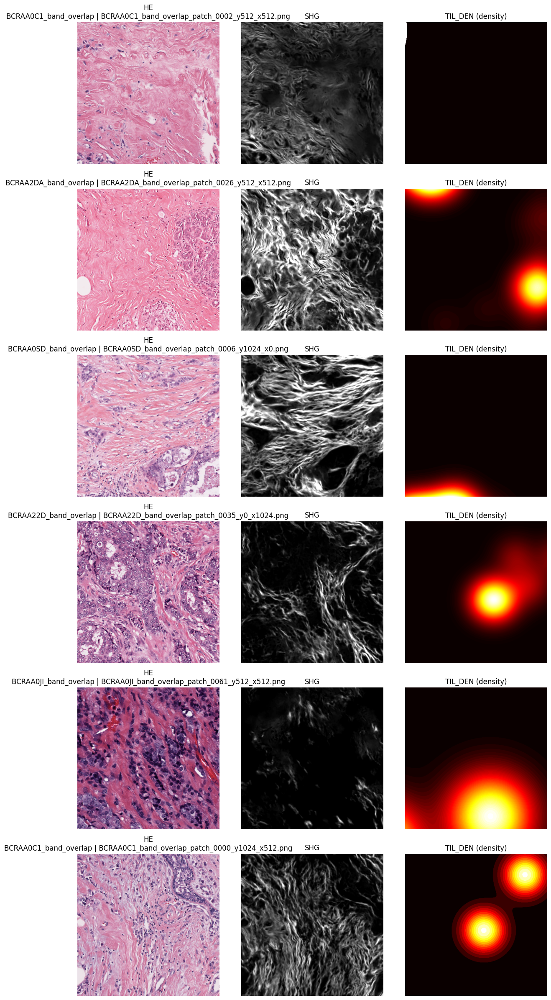


Visualizing tiles WITH TIL_DEN > 0 ...
[POS 0] BCRAA74U_band_overlap | BCRAA74U_band_overlap_patch_0019_y0_x1024.png: HE (512, 512, 3), SHG (512, 512), TIL_DEN (512, 512), TIL sum=1161.0
[POS 1] BCRAA0SM_band_overlap | BCRAA0SM_band_overlap_patch_0034_y0_x0.png: HE (512, 512, 3), SHG (512, 512), TIL_DEN (512, 512), TIL sum=382520.0
[POS 2] BCRAA4S2_band_overlap | BCRAA4S2_band_overlap_patch_0025_y0_x0.png: HE (512, 512, 3), SHG (512, 512), TIL_DEN (512, 512), TIL sum=4818.0
[POS 3] BCRAA3YJ_band_overlap | BCRAA3YJ_band_overlap_patch_0008_y1024_x0.png: HE (512, 512, 3), SHG (512, 512), TIL_DEN (512, 512), TIL sum=13803981.0
[POS 4] BCRAA0SM_band_overlap | BCRAA0SM_band_overlap_patch_0018_y1024_x0.png: HE (512, 512, 3), SHG (512, 512), TIL_DEN (512, 512), TIL sum=80872.0
[POS 5] BCRAA4SF_band_overlap | BCRAA4SF_band_overlap_patch_0005_y1536_x0.png: HE (512, 512, 3), SHG (512, 512), TIL_DEN (512, 512), TIL sum=2942.0


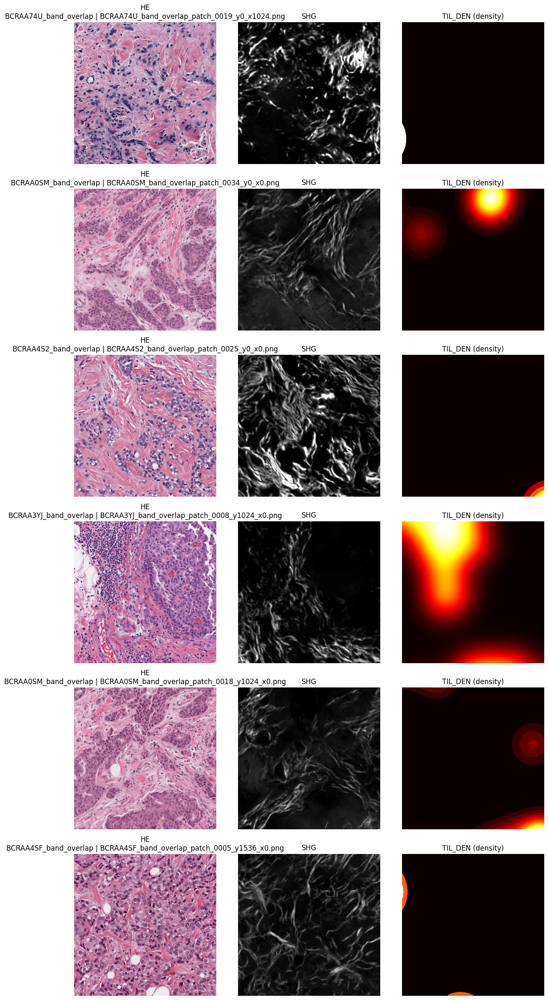

In [ ]:
# QC check pos_weight for sparsity and tiled image quality

import random
from pathlib import Path

import cv2
import numpy as np
import matplotlib.pyplot as plt
from collections import defaultdict

# assumes you already have read_gray + read_rgb from the tiler;
# if not, copy them here exactly as in your tiling code

def read_gray_patch(path: Path):
    """Simple wrapper for patches (they are PNG now)."""
    img = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)
    if img is None:
        raise FileNotFoundError(f"Could not read {path}")
    return img

def read_rgb_patch(path: Path):
    img = cv2.imread(str(path), cv2.IMREAD_COLOR)
    if img is None:
        raise FileNotFoundError(f"Could not read {path}")
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    return img
def qc_tiled_patches(all_samples, num_random=6, num_positive_examples=6):
    """
    all_samples: list of dicts from tiler:
       {"name", "patient", "he", "shg", "til_den"}
    """

    # ------------------------------------------------------------------
    # 1) Basic counts & positive patch fraction
    # ------------------------------------------------------------------
    patient_total = defaultdict(int)
    patient_pos   = defaultdict(int)

    overall_total = 0
    overall_pos   = 0

    print("Computing TIL_DEN positive patch statistics ...")
    for s in all_samples:
        til = read_gray_patch(Path(s["til_den"])).astype(np.float32)
        has_pos = til.sum() > 0.0

        patient = s["patient"]
        patient_total[patient] += 1
        overall_total += 1
        if has_pos:
            patient_pos[patient] += 1
            overall_pos += 1

    print("\n=== Tile-level TIL_DEN stats ===")
    print(f"Total tiles: {overall_total}")
    print(f"Tiles with TIL_DEN > 0: {overall_pos} "
          f"({100.0 * overall_pos / max(1, overall_total):.2f}%)\n")

    print("Per patient:")
    for pt in sorted(patient_total.keys()):
        tot = patient_total[pt]
        pos = patient_pos[pt]
        frac = 100.0 * pos / max(1, tot)
        print(f"  {pt:25s} -> {pos:5d} / {tot:5d} "
              f"({frac:6.2f}% positive)")

    # ------------------------------------------------------------------
    # 2) Random tiles (any) to check basic alignment
    # ------------------------------------------------------------------
    random_samples = random.sample(all_samples, min(num_random, len(all_samples)))

    print("\nVisualizing random tiles (HE / SHG / TIL_DEN) ...")
    n = len(random_samples)
    plt.figure(figsize=(12, 4 * n))

    for i, s in enumerate(random_samples):
        he  = read_rgb_patch(Path(s["he"]))
        shg = read_gray_patch(Path(s["shg"]))
        til = read_gray_patch(Path(s["til_den"]))

        # sanity check shapes
        print(f"[RANDOM {i}] {s['patient']} | {s['name']}: "
              f"HE {he.shape}, SHG {shg.shape}, TIL_DEN {til.shape}")

        # normalize for display
        shg_disp = shg.astype(np.float32)
        if shg_disp.max() > 0:
            shg_disp /= shg_disp.max()

        til_disp = til.astype(np.float32)
        if til_disp.max() > 0:
            til_disp /= til_disp.max()

        row = i
        # HE
        ax = plt.subplot(n, 3, 3 * row + 1)
        ax.imshow(he)
        ax.set_title(f"HE\n{ s['patient'] } | { s['name'] }")
        ax.axis("off")

        # SHG
        ax = plt.subplot(n, 3, 3 * row + 2)
        ax.imshow(shg_disp, cmap="gray")
        ax.set_title("SHG")
        ax.axis("off")

        # TIL_DEN
        ax = plt.subplot(n, 3, 3 * row + 3)
        ax.imshow(til_disp, cmap="hot")
        ax.set_title("TIL_DEN (density)")
        ax.axis("off")

    plt.tight_layout()
    plt.show()

    # ------------------------------------------------------------------
    # 3) Positive-only examples (tiles with any TIL_DEN)
    # ------------------------------------------------------------------
    pos_samples = [s for s in all_samples
                   if read_gray_patch(Path(s["til_den"])).sum() > 0.0]

    if not pos_samples:
        print("\nNo positive TIL_DEN tiles found to display.")
        return

    pos_samples = random.sample(pos_samples,
                                min(num_positive_examples, len(pos_samples)))

    print("\nVisualizing tiles WITH TIL_DEN > 0 ...")
    n = len(pos_samples)
    plt.figure(figsize=(12, 4 * n))

    for i, s in enumerate(pos_samples):
        he  = read_rgb_patch(Path(s["he"]))
        shg = read_gray_patch(Path(s["shg"]))
        til = read_gray_patch(Path(s["til_den"]))

        print(f"[POS {i}] {s['patient']} | {s['name']}: "
              f"HE {he.shape}, SHG {shg.shape}, TIL_DEN {til.shape}, "
              f"TIL sum={til.sum():.1f}")

        shg_disp = shg.astype(np.float32)
        if shg_disp.max() > 0:
            shg_disp /= shg_disp.max()

        til_disp = til.astype(np.float32)
        if til_disp.max() > 0:
            til_disp /= til_disp.max()

        row = i
        # HE
        ax = plt.subplot(n, 3, 3 * row + 1)
        ax.imshow(he)
        ax.set_title(f"HE\n{ s['patient'] } | { s['name'] }")
        ax.axis("off")

        # SHG
        ax = plt.subplot(n, 3, 3 * row + 2)
        ax.imshow(shg_disp, cmap="gray")
        ax.set_title("SHG")
        ax.axis("off")

        # TIL_DEN
        ax = plt.subplot(n, 3, 3 * row + 3)
        ax.imshow(til_disp, cmap="hot")
        ax.set_title("TIL_DEN (density)")
        ax.axis("off")

    plt.tight_layout()
    plt.show()


qc_tiled_patches(all_samples,
                 num_random=6,            # how many random tiles
                 num_positive_examples=6) # how many positive-only tiles


In [ ]:
from pathlib import Path
from collections import defaultdict
import random
import cv2
import numpy as np
import torch
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler

# ----------- IO helpers -----------
def read_rgb(path: Path):
    img = cv2.imread(str(path), cv2.IMREAD_COLOR)
    if img is None:
        raise IOError(f"Could not read image: {path}")
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    return img

def read_gray(path: Path):
    img = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)
    if img is None:
        raise IOError(f"Could not read image: {path}")
    return img

# --- Helper for robust min-max normalization ---
def robust_minmax(x, low_pct=1.0, high_pct=99.0):
    """
    Clip to [low_pct, high_pct] percentiles and min-max normalize to [0,1].
    Helps avoid a few super-bright pixels dominating the dynamic range.
    """
    x = x.astype(np.float32)
    lo, hi = np.percentile(x, [low_pct, high_pct])
    if hi <= lo:
        return np.zeros_like(x, dtype=np.float32)

    x = (x - lo) / (hi - lo)
    return x

# ================== DATASET ==================
class TILDensityDataset(Dataset):
    """
    Dataset for patient-wise HE + SHG + TIL_DEN patches at 512x512.

    Layout:
      root/
        [patient_code]/
          HE/*.png
          SHG/*.png
          TIL_DEN/*.png

    `pos_frac_thresh` controls when a tile is considered "positive" at tile level:
        pos_frac = fraction of pixels with TIL > 0
        has_pos = pos_frac >= pos_frac_thresh
    """

    def __init__(self,
                 root: Path,
                 patients,
                 input_mod: str = "SHG",
                 mask_mode: str = "density",
                 augment: bool = False,
                 pos_frac_thresh: float = 0.0):
        super().__init__()
        assert input_mod in ("HE", "SHG", "HE+SHG")
        assert mask_mode in ("binary", "density")

        self.root      = Path(root)
        self.patients  = list(patients)
        self.input_mod = input_mod
        self.mask_mode = mask_mode
        self.augment   = augment
        self.pos_frac_thresh = float(pos_frac_thresh)

        self.samples = []
        self.has_pos = []   # tile-level label for sampler

        for patient in self.patients:
            p_dir = self.root / patient
            he_dir  = p_dir / "HE"
            shg_dir = p_dir / "SHG"
            til_dir = p_dir / "TIL_DEN"

            if not til_dir.exists():
                print(f"  [WARN] Missing HE/SHG/TIL folder(s) for {patient}, skipping.")
                continue

            til_files = sorted(til_dir.glob("*.png"))
            print(f"[{patient}] Found {len(til_files)} TIL_DEN fields.")

            for t_path in til_files:
                fname = t_path.name

                he_path  = he_dir  / fname
                shg_path = shg_dir / fname

                ok = True
                if self.input_mod in ("HE", "HE+SHG") and not he_path.exists():
                    print(f"  [WARN] Missing HE for {patient}/{fname}, skipping.")
                    ok = False
                if self.input_mod in ("SHG", "HE+SHG") and not shg_path.exists():
                    print(f"  [WARN] Missing SHG for {patient}/{fname}, skipping.")
                    ok = False
                if not ok:
                    continue

                # --- tile-level positivity (before normalization) ---
                m_raw = read_gray(t_path).astype(np.float32)        # 0–255
                til_bin = (m_raw > 0).astype(np.float32)
                pos_frac = float(til_bin.mean())
                has_pos = (pos_frac >= self.pos_frac_thresh)

                self.samples.append({
                    "patient": patient,
                    "name":    fname,
                    "he":      he_path if he_path.exists() else None,
                    "shg":     shg_path if shg_path.exists() else None,
                    "til":     t_path,
                })
                self.has_pos.append(has_pos)

        n_all = len(self.samples)
        n_pos = int(sum(self.has_pos))
        print(f"[DATASET] Loaded {n_all} tiles from {len(self.patients)} patients,"
              f" {n_pos} ({100.0*n_pos/max(1,n_all):.2f}%) tiles above pos_frac_thresh={self.pos_frac_thresh}.")

        # per-patient stats
        per_patient = defaultdict(lambda: [0, 0])  # [pos, total]
        for s, h in zip(self.samples, self.has_pos):
            pt = s["patient"]
            per_patient[pt][1] += 1
            if h:
                per_patient[pt][0] += 1
        print("  Per patient:")
        for pt in sorted(per_patient.keys()):
            pos, total = per_patient[pt]
            frac = 100.0 * pos / max(1, total)
            print(f"    {pt:20s} -> {pos:4d} / {total:4d} ({frac:6.2f}% positive)")

    def __len__(self):
        return len(self.samples)

    # ----- simple aug -----
    def _augment(self, x, y):
        if random.random() < 0.5:
            x = torch.flip(x, dims=[2])
            y = torch.flip(y, dims=[2])
        if random.random() < 0.5:
            x = torch.flip(x, dims=[1])
            y = torch.flip(y, dims=[1])
        k = random.choice([0, 1, 2, 3])
        if k > 0:
            x = torch.rot90(x, k, dims=[1, 2])
            y = torch.rot90(y, k, dims=[1, 2])
        return x, y

    def __getitem__(self, idx):
        s = self.samples[idx]
        patient = s["patient"]
        name    = s["name"]

        # ---------- label (TIL_DEN) ----------
        mask_raw = read_gray(s["til"]).astype(np.float32)  # 0–255

        # normalize TIL map to [0,1]
        # ---------- label (TIL_DEN) ----------
        mask_np = read_gray(s["til"]).astype(np.float32)

        if self.mask_mode == "binary":
            mask_np = (mask_np > 0).astype(np.float32)
        else:  # "density"
            # robust normalization to keep super-bright spots under control
            mask_np = robust_minmax(mask_np, low_pct=1.0, high_pct=99.0)

        mask_t = torch.from_numpy(mask_np)[None, ...]  # [1,H,W]


        # ---------- inputs ----------
        if self.input_mod == "HE":
            he = read_rgb(s["he"]).astype(np.float32) / 255.0   # [0,1]
            x_np = np.transpose(he, (2, 0, 1))  # [3,H,W]

        elif self.input_mod == "SHG":
            shg = read_gray(s["shg"]).astype(np.float32)
            # OLD:
            # mn, mx = shg.min(), shg.max()
            # if mx > mn:
            #     shg = (shg - mn) / (mx - mn)
            # else:
            #     shg = np.zeros_like(shg, dtype=np.float32)

            # NEW: robust normalization
            shg = robust_minmax(shg, low_pct=1.0, high_pct=99.0)

            x_np = shg[None, ...]


        else:  # "HE+SHG"
            he = read_rgb(s["he"]).astype(np.float32) / 255.0
            he_chw = np.transpose(he, (2, 0, 1))  # [3,H,W]

            shg = read_gray(s["shg"]).astype(np.float32)
            shg = robust_minmax(shg, low_pct=1.0, high_pct=99.0)
            shg_ch = shg[None, ...]

            x_np = np.concatenate([he_chw, shg_ch], axis=0)


        x_t = torch.from_numpy(x_np).float()

        if self.augment:
            x_t, mask_t = self._augment(x_t, mask_t)

        meta = {"patient": patient, "name": name}
        return x_t, mask_t, meta

In [ ]:
POS_FRAC_THRESH = 0.1  # 1% of pixels > 0 in TIL map

# ================== PATIENT SPLITS (3-fold CV) ==================

from pathlib import Path

# -----------------------------
# DEFINE YOUR DATASET ROOT HERE
# -----------------------------
DATA_ROOT = Path("/content/Outputs_512_den_new")   # <-- change if needed
INPUT_MODALITY = "SHG"                          # or "SHG", "HE"

print("DATA_ROOT =", DATA_ROOT)
print("INPUT_MODALITY =", INPUT_MODALITY)


def get_fold_splits(fold_idx: int):
    """
    3 folds, each with:
      N_train = total - 4
      N_val   = 2
      N_test  = 2
    Patients are taken from PATIENT_CODES (sorted).
    """
    assert 0 <= fold_idx < 3

    N_PATIENTS = len(PATIENT_CODES)
    base = (3 * fold_idx) % N_PATIENTS

    test_indices = [
        base % N_PATIENTS,
        (base + 1) % N_PATIENTS
    ]
    val_indices = [
        (base + 2) % N_PATIENTS,
        (base + 3) % N_PATIENTS
    ]

    test_patients = [PATIENT_CODES[i] for i in test_indices]
    val_patients  = [PATIENT_CODES[i] for i in val_indices]

    test_set = set(test_patients)
    val_set  = set(val_patients)

    train_patients = [p for p in PATIENT_CODES if p not in test_set and p not in val_set]

    assert len(val_patients) == 2
    assert len(test_patients) == 2
    assert len(train_patients) == N_PATIENTS - 4

    print(f"\n===== Fold {fold_idx} =====")
    print("  Train patients:", train_patients)
    print("  Val patients:  ", val_patients)
    print("  Test patients: ", test_patients)

    return train_patients, val_patients, test_patients


def build_loaders_for_fold(fold_idx: int,
                       batch_size: int = 4,
                       num_workers: int = 2,
                       mask_mode: str = "density",
                       pos_tile_w: float = 1.0,
                       neg_tile_w: float = 1.0):

    train_patients, val_patients, test_patients = get_fold_splits(fold_idx)

    train_ds = TILDensityDataset(
        DATA_ROOT,
        patients=train_patients,
        input_mod=INPUT_MODALITY,
        mask_mode=mask_mode,
        augment=True,
        pos_frac_thresh=POS_FRAC_THRESH,
    )
    val_ds = TILDensityDataset(
        DATA_ROOT,
        patients=val_patients,
        input_mod=INPUT_MODALITY,
        mask_mode=mask_mode,
        augment=False,
        pos_frac_thresh=POS_FRAC_THRESH,
    )
    test_ds = TILDensityDataset(
        DATA_ROOT,
        patients=test_patients,
        input_mod=INPUT_MODALITY,
        mask_mode=mask_mode,
        augment=False,
        pos_frac_thresh=POS_FRAC_THRESH,
    )

    # weights for sampler (optional: different weights for pos / neg)
    weights = []
    for hp in train_ds.has_pos:
        weights.append(pos_tile_w if hp else neg_tile_w)
    weights = torch.tensor(weights, dtype=torch.float)

    sampler = WeightedRandomSampler(weights=weights,
                                    num_samples=len(weights),
                                    replacement=True)

    train_loader = DataLoader(train_ds, batch_size=batch_size,
                              sampler=sampler,
                              num_workers=num_workers,
                              pin_memory=True)
    val_loader   = DataLoader(val_ds, batch_size=1, shuffle=False,
                              num_workers=num_workers, pin_memory=True)
    test_loader  = DataLoader(test_ds, batch_size=1, shuffle=False,
                              num_workers=num_workers, pin_memory=True)

    return train_loader, val_loader, test_loader, train_ds, val_ds, test_ds


DATA_ROOT = /content/Outputs_512_den_new
INPUT_MODALITY = SHG


In [ ]:
train_loader, val_loader, test_loader, train_ds, val_ds, test_ds = \
    build_fold_loaders(
        fold_idx=0,
        batch_size=4,
        num_workers=0,      # safer in Colab / Jupyter
        pos_tile_w=1.0,
        neg_tile_w=1.0,
        mask_mode="density"
    )


x, y, meta = test_ds[0]
shg = x[-1].numpy()   # if HE+SHG
til = y[0].numpy()

plt.figure(figsize=(10,4))
plt.subplot(1,2,1); plt.imshow(shg, cmap="gray"); plt.title("SHG (robust norm)"); plt.axis("off")
plt.subplot(1,2,2); plt.imshow(til, cmap="hot");  plt.title("TIL_DEN (robust norm)"); plt.axis("off")
plt.show()



===== Fold 0 =====
  Train patients: ['BCRAA0YC_band_overlap', 'BCRAA2DA_band_overlap', 'BCRAA74U_band_overlap', 'BCRAA0CK_band_overlap', 'BCRAA04Y_band_overlap', 'BCRAA0AY_band_overlap', 'BCRAA0BG_band_overlap', 'BCRAA0C1_band_overlap', 'BCRAA0CK_band_overlap', 'BCRAA0IP_band_overlap', 'BCRAA0JI_band_overlap', 'BCRAA0SD_band_overlap', 'BCRAA0SI_band_overlap', 'BCRAA0SH_band_overlap', 'BCRAA0SM_band_overlap', 'BCRAA0SP_band_overlap', 'BCRAA0SQ_band_overlap', 'BCRAA1FC_band_overlap', 'BCRAA278_band_overlap', 'BCRAA2LE_band_overlap', 'BCRAA3OD_band_overlap', 'BCRAA3Y0_band_overlap', 'BCRAA3YJ_band_overlap', 'BCRAA4S2_band_overlap', 'BCRAAB41_band_overlap', 'BCRAA1LI_band_overlap']
  Val patients:   ['BCRAA0SF_band_overlap', 'BCRAA5DD_band_overlap']
  Test patients:  ['BCRAA4SF_band_overlap', 'BCRAA22D_band_overlap']


NameError: name 'DATA_ROOT' is not defined

In [ ]:
# AttnUnet
import torch
import torch.nn as nn
import torch.nn.functional as F

# -------- basic conv blocks --------
class DoubleConv(nn.Module):
    def __init__(self, in_ch, out_ch, dropout_p=0.0):
        super().__init__()
        self.seq = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=False),
            nn.Conv2d(out_ch, out_ch, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=False),
        )
        self.dropout = nn.Dropout2d(dropout_p) if dropout_p > 0 else nn.Identity()

    def forward(self, x):
        x = self.seq(x)
        x = self.dropout(x)
        return x

class Down(nn.Module):
    def __init__(self, in_ch, out_ch, dropout_p=0.0):
        super().__init__()
        self.pool = nn.MaxPool2d(2)
        self.conv = DoubleConv(in_ch, out_ch, dropout_p)

    def forward(self, x):
        x = self.pool(x)
        x = self.conv(x)
        return x

# -------- attention gate --------
class AttentionGate(nn.Module):
    def __init__(self, F_g, F_l, F_int):
        """
        F_g: channels of gating signal (from decoder)
        F_l: channels of skip connection (from encoder)
        F_int: intermediate channels
        """
        super().__init__()
        self.W_g = nn.Sequential(
            nn.Conv2d(F_g, F_int, kernel_size=1, bias=True),
            nn.BatchNorm2d(F_int),
        )
        self.W_x = nn.Sequential(
            nn.Conv2d(F_l, F_int, kernel_size=1, bias=True),
            nn.BatchNorm2d(F_int),
        )
        self.psi = nn.Sequential(
            nn.Conv2d(F_int, 1, kernel_size=1, bias=True),
            nn.BatchNorm2d(1),
            nn.Sigmoid()
        )
        self.relu = nn.ReLU(inplace=False)

    def forward(self, x, g):
        # x: encoder skip, g: decoder feature
        g1 = self.W_g(g)
        x1 = self.W_x(x)

        # upsample smaller one if shapes mismatch
        if g1.shape[-2:] != x1.shape[-2:]:
            g1 = F.interpolate(g1, size=x1.shape[-2:], mode="bilinear", align_corners=False)

        psi = self.relu(g1 + x1)
        psi = self.psi(psi)      # [B,1,H,W]
        out = x * psi            # apply attention
        return out

class UpAttn(nn.Module):
    def __init__(self, in_ch, skip_ch, out_ch, dropout_p=0.0):
        """
        in_ch:   decoder feature channels
        skip_ch: encoder skip channels
        out_ch:  output channels after fusion
        """
        super().__init__()
        self.up   = nn.ConvTranspose2d(in_ch, in_ch // 2, kernel_size=2, stride=2)
        self.attn = AttentionGate(F_g=in_ch // 2, F_l=skip_ch, F_int=skip_ch // 2)
        self.conv = DoubleConv(in_ch // 2 + skip_ch, out_ch, dropout_p)

    def forward(self, x, skip):
        x = self.up(x)
        if x.shape[-2:] != skip.shape[-2:]:
            x = F.interpolate(x, size=skip.shape[-2:], mode="bilinear", align_corners=False)

        skip_attn = self.attn(skip, x)
        x = torch.cat([skip_attn, x], dim=1)
        x = self.conv(x)
        return x

class AttnUNet(nn.Module):
    def __init__(self, in_ch=1, out_ch=1, base_ch=32, dropout_p=0.2):
        """
        in_ch:   4 for HE+SHG (RGB+SHG)
        out_ch:  1 for TIL density map
        base_ch: width of the first layer (scales as 32,64,128,256,512)
        """
        super().__init__()
        self.inc   = DoubleConv(in_ch,      base_ch,     dropout_p)
        self.down1 = Down(base_ch,          base_ch*2,   dropout_p)
        self.down2 = Down(base_ch*2,        base_ch*4,   dropout_p)
        self.down3 = Down(base_ch*4,        base_ch*8,   dropout_p)
        self.down4 = Down(base_ch*8,        base_ch*16,  dropout_p)

        self.up1   = UpAttn(base_ch*16,     base_ch*8,   base_ch*8,  dropout_p)
        self.up2   = UpAttn(base_ch*8,      base_ch*4,   base_ch*4,  dropout_p)
        self.up3   = UpAttn(base_ch*4,      base_ch*2,   base_ch*2,  dropout_p)
        self.up4   = UpAttn(base_ch*2,      base_ch,     base_ch,    dropout_p)

        self.outc  = nn.Conv2d(base_ch, out_ch, kernel_size=1)

    def forward(self, x):
        x1 = self.inc(x)     # [B, base,   H,   W]
        x2 = self.down1(x1)  # [B, 2base,  H/2, W/2]
        x3 = self.down2(x2)  # [B, 4base,  H/4, W/4]
        x4 = self.down3(x3)  # [B, 8base,  H/8, W/8]
        x5 = self.down4(x4)  # [B,16base, H/16,W/16]

        x  = self.up1(x5, x4)
        x  = self.up2(x,  x3)
        x  = self.up3(x,  x2)
        x  = self.up4(x,  x1)

        logits = self.outc(x)  # [B,1,H,W]
        return logits


In [ ]:
# Resume training from saved weights if new training start from below

from pathlib import Path
import torch
import os
import cv2
import numpy as np
from collections import defaultdict
import random
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
CKPT_PATH = Path("/content/best_model_fold0.pt")   # <-- downloaded file
FOLD_IDX = 0

# Assuming DATA_ROOT, INPUT_MODALITY, MASK_MODE, PATIENT_CODES, N_PATIENTS are defined globally (from 2wJeDMmEa8n9)

# ================== IO HELPERS (from 2wJeDMmEa8n9) ==================
def read_rgb(path: Path):
    img = cv2.imread(str(path), cv2.IMREAD_COLOR)
    if img is None:
        raise IOError(f"Could not read image: {path}")
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    return img

def read_gray(path: Path):
    img = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)
    if img is None:
        raise IOError(f"Could not read image: {path}")
    return img

# ================== DATASET (from 2wJeDMmEa8n9) ==================
class TILDensityDataset(Dataset):
    """
    Dataset for patient-wise HE + SHG + TIL_DEN patches at 512x512.

    Layout:
      root/
        [patient_code]/
          HE/*.png
          SHG/*.png
          TIL_DEN/*.png

    We use TIL_DEN patches as labels; filenames are identical across modalities.
    """

    def __init__(self,
                 root: Path,
                 patients,
                 input_mod: str = "HE+SHG",
                 mask_mode: str = "density",
                 augment: bool = False):
        super().__init__()
        assert input_mod in ("HE", "SHG", "HE+SHG")
        assert mask_mode in ("binary", "density")

        self.root      = Path(root)
        self.patients  = list(patients)
        self.input_mod = input_mod
        self.mask_mode = mask_mode
        self.augment   = augment

        self.samples = []
        self.has_pos = []   # tile-level "any positive pixel" label

        for patient in self.patients:
            p_dir = self.root / patient
            he_dir  = p_dir / "HE"
            shg_dir = p_dir / "SHG"
            til_dir = p_dir / "TIL_DEN"

            if not til_dir.exists():
                print(f"  [WARN] No TIL_DEN folder for {patient}, skipping patient.")
                continue

            til_files = sorted(til_dir.glob("*.png"))
            print(f"[{patient}] Found {len(til_files)} TIL_DEN patches.")

            for t_path in til_files:
                fname = t_path.name

                he_path  = he_dir  / fname
                shg_path = shg_dir / fname

                ok = True
                if self.input_mod in ("HE", "HE+SHG") and not he_path.exists():
                    print(f"  [WARN] Missing HE for {patient}/{fname}, skipping.")
                    ok = False
                if self.input_mod in ("SHG", "HE+SHG") and not shg_path.exists():
                    print(f"  [WARN] Missing SHG for {patient}/{fname}, skipping.")
                    ok = False
                if not ok:
                    continue

                # compute has_pos once
                m_np = read_gray(t_path).astype(np.float32)
                pos_mask = (m_np > 0).astype(np.float32)
                has_pos = bool(pos_mask.sum() > 0)

                self.samples.append({
                    "patient": patient,
                    "name":    fname,
                    "he":      he_path if he_path.exists() else None,
                    "shg":     shg_path if shg_path.exists() else None,
                    "til":     t_path,
                })
                self.has_pos.append(has_pos)

        n_all = len(self.samples)
        n_pos = int(sum(self.has_pos))
        print(f"[DATASET] Loaded {n_all} tiles from {len(self.patients)} patients,"
              f" {n_pos} ({100.0*n_pos/max(1,n_all):.2f}%) tiles with TIL > 0.")

        # per-patient stats
        per_patient = defaultdict(lambda: [0, 0])  # [pos, total]
        for s, h in zip(self.samples, self.has_pos):
            pt = s["patient"]
            per_patient[pt][1] += 1
            if h:
                per_patient[pt][0] += 1
        print("  Per patient:")
        for pt in sorted(per_patient.keys()):
            pos, total = per_patient[pt]
            frac = 100.0 * pos / max(1, total)
            print(f"    {pt:20s} -> {pos:4d} / {total:4d} ({frac:6.2f}% positive)")

    def __len__(self):
        return len(self.samples)

    def _augment(self, x, y):
        # x: [C,H,W], y: [1,H,W]
        if random.random() < 0.5:
            x = torch.flip(x, dims=[2])
            y = torch.flip(y, dims=[2])
        if random.random() < 0.5:
            x = torch.flip(x, dims=[1])
            y = torch.flip(y, dims=[1])
        k = random.choice([0, 1, 2, 3])
        if k > 0:
            x = torch.rot90(x, k, dims=[1, 2])
            y = torch.rot90(y, k, dims=[1, 2])
        return x, y

    def __getitem__(self, idx):
        s = self.samples[idx]
        patient = s["patient"]
        name    = s["name"]

        # ---------- label (TIL_DEN) ----------
        mask_np = read_gray(s["til"]).astype(np.float32)

        if self.mask_mode == "binary":
            mask_np = (mask_np > 0).astype(np.float32)
        else:  # "density"
            mn, mx = mask_np.min(), mask_np.max()
            if mx > mn:
                mask_np = (mask_np - mn) / (mx - mn)
            else:
                mask_np = np.zeros_like(mask_np, dtype=np.float32)

        mask_t = torch.from_numpy(mask_np)[None, ...]  # [1,H,W]

        # ---------- inputs ----------
        if self.input_mod == "HE":
            he = read_rgb(s["he"]).astype(np.float32) / 255.0
            x_np = np.transpose(he, (2, 0, 1))  # [3,H,W]

        elif self.input_mod == "SHG":
            shg = read_gray(s["shg"]).astype(np.float32)
            mn, mx = shg.min(), shg.max()
            if mx > mn:
                shg = (shg - mn) / (mx - mn)
            else:
                shg = np.zeros_like(shg, dtype=np.float32)
            x_np = shg[None, ...]

        else:  # "HE+SHG"
            he = read_rgb(s["he"]).astype(np.float32) / 255.0
            he_chw = np.transpose(he, (2, 0, 1))  # [3,H,W]

            shg = read_gray(s["shg"]).astype(np.float32)
            mn, mx = shg.min(), shg.max()
            if mx > mn:
                shg = (shg - mn) / (mx - mn)
            else:
                shg = np.zeros_like(shg, dtype=np.float32)
            shg_ch = shg[None, ...]

            x_np = np.concatenate([he_chw, shg_ch], axis=0)  # [4,H,W]

        x_t = torch.from_numpy(x_np).float()

        if self.augment:
            x_t, mask_t = self._augment(x_t, mask_t)

        meta = {"patient": patient, "name": name}
        return x_t, mask_t, meta

# ================== PATIENT SPLITS (3 folds) (from 2wJeDMmEa8n9) ==================
def get_fold_splits(fold_idx: int):
    """
    3 folds, each with:
      a flexible number of train patients (total - 4)
      2 val patients
      2 test patients
    Patients are taken from PATIENT_CODES (sorted).
    """
    assert 0 <= fold_idx < 3

    # The original base calculation (3 * fold_idx) % N_PATIENTS works well
    # for rotating test and validation sets across folds for N_PATIENTS=8.
    base = (3 * fold_idx) % N_PATIENTS

    test_indices = [base % N_PATIENTS,
                    (base + 1) % N_PATIENTS]
    val_indices  = [(base + 2) % N_PATIENTS,
                    (base + 3) % N_PATIENTS]

    test_patients = [PATIENT_CODES[i] for i in test_indices]
    val_patients  = [PATIENT_CODES[i] for i in val_indices]

    test_set = set(test_patients)
    val_set  = set(val_patients)
    train_patients = [p for p in PATIENT_CODES
                      if p not in test_set and p not in val_set]

    # This assertion now correctly reflects the number of training patients given N_PATIENTS
    assert len(train_patients) == N_PATIENTS - 4, f"Expected {N_PATIENTS - 4} train patients, got {len(train_patients)}"
    assert len(val_patients) == 2
    assert len(test_patients) == 2

    print(f"\n===== Fold {fold_idx} =====")
    print("  Train patients:", train_patients)
    print("  Val patients:  ", val_patients)
    print("  Test patients: ", test_patients)

    return train_patients, val_patients, test_patients


# ================== BUILD DATALOADERS PER FOLD (from iWGuKacXrEN3) ==================
def build_loaders_for_fold(root, fold_info, input_mod="HE+SHG",
                           batch_size=4, num_workers=0):
    train_patients = fold_info["train_patients"]
    val_patients   = fold_info["val_patients"]
    test_patients  = fold_info["test_patients"]

    print("===== Fold", fold_info["id"], "=====")
    print(" Train patients:", train_patients)
    print(" Val patients:  ", val_patients)
    print(" Test patients: ", test_patients)

    # Use TILDensityDataset instead of TILTiledDataset
    train_ds = TILDensityDataset(root, train_patients,
                               input_mod=input_mod,
                               augment=True,   # keep aug
                               mask_mode="density")
    val_ds   = TILDensityDataset(root, val_patients,
                               input_mod=input_mod,
                               augment=False,
                               mask_mode="density")
    test_ds  = TILDensityDataset(root, test_patients,
                               input_mod=input_mod,
                               augment=False,
                               mask_mode="density")

    # optional: tile-level oversampling based on "has_pos"
    pos_w, neg_w = 1.0, 1.0
    sample_weights = torch.tensor(
        [pos_w if hp else neg_w for hp in train_ds.has_pos],
        dtype=torch.float
    )
    sampler = WeightedRandomSampler(
        weights=sample_weights,
        num_samples=len(sample_weights),
        replacement=True
    )

    train_loader = DataLoader(
        train_ds,
        batch_size=batch_size,
        sampler=sampler,
        num_workers=num_workers,   # 0 to avoid AssertionError in Colab
        pin_memory=True,
        persistent_workers=False
    )
    val_loader = DataLoader(
        val_ds,
        batch_size=1,
        shuffle=False,
        num_workers=num_workers,
        pin_memory=True,
        persistent_workers=False
    )
    test_loader = DataLoader(
        test_ds,
        batch_size=1,
        shuffle=False,
        num_workers=num_workers,
        pin_memory=True,
        persistent_workers=False
    )

    xb, yb, meta = next(iter(train_loader))
    print("  Example train batch:", xb.shape, yb.shape)
    if isinstance(meta, dict): # Check if meta is a dictionary of lists (like in the dataloader in 2wJeDMmEa8n9)
        print("  Example tile:", meta["patient"][0], meta["name"][0])
    else: # Fallback for older dataloader behavior where meta could be a list of dicts
        print("  Example tile:", meta[0]["patient"], meta[0]["name"])


    return train_loader, val_loader, test_loader, train_ds, val_ds, test_ds

# Prepare fold info
train_patients, val_patients, test_patients = get_fold_splits(FOLD_IDX)
fold_info = {
    "id": FOLD_IDX,
    "train_patients": train_patients,
    "val_patients": val_patients,
    "test_patients": test_patients,
}

train_loader, val_loader, test_loader, train_ds, val_ds, test_ds = \
    build_loaders_for_fold(
        DATA_ROOT,
        fold_info,
        input_mod=INPUT_MODALITY,   # "HE+SHG"
        batch_size=4,               # works for 512×512
        num_workers=0               # to avoid multiprocessing assertion
    )


NameError: name 'N_PATIENTS' is not defined

In [ ]:
import torch.nn as nn
from tqdm.auto import tqdm
from sklearn.metrics import roc_auc_score, average_precision_score
import numpy as np

MAX_EPOCHS  = 50     # continue training up to this point
LR          = 1e-4
WEIGHT_DECAY = 1e-4
PATIENCE    = 5

# -------- Optimizer builder --------
def build_optimizer(model, lr=LR, weight_decay=WEIGHT_DECAY):
    decay_params, no_decay_params = [], []
    for name, p in model.named_parameters():
        if not p.requires_grad:
            continue
        if p.ndim == 1 or name.endswith(".bias"):
            no_decay_params.append(p)
        else:
            decay_params.append(p)
    return torch.optim.AdamW(
        [
            {"params": decay_params,    "weight_decay": weight_decay},
            {"params": no_decay_params, "weight_decay": 0.0},
        ],
        lr=lr,
    )

# -------- Load checkpoint --------
# Fix: Add weights_only=False to address UnpicklingError in newer PyTorch versions
ckpt = torch.load(CKPT_PATH, map_location=DEVICE, weights_only=False)
print("Loaded checkpoint:", CKPT_PATH)

# Fix: Determine in_ch based on INPUT_MODALITY, similar to the main training loop
# Assuming INPUT_MODALITY is defined globally (e.g., from cell 2wJeDMmEa8n9 or similar)
# If INPUT_MODALITY was 'HE', in_ch=3
# If INPUT_MODALITY was 'SHG', in_ch=1
# If INPUT_MODALITY was 'HE+SHG', in_ch=4
# Using the global INPUT_MODALITY variable from the current notebook state
if INPUT_MODALITY == "HE":
    in_ch = 3
elif INPUT_MODALITY == "SHG":
    in_ch = 1
else: # Default to HE+SHG
    in_ch = 4

model = AttnUNet(in_ch=in_ch, out_ch=1).to(DEVICE)
model.load_state_dict(ckpt["model_state"])

optimizer = build_optimizer(model)
try:
    optimizer.load_state_dict(ckpt["optimizer_state"])
    print("Optimizer state restored.")
except:
    print("Optimizer state could not be restored (OK).")

start_epoch   = ckpt.get("epoch", 0) + 1
best_val_loss = ckpt.get("val_loss", float("inf"))
patience_ctr  = 0

print(f"Resuming from epoch {start_epoch}, best val loss {best_val_loss:.4f}")


Loaded checkpoint: /content/best_model_fold0.pt
Optimizer state restored.
Resuming from epoch 14, best val loss 0.1400


In [ ]:
for epoch in range(start_epoch, MAX_EPOCHS+1):
    train_loss = train_one_epoch(epoch, model, train_loader, optimizer, DEVICE)
    val_loss, val_auroc, val_auprc = validate_one_epoch(epoch, model, val_loader, DEVICE)

    print(f"[Fold0] Epoch {epoch:03d} | "
          f"train {train_loss:.4f} | val {val_loss:.4f} | "
          f"AUROC {val_auroc:.4f} | AUPRC {val_auprc:.4f}")

    # ----- save best -----
    if val_loss < best_val_loss - 1e-4:
        best_val_loss = val_loss
        patience_ctr = 0

        torch.save(
            {
                "epoch": epoch,
                "model_state": model.state_dict(),
                "optimizer_state": optimizer.state_dict(),
                "val_loss": val_loss,
                "val_auroc": val_auroc,
                "val_auprc": val_auprc,
            },
            CKPT_PATH
        )
        print(f"Saved new best checkpoint → {CKPT_PATH}")

    else:
        patience_ctr += 1
        if patience_ctr >= PATIENCE:
            print(f"Early stopping at epoch {epoch}")
            break


[train] Epoch 14:   0%|          | 0/536 [00:00<?, ?it/s]

[val]   Epoch 14:   0%|          | 0/1840 [00:00<?, ?it/s]

[Fold0] Epoch 014 | train 0.2614 | val 0.2168 | AUROC 0.5440 | AUPRC 0.3024
Saved new best checkpoint → /content/best_model_fold0.pt


[train] Epoch 15:   0%|          | 0/536 [00:00<?, ?it/s]

[val]   Epoch 15:   0%|          | 0/1840 [00:00<?, ?it/s]

[Fold0] Epoch 015 | train 0.1433 | val 0.1689 | AUROC 0.4719 | AUPRC 0.2647
Saved new best checkpoint → /content/best_model_fold0.pt


... (2 outputs left out)

[Fold0] Epoch 016 | train 0.0955 | val 0.1527 | AUROC 0.5755 | AUPRC 0.3390
Saved new best checkpoint → /content/best_model_fold0.pt


[train] Epoch 17:   0%|          | 0/536 [00:00<?, ?it/s]

[val]   Epoch 17:   0%|          | 0/1840 [00:00<?, ?it/s]

KeyboardInterrupt: 

In [ ]:
# New training starts from here

import torch
from torch.utils.data import DataLoader, WeightedRandomSampler
from tqdm.auto import tqdm
import numpy as np
import os

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# ----------------- build loaders -----------------
def build_fold_loaders(fold_idx: int,
                       batch_size: int = 4,
                       num_workers: int = 0,
                       pos_tile_w: float = 1.0,
                       neg_tile_w: float = 1.0,
                       mask_mode: str = "density",
                       pos_frac_thresh: float = 0.1):
    train_patients, val_patients, test_patients = get_fold_splits(fold_idx)

    train_ds = TILDensityDataset(
        DATA_ROOT,
        patients=train_patients,
        input_mod=INPUT_MODALITY,      # "HE+SHG"
        mask_mode=mask_mode,
        augment=True,
        pos_frac_thresh=pos_frac_thresh
    )
    val_ds = TILDensityDataset(
        DATA_ROOT,
        patients=val_patients,
        input_mod=INPUT_MODALITY,
        mask_mode=mask_mode,
        augment=False,
        pos_frac_thresh=pos_frac_thresh
    )
    test_ds = TILDensityDataset(
        DATA_ROOT,
        patients=test_patients,
        input_mod=INPUT_MODALITY,
        mask_mode=mask_mode,
        augment=False,
        pos_frac_thresh=pos_frac_thresh
    )

    # oversample "positive" tiles in training
    w = []
    for hp in train_ds.has_pos:
        w.append(pos_tile_w if hp else neg_tile_w)
    w = torch.tensor(w, dtype=torch.float)
    sampler = WeightedRandomSampler(weights=w,
                                    num_samples=len(w),
                                    replacement=True)

    train_loader = DataLoader(
        train_ds,
        batch_size=batch_size,
        sampler=sampler,
        num_workers=num_workers,
        pin_memory=True,
    )
    val_loader = DataLoader(
        val_ds,
        batch_size=batch_size,
        shuffle=False,
        num_workers=num_workers,
        pin_memory=True,
    )
    test_loader = DataLoader(
        test_ds,
        batch_size=batch_size,
        shuffle=False,
        num_workers=num_workers,
        pin_memory=True,
    )

    return train_loader, val_loader, test_loader, train_ds, val_ds, test_ds

# ----------------- training utils -----------------
def train_one_fold(fold_idx: int,
                   n_epochs: int = 30,
                   lr: float = 1e-4,
                   weight_decay: float = 1e-4,
                   save_dir: str = "./models"):
    os.makedirs(save_dir, exist_ok=True)

    train_loader, val_loader, test_loader, train_ds, val_ds, test_ds = \
        build_fold_loaders(fold_idx, batch_size=4, num_workers=0)

    in_ch = 4 if INPUT_MODALITY == "HE+SHG" else (3 if INPUT_MODALITY == "HE" else 1)

    model = AttnUNet(in_ch=in_ch, out_ch=1, base_ch=32, dropout_p=0.2).to(DEVICE)

    criterion = nn.BCEWithLogitsLoss()
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode="min", factor=0.5, patience=4
    )

    best_val_loss = np.inf
    best_path = os.path.join(save_dir, f"best_model_fold{fold_idx}.pt")

    for epoch in range(1, n_epochs + 1):
        # ------ train ------
        model.train()
        running_loss = 0.0
        n_samples = 0

        pbar = tqdm(train_loader, desc=f"Fold {fold_idx} | Epoch {epoch} [train]", leave=False)
        for xb, yb, _ in pbar:
            xb = xb.to(DEVICE, non_blocking=True)
            yb = yb.to(DEVICE, non_blocking=True)

            optimizer.zero_grad()
            logits = model(xb)
            loss = criterion(logits, yb)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()

            bs = xb.size(0)
            running_loss += loss.item() * bs
            n_samples += bs
            pbar.set_postfix({"loss": running_loss / max(1, n_samples)})

        train_loss = running_loss / max(1, n_samples)

        # ------ validation ------
        model.eval()
        val_loss = 0.0
        n_val = 0
        with torch.no_grad():
            for xb, yb, _ in tqdm(val_loader,
                                  desc=f"Fold {fold_idx} | Epoch {epoch} [val]",
                                  leave=False):
                xb = xb.to(DEVICE, non_blocking=True)
                yb = yb.to(DEVICE, non_blocking=True)

                logits = model(xb)
                loss = criterion(logits, yb)

                bs = xb.size(0)
                val_loss += loss.item() * bs
                n_val += bs

        val_loss = val_loss / max(1, n_val)
        scheduler.step(val_loss)

        lr_now = optimizer.param_groups[0]["lr"]
        print(f"[Fold {fold_idx}] Epoch {epoch:03d} | "
              f"train_loss={train_loss:.4f}  val_loss={val_loss:.4f}  lr={lr_now:.2e}")

        # ------ save best ------
        if val_loss < best_val_loss:
            best_val_loss = val_loss
            torch.save({
                "epoch": epoch,
                "model_state": model.state_dict(),
                "optimizer_state": optimizer.state_dict(),
                "val_loss": best_val_loss,
            }, best_path)
            print(f"  -> New best model saved to {best_path} (val_loss={best_val_loss:.4f})")

    print(f"Training finished for fold {fold_idx}. Best val_loss={best_val_loss:.4f}")
    return best_path

# ----------------- run for all 3 folds -----------------
for fold_idx in range(3):
    best_ckpt_path = train_one_fold(fold_idx)
    print(f"Fold {fold_idx} best checkpoint: {best_ckpt_path}")



===== Fold 0 =====
  Train patients: ['BCRAA0YC_band_overlap', 'BCRAA2DA_band_overlap', 'BCRAA74U_band_overlap', 'BCRAA0CK_band_overlap', 'BCRAA04Y_band_overlap', 'BCRAA0AY_band_overlap', 'BCRAA0BG_band_overlap', 'BCRAA0C1_band_overlap', 'BCRAA0CK_band_overlap', 'BCRAA0IP_band_overlap', 'BCRAA0JI_band_overlap', 'BCRAA0SD_band_overlap', 'BCRAA0SI_band_overlap', 'BCRAA0SH_band_overlap', 'BCRAA0SM_band_overlap', 'BCRAA0SP_band_overlap', 'BCRAA0SQ_band_overlap', 'BCRAA1FC_band_overlap', 'BCRAA278_band_overlap', 'BCRAA2LE_band_overlap', 'BCRAA3OD_band_overlap', 'BCRAA3Y0_band_overlap', 'BCRAA3YJ_band_overlap', 'BCRAA4S2_band_overlap', 'BCRAAB41_band_overlap', 'BCRAA1LI_band_overlap']
  Val patients:   ['BCRAA0SF_band_overlap', 'BCRAA5DD_band_overlap']
  Test patients:  ['BCRAA4SF_band_overlap', 'BCRAA22D_band_overlap']
[BCRAA0YC_band_overlap] Found 192 TIL_DEN fields.
[BCRAA2DA_band_overlap] Found 176 TIL_DEN fields.
[BCRAA74U_band_overlap] Found 160 TIL_DEN fields.
[BCRAA0CK_band_overlap]

Fold 0 | Epoch 1 [train]:   0%|          | 0/1016 [00:00<?, ?it/s]

Fold 0 | Epoch 1 [val]:   0%|          | 0/168 [00:00<?, ?it/s]

[Fold 0] Epoch 001 | train_loss=0.4073  val_loss=0.3292  lr=1.00e-04
  -> New best model saved to ./models/best_model_fold0.pt (val_loss=0.3292)


Fold 0 | Epoch 2 [train]:   0%|          | 0/1016 [00:00<?, ?it/s]

Fold 0 | Epoch 2 [val]:   0%|          | 0/168 [00:00<?, ?it/s]

... (71 outputs left out)

Fold 0 | Epoch 26 [val]:   0%|          | 0/168 [00:00<?, ?it/s]

[Fold 0] Epoch 026 | train_loss=0.2668  val_loss=0.3014  lr=6.25e-06


Fold 0 | Epoch 27 [train]:   0%|          | 0/1016 [00:00<?, ?it/s]

KeyboardInterrupt: 

In [ ]:
#################################################################Training done###################################################################

In [ ]:
# Model evaluation starts from here AUROC AUPRC, etc.

import torch
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from collections import defaultdict
from sklearn.metrics import (
    roc_curve,
    precision_recall_curve,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
)
from tqdm.auto import tqdm

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")


@torch.no_grad()
def collect_predictions_and_til(model, loader, device):
    """
    Collect:
      - flattened scores (probs in [0,1])
      - flattened binary labels (target>0)
      - per-patient true/predicted %TIL
      - global true/pred %TIL
    """
    model.eval()

    all_scores = []
    all_labels = []

    patient_true_sum  = defaultdict(float)
    patient_pred_sum  = defaultdict(float)
    patient_pixel_cnt = defaultdict(int)

    total_true_sum = 0.0
    total_pred_sum = 0.0
    total_pixels   = 0

    for xb, yb, meta in tqdm(loader, desc="[collect preds]"):
        xb = xb.to(device, non_blocking=True)
        yb = yb.to(device, non_blocking=True)

        logits = model(xb)
        probs  = torch.sigmoid(logits)  # [B,1,H,W]

        scores = probs.detach().cpu().numpy().ravel()
        labels = (yb.detach().cpu().numpy() > 0.0).astype(np.uint8).ravel()

        all_scores.append(scores)
        all_labels.append(labels)

        if isinstance(meta, dict):
            patients = meta["patient"]
        else:
            patients = [m["patient"] for m in meta]

        B = xb.size(0)
        for i in range(B):
            pt = patients[i]
            y_i = yb[i, 0]
            p_i = probs[i, 0]

            patient_true_sum[pt]  += float(y_i.sum().item())
            patient_pred_sum[pt]  += float(p_i.sum().item())
            patient_pixel_cnt[pt] += int(y_i.numel())

            total_true_sum += float(y_i.sum().item())
            total_pred_sum += float(p_i.sum().item())
            total_pixels   += int(y_i.numel())

    all_scores = np.concatenate(all_scores)
    all_labels = np.concatenate(all_labels)

    patient_til_pct = {}
    for pt in sorted(patient_pixel_cnt.keys()):
        npx = patient_pixel_cnt[pt]
        true_pct = 100.0 * patient_true_sum[pt] / max(1, npx)
        pred_pct = 100.0 * patient_pred_sum[pt] / max(1, npx)
        patient_til_pct[pt] = {"true_pct": true_pct, "pred_pct": pred_pct}

    global_true_pct = 100.0 * total_true_sum / max(1, total_pixels)
    global_pred_pct = 100.0 * total_pred_sum / max(1, total_pixels)

    return all_scores, all_labels, patient_til_pct, global_true_pct, global_pred_pct


def plot_roc_pr_confusion(scores, labels, title_prefix="TEST"):
    """
    Plot ROC, PR, and confusion matrix (at F1-optimal threshold)
    Return best_thr, auroc, auprc.
    """
    # ROC
    fpr, tpr, roc_thr = roc_curve(labels, scores)
    auroc = roc_auc_score(labels, scores)

    # PR
    precision, recall, pr_thr = precision_recall_curve(labels, scores)
    auprc = average_precision_score(labels, scores)

    print(f"{title_prefix} AUROC = {auroc:.4f}, AUPRC = {auprc:.4f}")

    plt.figure(figsize=(12, 4))

    # ROC curve
    plt.subplot(1, 3, 1)
    plt.plot(fpr, tpr)
    plt.plot([0, 1], [0, 1], "--")
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title(f"{title_prefix} ROC (AUROC={auroc:.3f})")

    # PR curve
    plt.subplot(1, 3, 2)
    plt.plot(recall, precision)
    plt.xlabel("Recall")
    plt.ylabel("Precision")
    plt.title(f"{title_prefix} PR (AUPRC={auprc:.3f})")

    # F1-opt threshold from PR curve
    # last point of PR curve has no threshold
    f1 = 2 * precision[:-1] * recall[:-1] / (precision[:-1] + recall[:-1] + 1e-8)
    best_idx = int(np.argmax(f1))
    best_thr = float(pr_thr[best_idx])
    print(
        f"{title_prefix} F1-optimal threshold = {best_thr:.4f} "
        f"(P={precision[best_idx]:.3f}, R={recall[best_idx]:.3f})"
    )

    # Confusion matrix at F1-opt threshold
    preds_bin = (scores >= best_thr).astype(int)
    cm = confusion_matrix(labels, preds_bin)

    plt.subplot(1, 3, 3)
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cbar=False,
        xticklabels=["Pred 0", "Pred 1"],
        yticklabels=["True 0", "True 1"],
    )
    plt.title("Confusion matrix")
    plt.tight_layout()
    plt.show()

    return best_thr, auroc, auprc


@torch.no_grad()
def visualize_random_tiles(model, loader, device, n_tiles=4, thr_for_vis=0.5):
    """
    Show HE, SHG, GT TIL density, and predicted TIL density
    with a binary contour overlay (for intuition).
    """
    model.eval()
    shown = 0

    for xb, yb, meta in loader:
        xb = xb.to(device)
        yb = yb.to(device)
        logits = model(xb)
        probs  = torch.sigmoid(logits)

        B = xb.size(0)
        for i in range(B):
            if shown >= n_tiles:
                return

            x_i = xb[i].detach().cpu().numpy()
            y_i = yb[i, 0].detach().cpu().numpy()
            p_i = probs[i, 0].detach().cpu().numpy()

            if isinstance(meta, dict):
                patient = meta["patient"][i]
                name    = meta["name"][i]
            else:
                patient = meta[i]["patient"]
                name    = meta[i]["name"]

            he  = np.transpose(x_i[0:3], (1, 2, 0))  # [H,W,3]
            he  = np.clip(he, 0, 1)
            shg = x_i[3]
            shg = np.clip(shg, 0, 1)

            pred_bin = (p_i >= thr_for_vis).astype(float)

            plt.figure(figsize=(12, 3))
            plt.suptitle(f"{patient} | {name}", fontsize=10)

            plt.subplot(1, 4, 1)
            plt.imshow(he)
            plt.axis("off")
            plt.title("HE")

            plt.subplot(1, 4, 2)
            plt.imshow(shg, cmap="gray")
            plt.axis("off")
            plt.title("SHG")

            plt.subplot(1, 4, 3)
            plt.imshow(y_i, cmap="hot")
            plt.axis("off")
            plt.title("GT TIL_DEN")

            plt.subplot(1, 4, 4)
            plt.imshow(p_i, cmap="hot")
            plt.contour(pred_bin, colors="cyan", linewidths=0.5)
            plt.axis("off")
            plt.title("Pred TIL_DEN + mask")

            plt.tight_layout()
            plt.show()

            shown += 1



================ Fold 0 =================

===== Fold 0 =====
  Train patients: ['BCRAA0YC_band_overlap', 'BCRAA2DA_band_overlap', 'BCRAA74U_band_overlap', 'BCRAA0CK_band_overlap', 'BCRAA04Y_band_overlap', 'BCRAA0AY_band_overlap', 'BCRAA0BG_band_overlap', 'BCRAA0C1_band_overlap', 'BCRAA0CK_band_overlap', 'BCRAA0IP_band_overlap', 'BCRAA0JI_band_overlap', 'BCRAA0SD_band_overlap', 'BCRAA0SI_band_overlap', 'BCRAA0SH_band_overlap', 'BCRAA0SM_band_overlap', 'BCRAA0SP_band_overlap', 'BCRAA0SQ_band_overlap', 'BCRAA1FC_band_overlap', 'BCRAA278_band_overlap', 'BCRAA2LE_band_overlap', 'BCRAA3OD_band_overlap', 'BCRAA3Y0_band_overlap', 'BCRAA3YJ_band_overlap', 'BCRAA4S2_band_overlap', 'BCRAAB41_band_overlap', 'BCRAA1LI_band_overlap']
  Val patients:   ['BCRAA0SF_band_overlap', 'BCRAA5DD_band_overlap']
  Test patients:  ['BCRAA4SF_band_overlap', 'BCRAA22D_band_overlap']
[BCRAA0YC_band_overlap] Found 192 TIL_DEN patches.
[BCRAA2DA_band_overlap] Found 176 TIL_DEN patches.
[BCRAA74U_band_overlap] Foun

[collect preds]:   0%|          | 0/416 [00:00<?, ?it/s]


Global %TIL (test):
  True: 12.9081%  |  Pred: 8.4778%

Per-patient %TIL (test):
  BCRAA22D_band_overlap     -> true 13.8685%  |  pred 8.6026%
  BCRAA4SF_band_overlap     -> true 5.5445%  |  pred 7.5208%
Fold 0 TEST AUROC = 0.6351, AUPRC = 0.4939
Fold 0 TEST F1-optimal threshold = 0.0698 (P=0.426, R=0.927)


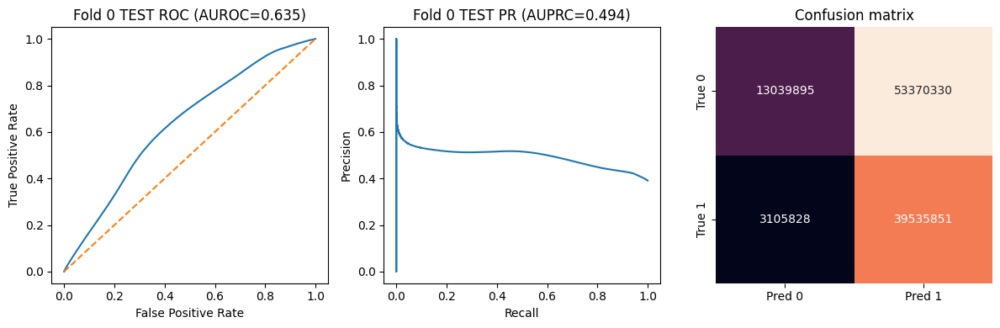


Example tiles (HE / SHG / GT / Pred) for Fold 0


IndexError: index 3 is out of bounds for axis 0 with size 1

In [ ]:
def build_loaders_for_fold(
        DATA_ROOT,
        fold_info,
        input_mod="SHG",
        batch_size=1,
        num_workers=0):

    train_patients = fold_info["train_patients"]
    val_patients   = fold_info["val_patients"]
    test_patients  = fold_info["test_patients"]

    # ---- datasets (no pos_frac_thresh anymore) ----
    train_ds = TILDensityDataset(
        DATA_ROOT,
        patients=train_patients,
        input_mod=input_mod,
        augment=True
    )

    val_ds = TILDensityDataset(
        DATA_ROOT,
        patients=val_patients,
        input_mod=input_mod,
        augment=False
    )

    test_ds = TILDensityDataset(
        DATA_ROOT,
        patients=test_patients,
        input_mod=input_mod,
        augment=False
    )

    # ---- loaders ----
    train_loader = torch.utils.data.DataLoader(
        train_ds, batch_size=batch_size, shuffle=True,
        num_workers=num_workers, pin_memory=True
    )

    val_loader = torch.utils.data.DataLoader(
        val_ds, batch_size=batch_size, shuffle=False,
        num_workers=num_workers, pin_memory=True
    )

    test_loader = torch.utils.data.DataLoader(
        test_ds, batch_size=batch_size, shuffle=False,
        num_workers=num_workers, pin_memory=True
    )

    return train_loader, val_loader, test_loader, train_ds, val_ds, test_ds



results = []

for fold_idx in range(3):
    ckpt_path = f"/content/models/best_model_fold{fold_idx}.pt"  # adjust if stored elsewhere
    print(f"\n================ Fold {fold_idx} =================")

    # ---- get test_loader for this fold ----
    train_patients, val_patients, test_patients = get_fold_splits(fold_idx)
    fold_info = {
        "id": fold_idx,
        "train_patients": train_patients,
        "val_patients": val_patients,
        "test_patients": test_patients,
    }

    # we only really need test_loader, but build_loaders_for_fold returns all three
    train_loader, val_loader, test_loader, train_ds, val_ds, test_ds = \
        build_loaders_for_fold(
            DATA_ROOT,
            fold_info,
            input_mod=INPUT_MODALITY,   # "HE+SHG"
            batch_size=1,               # for eval & visualization
            num_workers=0
        )

    # ---- load model ----
    ckpt = torch.load(ckpt_path, map_location=DEVICE, weights_only=False)
    print("Loaded epoch:", ckpt["epoch"])


    model = AttnUNet(in_ch=1, out_ch=1, base_ch=32, dropout_p=0.2).to(DEVICE)
    model.load_state_dict(ckpt["model_state"])

    # ---- collect predictions on TEST ----
    scores, labels, patient_til_pct, g_true_pct, g_pred_pct = \
        collect_predictions_and_til(model, test_loader, DEVICE)

    print("\nGlobal %TIL (test):")
    print(f"  True: {g_true_pct:.4f}%  |  Pred: {g_pred_pct:.4f}%")

    print("\nPer-patient %TIL (test):")
    for pt, vals in patient_til_pct.items():
        print(f"  {pt:25s} -> true {vals['true_pct']:.4f}%  |  pred {vals['pred_pct']:.4f}%")

    # ---- ROC, PR, confusion matrix ----
    best_thr, auroc, auprc = plot_roc_pr_confusion(
        scores, labels, title_prefix=f"Fold {fold_idx} TEST"
    )

    # ---- visualize some tiles ----
    print("\nExample tiles (HE / SHG / GT / Pred) for Fold", fold_idx)
    visualize_random_tiles(model, test_loader, DEVICE,
                           n_tiles=4, thr_for_vis=best_thr)

    results.append({
        "fold": fold_idx,
        "auroc": auroc,
        "auprc": auprc,
        "global_true_pct": g_true_pct,
        "global_pred_pct": g_pred_pct,
    })

print("\n=========== Summary over folds ===========")
for r in results:
    print(
        f"Fold {r['fold']}: AUROC={r['auroc']:.4f}, AUPRC={r['auprc']:.4f}, "
        f"global %TIL true={r['global_true_pct']:.4f}%, pred={r['global_pred_pct']:.4f}%"
    )


In [ ]:
import numpy as np
import torch
from collections import defaultdict
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import matplotlib.pyplot as plt

@torch.no_grad()
def evaluate_regression(model, loader, device):
    model.eval()

    # --- pixel-level stats ---
    all_true_pix = []
    all_pred_pix = []

    # --- patch-level stats (mean density per tile) ---
    patch_true = []
    patch_pred = []

    # --- patient-level stats ---
    patient_true_sum = defaultdict(float)
    patient_pred_sum = defaultdict(float)
    patient_npix      = defaultdict(int)

    for xb, yb, meta in loader:
        xb = xb.to(device, non_blocking=True)        # [B,C,H,W]
        yb = yb.to(device, non_blocking=True)        # [B,1,H,W], TIL_DEN in [0,1]

        logits = model(xb)
        probs  = torch.sigmoid(logits)               # [B,1,H,W] predicted density

        # pixel-level
        all_true_pix.append(yb.view(-1).cpu().numpy())
        all_pred_pix.append(probs.view(-1).cpu().numpy())

        # patch-level
        gt_mean   = yb.mean(dim=(1,2,3)).cpu().numpy()     # [B]
        pred_mean = probs.mean(dim=(1,2,3)).cpu().numpy()  # [B]
        patch_true.extend(gt_mean.tolist())
        patch_pred.extend(pred_mean.tolist())

        # patient-level aggregation
        if isinstance(meta, dict):
            patients_batch = meta["patient"]
        else:
            patients_batch = [m["patient"] for m in meta]

        B = xb.size(0)
        for i in range(B):
            pt  = str(patients_batch[i])
            gt_i   = yb[i,0].cpu().numpy()
            pred_i = probs[i,0].cpu().numpy()

            patient_true_sum[pt] += float(gt_i.sum())
            patient_pred_sum[pt] += float(pred_i.sum())
            patient_npix[pt]     += gt_i.size

    # concat pixel arrays
    all_true_pix = np.concatenate(all_true_pix)
    all_pred_pix = np.concatenate(all_pred_pix)

    # --- compute metrics ---

    def corr_pearson(y_true, y_pred):
        if len(y_true) < 2:
            return np.nan
        return float(np.corrcoef(y_true, y_pred)[0,1])

    # pixel-level
    pix_mae  = mean_absolute_error(all_true_pix, all_pred_pix)
    pix_rmse = np.sqrt(mean_squared_error(all_true_pix, all_pred_pix))
    pix_r2   = r2_score(all_true_pix, all_pred_pix)
    pix_r    = corr_pearson(all_true_pix, all_pred_pix)

    # patch-level
    patch_true_arr = np.array(patch_true)
    patch_pred_arr = np.array(patch_pred)
    patch_mae  = mean_absolute_error(patch_true_arr, patch_pred_arr)
    patch_rmse = np.sqrt(mean_squared_error(patch_true_arr, patch_pred_arr))
    patch_r2   = r2_score(patch_true_arr, patch_pred_arr)
    patch_r    = corr_pearson(patch_true_arr, patch_pred_arr)

    # patient-level (%TIL)
    patient_ids = sorted(patient_npix.keys())
    patient_true_pct = []
    patient_pred_pct = []
    for pt in patient_ids:
        total_pix = patient_npix[pt]
        t_sum = patient_true_sum[pt]
        p_sum = patient_pred_sum[pt]
        patient_true_pct.append(t_sum / max(1,total_pix))
        patient_pred_pct.append(p_sum / max(1,total_pix))

    patient_true_pct = np.array(patient_true_pct)
    patient_pred_pct = np.array(patient_pred_pct)

    pat_mae  = mean_absolute_error(patient_true_pct, patient_pred_pct)
    pat_rmse = np.sqrt(mean_squared_error(patient_true_pct, patient_pred_pct))
    pat_r2   = r2_score(patient_true_pct, patient_pred_pct)
    pat_r    = corr_pearson(patient_true_pct, patient_pred_pct)

    metrics = {
        "pixel":   {"MAE": pix_mae,  "RMSE": pix_rmse,  "R2": pix_r2,  "Pearson_r": pix_r},
        "patch":   {"MAE": patch_mae,"RMSE": patch_rmse,"R2": patch_r2,"Pearson_r": patch_r},
        "patient": {"MAE": pat_mae,  "RMSE": pat_rmse,  "R2": pat_r2,  "Pearson_r": pat_r},
        "patient_ids": patient_ids,
        "patient_true_pct": patient_true_pct,
        "patient_pred_pct": patient_pred_pct,
        "patch_true": patch_true_arr,
        "patch_pred": patch_pred_arr,
    }

    return metrics

In [ ]:
metrics_fold1 = evaluate_regression(model, test_loader, DEVICE)
print("Pixel-level:",   metrics_fold1["pixel"])
print("Patch-level:",   metrics_fold1["patch"])
print("Patient-level:", metrics_fold1["patient"])


Pixel-level: {'MAE': 0.23423252999782562, 'RMSE': np.float64(0.32662907838884736), 'R2': -14.828911781311035, 'Pearson_r': 0.22997742980780103}
Patch-level: {'MAE': 0.2310500479952099, 'RMSE': np.float64(0.3050314872427926), 'R2': -85.50980750149839, 'Pearson_r': 0.4485751285048153}
Patient-level: {'MAE': 0.18954592460687864, 'RMSE': np.float64(0.25654441331893707), 'R2': -1004.1610715019233, 'Pearson_r': 1.0}


In [ ]:
true_pat = metrics_fold1["patient_true_pct"]
pred_pat = metrics_fold1["patient_pred_pct"]
patient_ids = metrics_fold1["patient_ids"]

plt.figure(figsize=(5,5))
plt.scatter(true_pat, pred_pat)
plt.plot([0,1],[0,1],'k--',alpha=0.5)
plt.xlabel("GT mean TIL density per patient")
plt.ylabel("Pred mean TIL density per patient")
plt.title("Fold 1 – patient-level TIL prediction")
for t,p,pt in zip(true_pat, pred_pat, patient_ids):
    plt.text(t, p, pt.split("_")[0], fontsize=8)  # short patient tag
plt.tight_layout()
plt.show()


NameError: name 'metrics_fold1' is not defined

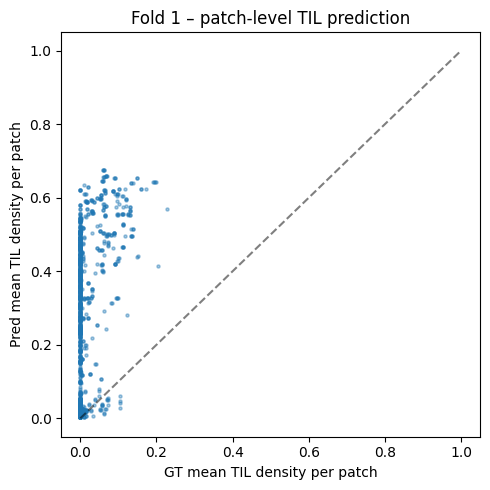

In [ ]:
true_patch = metrics_fold1["patch_true"]
pred_patch = metrics_fold1["patch_pred"]

plt.figure(figsize=(5,5))
plt.scatter(true_patch, pred_patch, s=5, alpha=0.4)
plt.plot([0,1],[0,1],'k--',alpha=0.5)
plt.xlabel("GT mean TIL density per patch")
plt.ylabel("Pred mean TIL density per patch")
plt.title("Fold 1 – patch-level TIL prediction")
plt.tight_layout()
plt.show()


In [ ]:
def occlusion_explainer(model, x, patch=64, stride=64):
    """
    x: (1,C,H,W) on CUDA
    Returns attribution map: (C,H,W)
    """

    assert x.is_cuda, "Input x must be moved to CUDA!"
    model.eval()

    _, C, H, W = x.shape

    attr = torch.zeros((C, H, W), device=x.device)

    # baseline prediction
    with torch.no_grad():
        baseline = model(x)[0,0].detach()

    # occlusion loop
    for y in range(0, H, stride):
        for z in range(0, W, stride):

            # copy X
            x_occ = x.clone()

            # apply occlusion (zero-out)
            y2 = min(y + patch, H)
            z2 = min(z + patch, W)
            x_occ[:,:, y:y2, z:z2] = 0.0

            with torch.no_grad():
                out_occ = model(x_occ)[0,0]

            diff = (baseline - out_occ).abs()

            # store difference in attribution map
            attr[:, y:y2, z:z2] += diff[y:y2, z:z2]

    # normalize attribution
    attr = (attr - attr.min()) / (attr.max() + 1e-8)

    return attr


In [ ]:
import torch
from pathlib import Path
from collections import defaultdict
import random
import cv2
import numpy as np
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler

# Assuming DEVICE, AttnUNet, INPUT_MODALITY, PATIENT_CODES, N_PATIENTS
# DATA_ROOT, TILDensityDataset, get_fold_splits, build_loaders_for_fold are available from previous cells.

# ================== IO HELPERS (copied from NcCsmEWZwy9d) ==================
def read_rgb(path: Path):
    img = cv2.imread(str(path), cv2.IMREAD_COLOR)
    if img is None:
        raise IOError(f"Could not read image: {path}")
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    return img

def read_gray(path: Path):
    img = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)
    if img is None:
        raise IOError(f"Could not read image: {path}")
    return img

# ================== DATASET (copied from NcCsmEWZwy9d) ==================
class TILDensityDataset(Dataset):
    """
    Dataset for patient-wise HE + SHG + TIL_DEN patches at 512x512.

    Layout:
      root/
        [patient_code]/
          HE/*.png
          SHG/*.png
          TIL_DEN/*.png

    We use TIL_DEN patches as labels; filenames are identical across modalities.
    """

    def __init__(self,
                 root: Path,
                 patients,
                 input_mod: str = "SHG",
                 mask_mode: str = "density",
                 augment: bool = False):
        super().__init__()
        assert input_mod in ("HE", "SHG", "HE+SHG")
        assert mask_mode in ("binary", "density")

        self.root      = Path(root)
        self.patients  = list(patients)
        self.input_mod = input_mod
        self.mask_mode = mask_mode
        self.augment   = augment

        self.samples = []
        self.has_pos = []   # tile-level "any positive pixel" label

        for patient in self.patients:
            p_dir = self.root / patient
            he_dir  = p_dir / "HE"
            shg_dir = p_dir / "SHG"
            til_dir = p_dir / "TIL_DEN"

            if not til_dir.exists():
                print(f"  [WARN] No TIL_DEN folder for {patient}, skipping patient.")
                continue

            til_files = sorted(til_dir.glob("*.png"))
            print(f"[{patient}] Found {len(til_files)} TIL_DEN patches.")

            for t_path in til_files:
                fname = t_path.name

                he_path  = he_dir  / fname
                shg_path = shg_dir / fname

                ok = True
                if self.input_mod in ("HE", "HE+SHG") and not he_path.exists():
                    print(f"  [WARN] Missing HE for {patient}/{fname}, skipping.")
                    ok = False
                if self.input_mod in ("SHG", "HE+SHG") and not shg_path.exists():
                    print(f"  [WARN] Missing SHG for {patient}/{fname}, skipping.")
                    ok = False
                if not ok:
                    continue

                # compute has_pos once
                m_np = read_gray(t_path).astype(np.float32)
                pos_mask = (m_np > 0).astype(np.float32)
                has_pos = bool(pos_mask.sum() > 0)

                self.samples.append({
                    "patient": patient,
                    "name":    fname,
                    "he":      he_path if he_path.exists() else None,
                    "shg":     shg_path if shg_path.exists() else None,
                    "til":     t_path,
                })
                self.has_pos.append(has_pos)

        n_all = len(self.samples)
        n_pos = int(sum(self.has_pos))
        print(f"[DATASET] Loaded {n_all} tiles from {len(self.patients)} patients,"
              f" {n_pos} ({100.0*n_pos/max(1,n_all):.2f}%) tiles with TIL > 0.")

        # per-patient stats
        per_patient = defaultdict(lambda: [0, 0])  # [pos, total]
        for s, h in zip(self.samples, self.has_pos):
            pt = s["patient"]
            per_patient[pt][1] += 1
            if h:
                per_patient[pt][0] += 1
        print("  Per patient:")
        for pt in sorted(per_patient.keys()):
            pos, total = per_patient[pt]
            frac = 100.0 * pos / max(1, total)
            print(f"    {pt:20s} -> {pos:4d} / {total:4d} ({frac:6.2f}% positive)")

    def __len__(self):
        return len(self.samples)

    def _augment(self, x, y):
        # x: [C,H,W], y: [1,H,W]
        if random.random() < 0.5:
            x = torch.flip(x, dims=[2])
            y = torch.flip(y, dims=[2])
        if random.random() < 0.5:
            x = torch.flip(x, dims=[1])
            y = torch.flip(y, dims=[1])
        k = random.choice([0, 1, 2, 3])
        if k > 0:
            x = torch.rot90(x, k, dims=[1, 2])
            y = torch.rot90(y, k, dims=[1, 2])
        return x, y

    def __getitem__(self, idx):
        s = self.samples[idx]
        patient = s["patient"]
        name    = s["name"]

        # ---------- label (TIL_DEN) ----------
        mask_np = read_gray(s["til"]).astype(np.float32)

        if self.mask_mode == "binary":
            mask_np = (mask_np > 0).astype(np.float32)
        else:  # "density"
            mn, mx = mask_np.min(), mask_np.max()
            if mx > mn:
                mask_np = (mask_np - mn) / (mx - mn)
            else:
                mask_np = np.zeros_like(mask_np, dtype=np.float32)

        mask_t = torch.from_numpy(mask_np)[None, ...]  # [1,H,W]

        # ---------- inputs ----------
        if self.input_mod == "HE":
            he = read_rgb(s["he"]).astype(np.float32) / 255.0
            x_np = np.transpose(he, (2, 0, 1))  # [3,H,W]

        elif self.input_mod == "SHG":
            shg = read_gray(s["shg"]).astype(np.float32)
            mn, mx = shg.min(), shg.max()
            if mx > mn:
                shg = (shg - mn) / (mx - mn)
            else:
                shg = np.zeros_like(shg, dtype=np.float32)
            x_np = shg[None, ...]

        else:  # "HE+SHG"
            he = read_rgb(s["he"]).astype(np.float32) / 255.0
            he_chw = np.transpose(he, (2, 0, 1))  # [3,H,W]

            shg = read_gray(s["shg"]).astype(np.float32)
            mn, mx = shg.min(), shg.max()
            if mx > mn:
                shg = (shg - mn) / (mx - mn)
            else:
                shg = np.zeros_like(shg, dtype=np.float32)
            shg_ch = shg[None, ...]

            x_np = np.concatenate([he_chw, shg_ch], axis=0)  # [4,H,W]

        x_t = torch.from_numpy(x_np).float()

        if self.augment:
            x_t, mask_t = self._augment(x_t, mask_t)

        meta = {"patient": patient, "name": name}
        return x_t, mask_t, meta

# ================== PATIENT SPLITS (3 folds) (copied from NcCsmEWZwy9d) ==================
N_PATIENTS = len(PATIENT_CODES) # Define N_PATIENTS
def get_fold_splits(fold_idx: int):
    """
    3 folds, each with:
      a flexible number of train patients (total - 4)
      2 val patients
      2 test patients
    Patients are taken from PATIENT_CODES (sorted).
    """
    assert 0 <= fold_idx < 3

    # The original base calculation (3 * fold_idx) % N_PATIENTS works well
    # for rotating test and validation sets across folds for N_PATIENTS=8.
    base = (3 * fold_idx) % N_PATIENTS

    test_indices = [base % N_PATIENTS,
                    (base + 1) % N_PATIENTS]
    val_indices  = [(base + 2) % N_PATIENTS,
                    (base + 3) % N_PATIENTS]

    test_patients = [PATIENT_CODES[i] for i in test_indices]
    val_patients  = [PATIENT_CODES[i] for i in val_indices]

    test_set = set(test_patients)
    val_set  = set(val_patients)
    train_patients = [p for p in PATIENT_CODES
                      if p not in test_set and p not in val_set]

    # This assertion now correctly reflects the number of training patients given N_PATIENTS
    assert len(train_patients) == N_PATIENTS - 4, f"Expected {N_PATIENTS - 4} train patients, got {len(train_patients)}"
    assert len(val_patients) == 2
    assert len(test_patients) == 2

    print(f"\n===== Fold {fold_idx} =====")
    print("  Train patients:", train_patients)
    print("  Val patients:  ", val_patients)
    print("  Test patients: ", test_patients)

    return train_patients, val_patients, test_patients

# ================== BUILD DATALOADERS PER FOLD (copied from iWGuKacXrEN3) ==================
def build_loaders_for_fold(root, fold_info, input_mod="SHG",
                           batch_size=1, num_workers=0):
    train_patients = fold_info["train_patients"]
    val_patients   = fold_info["val_patients"]
    test_patients  = fold_info["test_patients"]

    print("===== Fold", fold_info["id"], "=====")
    print(" Train patients:", train_patients)
    print(" Val patients:  ", val_patients)
    print(" Test patients: ", test_patients)

    train_ds = TILDensityDataset(root, train_patients,
                               input_mod=input_mod,
                               augment=True,
                               mask_mode="density")
    val_ds   = TILDensityDataset(root, val_patients,
                               input_mod=input_mod,
                               augment=False,
                               mask_mode="density")
    test_ds  = TILDensityDataset(root, test_patients,
                               input_mod=input_mod,
                               augment=False,
                               mask_mode="density")

    sample_weights = torch.tensor(
        [1.0 if hp else 1.0 for hp in train_ds.has_pos],
        dtype=torch.float
    )
    sampler = WeightedRandomSampler(
        weights=sample_weights,
        num_samples=len(sample_weights),
        replacement=True
    )

    train_loader = DataLoader(
        train_ds,
        batch_size=batch_size,
        sampler=sampler,
        num_workers=num_workers,
        pin_memory=True,
        persistent_workers=False
    )
    val_loader = DataLoader(
        val_ds,
        batch_size=1,
        shuffle=False,
        num_workers=num_workers,
        pin_memory=True,
        persistent_workers=False
    )
    test_loader = DataLoader(
        test_ds,
        batch_size=1,
        shuffle=False,
        num_workers=num_workers,
        pin_memory=True,
        persistent_workers=False
    )

    xb, yb, meta = next(iter(train_loader))
    print("  Example train batch:", xb.shape, yb.shape)
    if isinstance(meta, dict):
        print("  Example tile:", meta["patient"][0], meta["name"][0])
    else:
        print("  Example tile:", meta[0]["patient"], meta[0]["name"])

    return train_loader, val_loader, test_loader, train_ds, val_ds, test_ds

# Define FOLD_IDX for this evaluation (since the error occurred for fold 2 during previous execution)
EVAL_FOLD_IDX = 1

# Build loaders for the specific fold to get test_ds
train_patients, val_patients, test_patients = get_fold_splits(EVAL_FOLD_IDX)
fold_info = {
    "id": EVAL_FOLD_IDX,
    "train_patients": train_patients,
    "val_patients": val_patients,
    "test_patients": test_patients,
}

_, _, _, _, _, test_ds = \
    build_loaders_for_fold(
        DATA_ROOT,
        fold_info,
        input_mod=INPUT_MODALITY,
        batch_size=1, # Use batch_size=1 for individual tile processing
        num_workers=0
    )

# 1. Load model
# Determine in_ch based on INPUT_MODALITY
if INPUT_MODALITY == "HE":
    in_ch_model = 3
elif INPUT_MODALITY == "SHG":
    in_ch_model = 1
else: # Default to HE+SHG
    in_ch_model = 4

model = AttnUNet(in_ch=in_ch_model, out_ch=1, base_ch=32)
ckpt = torch.load("/content/models/best_model_fold0.pt", map_location="cpu", weights_only=False)
model.load_state_dict(ckpt["model_state"])
model = model.to("cuda").eval()

# 2. Get tile from fold 2 test dataset
x, y, meta = test_ds[1]    # x: (C,H,W)

# 3. Move input to GPU
x = x.unsqueeze(0).to("cuda")   # shape (1,4,512,512)

# 4. Run occlusion SHAP
attr_map = occlusion_explainer(model, x, patch=64, stride=64)

print("Attribution map shape:", attr_map.shape)
print("Min/Max:", float(attr_map.min()), float(attr_map.max()))



===== Fold 1 =====
  Train patients: ['BCRAA4SF_band_overlap', 'BCRAA22D_band_overlap', 'BCRAA0SF_band_overlap', 'BCRAA0CK_band_overlap', 'BCRAA04Y_band_overlap', 'BCRAA0AY_band_overlap', 'BCRAA0BG_band_overlap', 'BCRAA0C1_band_overlap', 'BCRAA0CK_band_overlap', 'BCRAA0IP_band_overlap', 'BCRAA0JI_band_overlap', 'BCRAA0SD_band_overlap', 'BCRAA0SI_band_overlap', 'BCRAA0SH_band_overlap', 'BCRAA0SM_band_overlap', 'BCRAA0SP_band_overlap', 'BCRAA0SQ_band_overlap', 'BCRAA1FC_band_overlap', 'BCRAA278_band_overlap', 'BCRAA2LE_band_overlap', 'BCRAA3OD_band_overlap', 'BCRAA3Y0_band_overlap', 'BCRAA3YJ_band_overlap', 'BCRAA4S2_band_overlap', 'BCRAAB41_band_overlap', 'BCRAA1LI_band_overlap']
  Val patients:   ['BCRAA2DA_band_overlap', 'BCRAA74U_band_overlap']
  Test patients:  ['BCRAA5DD_band_overlap', 'BCRAA0YC_band_overlap']
===== Fold 1 =====
 Train patients: ['BCRAA4SF_band_overlap', 'BCRAA22D_band_overlap', 'BCRAA0SF_band_overlap', 'BCRAA0CK_band_overlap', 'BCRAA04Y_band_overlap', 'BCRAA0AY_b

In [ ]:
import torch
import matplotlib.pyplot as plt
import numpy as np

# 1. Load model
model = AttUNet(img_ch=1, output_ch=1, base_ch=32)
ckpt = torch.load("/content/models_shg_attunet_cont/best_shg_attunet_single_split.pt", map_location="cpu", weights_only=False)
model.load_state_dict(ckpt["model_state"])
model = model.to("cuda").eval()

# 2. Get tile from fold 2 test dataset
x, y, meta = test_ds[1]    # x: (C,H,W), y: (1,H,W) on CPU

print("Tile:", meta["patient"], meta["name"])

# 3. Move input to GPU
x_gpu = x.unsqueeze(0).to("cuda")   # shape (1,4,512,512)

# 4. Forward pass to get predicted TIL density
with torch.no_grad():
    pred = torch.sigmoid(model(x_gpu))          # (1,1,H,W)

# 5. Run occlusion SHAP
attr_map = occlusion_explainer(model, x_gpu, patch=64, stride=64)

print("Attribution map shape:", attr_map.shape)
print("Min/Max:", float(attr_map.min()), float(attr_map.max()))

# --------- prepare arrays for plotting ----------
x_np   = x.numpy()                     # (4,H,W) on CPU
he_np  = np.transpose(x_np[:3], (1, 2, 0))  # (H,W,3)
shg_np = x_np[0]                       # (H,W)

gt_np    = y.numpy()[0]                      # (H,W)
pred_np  = pred.detach().cpu().numpy()[0, 0] # (H,W)

# attr_map could be torch or numpy; make sure it's numpy
if isinstance(attr_map, torch.Tensor):
    # Corrected: Sum across the channel dimension (dim=0) to get a 2D array (H,W)
    attr_np = attr_map.sum(dim=0).detach().cpu().numpy()
else:
    # Assuming attr_map is already a numpy array of shape (C,H,W)
    attr_np = attr_map.sum(axis=0) # sum along channel axis

# --------- plot HE, SHG, GT TIL, Pred TIL, Occlusion ----------
fig, axes = plt.subplots(1, 5, figsize=(20, 4))

axes[0].imshow(np.clip(he_np, 0, 1))
axes[0].set_title("HE input")
axes[0].axis("off")

axes[1].imshow(shg_np, cmap="gray")
axes[1].set_title("SHG input")
axes[1].axis("off")

im2 = axes[2].imshow(gt_np, cmap="magma")
axes[2].set_title("GT TIL density")
axes[2].axis("off")
fig.colorbar(im2, ax=axes[2], fraction=0.046, pad=0.04)

im3 = axes[3].imshow(pred_np, cmap="magma")
axes[3].set_title("Pred TIL density")
axes[3].axis("off")
fig.colorbar(im3, ax=axes[3], fraction=0.046, pad=0.04)

im4 = axes[4].imshow(attr_np, cmap="coolwarm")
axes[4].set_title("Occlusion attribution")
axes[4].axis("off")
fig.colorbar(im4, ax=axes[4], fraction=0.046, pad=0.04)

plt.tight_layout()
plt.show()


NameError: name 'test_ds' is not defined

Showing random tile #380: patient=BCRAA0YC_band_overlap, name=BCRAA0YC_band_overlap_patch_0012_y512_x0.png


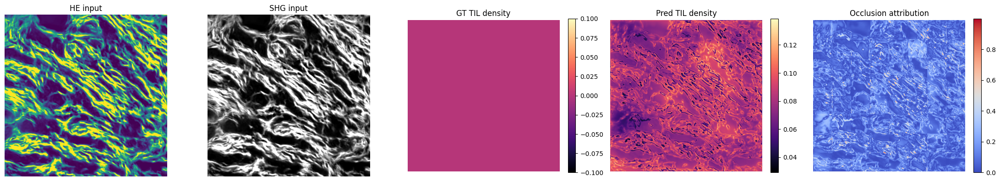

In [ ]:
import random
import torch
import numpy as np
import matplotlib.pyplot as plt

# Pick a random tile index from the test dataset
idx = random.randint(0, len(test_ds)-1)
x, y, meta = test_ds[idx]

print(f"Showing random tile #{idx}: patient={meta['patient']}, name={meta['name']}")

# Move input to GPU for model + occlusion
x_gpu = x.unsqueeze(0).to("cuda")

# ---- Prediction ----
with torch.no_grad():
    pred = torch.sigmoid(model(x_gpu))    # (1,1,H,W)

# ---- Occlusion attribution ----
attr_map = occlusion_explainer(model, x_gpu, patch=64, stride=64)

# ---- Prepare arrays for plotting ----
x_np   = x.numpy()                           # (4,H,W)
he_np  = np.transpose(x_np[:3], (1, 2, 0))    # (H,W,3)
shg_np = x_np[0]                              # (H,W)
gt_np    = y.numpy()[0]                       # (H,W)
pred_np  = pred.cpu().numpy()[0, 0]           # (H,W)

# ---- Fix attribution shape ----
if isinstance(attr_map, torch.Tensor):
    attr_np = attr_map.sum(dim=0).detach().cpu().numpy() # Sum across channel dimension to get (H,W)
else:
    # Assuming attr_map is already a numpy array of shape (C,H,W)
    attr_np = attr_map.sum(axis=0) # sum along channel axis to get (H,W)

# ---- Plot 5 panels ----
fig, axes = plt.subplots(1, 5, figsize=(22, 4))

# HE
axes[0].imshow(np.clip(he_np, 0, 1))
axes[0].set_title("HE input")
axes[0].axis("off")

# SHG
axes[1].imshow(shg_np, cmap="gray")
axes[1].set_title("SHG input")
axes[1].axis("off")

# GT TIL
im2 = axes[2].imshow(gt_np, cmap="magma")
axes[2].set_title("GT TIL density")
axes[2].axis("off")
fig.colorbar(im2, ax=axes[2], fraction=0.046)

# Pred TIL
im3 = axes[3].imshow(pred_np, cmap="magma")
axes[3].set_title("Pred TIL density")
axes[3].axis("off")
fig.colorbar(im3, ax=axes[3], fraction=0.046)

# Occlusion attribution
im4 = axes[4].imshow(attr_np, cmap="coolwarm")
axes[4].set_title("Occlusion attribution")
axes[4].axis("off")
fig.colorbar(im4, ax=axes[4], fraction=0.046)

plt.tight_layout()
plt.show()


Collected rows: 512


,patient,patch,fiber_mean,fiber_std,pred_TIL_mass,gt_TIL_mass
0,BCRAA5DD_band_overlap,BCRAA5DD_band_overlap_patch_0008_y0_x0.png,0.325626,0.231070,20157.683594,6138.850098
1,BCRAA5DD_band_overlap,BCRAA5DD_band_overlap_patch_0008_y0_x1024.png,0.319150,0.241213,18001.398438,1056.000122
2,BCRAA5DD_band_overlap,BCRAA5DD_band_overlap_patch_0008_y0_x1536.png,0.252282,0.217614,19410.683594,25658.246094
3,BCRAA5DD_band_overlap,BCRAA5DD_band_overlap_patch_0008_y0_x512.png,0.316922,0.230247,18044.277344,0.000000
4,BCRAA5DD_band_overlap,BCRAA5DD_band_overlap_patch_0008_y1024_x0.png,0.183552,0.156047,18300.234375,15776.547852



Linear regression:  pred_TIL_mass = a * fiber_mean + b
  a (slope)  = -1.294e+04
  b          = 2.262e+04
  R^2        = 0.1416
  p-value    = 1.156e-18

Spearman correlation:
  rho        = -0.3736
  p-value    = 2.079e-18


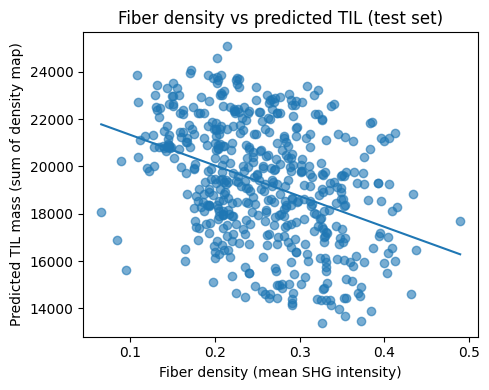

Saved: fiber_TIL_regression_testset.csv


In [ ]:
import torch
import numpy as np
import pandas as pd
from torch.utils.data import DataLoader
from scipy.stats import linregress, spearmanr
import matplotlib.pyplot as plt

# -------------------------------------------------
# Setup
# -------------------------------------------------
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = model.to(DEVICE).eval()

# DataLoader over test set (batch_size=1 so we can keep meta info)
test_loader = DataLoader(test_ds, batch_size=1, shuffle=False, num_workers=0)

records = []

# -------------------------------------------------
# Loop over entire test set
# -------------------------------------------------
with torch.no_grad():
    for x, y, meta in test_loader:
        # x: (1,C,H,W), y: (1,1,H,W)
        x_dev = x.to(DEVICE)
        pred = torch.sigmoid(model(x_dev))          # (1,1,H,W)

        # ----- Predicted T-cell "mass" (integrated density) -----
        pred_mass = float(pred.sum().cpu().item())

        # ----- GT mass (optional, nice to have) -----
        gt_mass = float(y.sum().cpu().item())

        # ----- Fiber density from SHG -----
        # bring to numpy, remove batch dim -> (C,H,W)
        x_np = x.squeeze(0).numpy()

        # Determine SHG channel:
        #   HE+SHG  -> C=4, SHG is channel 3
        #   SHG-only-> C=1, SHG is channel 0
        if x_np.shape[0] == 4:
            shg = x_np[3]
        elif x_np.shape[0] == 1:
            shg = x_np[0]
        else:
            # if input is HE-only, we can't compute fiber density → skip
            print("Warning: no SHG channel for this sample, skipping.")
            continue

        # SHG in dataset is already 0–1 normalized
        fiber_mean = float(shg.mean())   # main “fiber density” metric
        fiber_std  = float(shg.std())    # optional texture measure

        # ----- Store one row per patch -----
        records.append({
            "patient":       meta["patient"][0],
            "patch":         meta["name"][0],
            "fiber_mean":    fiber_mean,
            "fiber_std":     fiber_std,
            "pred_TIL_mass": pred_mass,
            "gt_TIL_mass":   gt_mass,
        })

# -------------------------------------------------
# Build DataFrame
# -------------------------------------------------
df = pd.DataFrame.from_records(records)
print("Collected rows:", len(df))
display(df.head())

# -------------------------------------------------
# Regression: fiber density vs predicted TIL mass
# -------------------------------------------------
x_var = df["fiber_mean"].values
y_var = df["pred_TIL_mass"].values

lin = linregress(x_var, y_var)
rho, spearman_p = spearmanr(x_var, y_var)

print("\nLinear regression:  pred_TIL_mass = a * fiber_mean + b")
print(f"  a (slope)  = {lin.slope:.4g}")
print(f"  b          = {lin.intercept:.4g}")
print(f"  R^2        = {lin.rvalue**2:.4f}")
print(f"  p-value    = {lin.pvalue:.3e}")

print("\nSpearman correlation:")
print(f"  rho        = {rho:.4f}")
print(f"  p-value    = {spearman_p:.3e}")

# -------------------------------------------------
# Scatter + regression line plot
# -------------------------------------------------
plt.figure(figsize=(5, 4))
plt.scatter(x_var, y_var, alpha=0.6)
x_line = np.linspace(x_var.min(), x_var.max(), 100)
y_line = lin.slope * x_line + lin.intercept
plt.plot(x_line, y_line)
plt.xlabel("Fiber density (mean SHG intensity)")
plt.ylabel("Predicted TIL mass (sum of density map)")
plt.title("Fiber density vs predicted TIL (test set)")
plt.tight_layout()
plt.show()

# -------------------------------------------------
# Save to CSV for later analysis / plotting
# -------------------------------------------------
df.to_csv("fiber_TIL_regression_testset.csv", index=False)
print("Saved: fiber_TIL_regression_testset.csv")


In [ ]:
import torch
import numpy as np
import pandas as pd
from torch.utils.data import DataLoader
from skimage.feature import structure_tensor

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = model.to(DEVICE).eval()

test_loader = DataLoader(test_ds, batch_size=1, shuffle=False, num_workers=0)

PRED_TIL_THRESH = 0.1   # threshold for “predicted T-cell area”

def compute_fiber_coherence(shg_img, mask=None, sigma=2.0):
    """
    shg_img: 2D numpy array, assumed already normalized (0–1)
    mask   : 2D boolean or 0/1 array; if provided, coherence is averaged over mask region
    """
    img = shg_img.astype(np.float32)
    Axx, Axy, Ayy = structure_tensor(img, sigma=sigma)

    # Manually calculate eigenvalues from structure tensor components
    # Source: https://scikit-image.org/docs/stable/api/skimage.feature.html#skimage.feature.structure_tensor_eigvals
    # l1, l2 = structure_tensor_eigvals(Axx, Axy, Ayy) # This function is not found

    tmp = np.sqrt((Axx - Ayy)**2 + 4 * Axy**2)
    l1 = 0.5 * (Axx + Ayy + tmp)
    l2 = 0.5 * (Axx + Ayy - tmp)

    # Avoid division by zero where l1 + l2 is zero
    divisor = l1 + l2 + 1e-8
    coherence = (l1 - l2) / divisor   # 0 = isotropic, 1 = highly aligned

    if mask is not None:
        m = mask.astype(bool)
        vals = coherence[m]
    else:
        vals = coherence.ravel()

    return float(vals.mean()) if vals.size > 0 else np.nan

records = []

with torch.no_grad():
    for x, y, meta in test_loader:
        # x: (1,C,H,W), y: (1,1,H,W)
        x_dev = x.to(DEVICE)
        pred  = torch.sigmoid(model(x_dev))          # (1,1,H,W)

        pred_np = pred.cpu().numpy()[0, 0]           # (H,W)
        gt_np   = y.numpy()[0, 0]                    # (H,W)
        x_np    = x.squeeze(0).numpy()               # (C,H,W)

        # ---- SHG channel ----
        if x_np.shape[0] == 4:       # HE+SHG
            shg = x_np[3]
        elif x_np.shape[0] == 1:     # SHG-only
            shg = x_np[0]
        else:
            print("Warning: no SHG channel for this sample, skipping.")
            continue

        # predicted T-cell area mask
        pred_mask = (pred_np > PRED_TIL_THRESH).astype(np.uint8)

        # fiber coherence metrics
        coh_full      = compute_fiber_coherence(shg, mask=None,       sigma=2.0)
        coh_pred_area = compute_fiber_coherence(shg, mask=pred_mask,  sigma=2.0)

        # integrated TIL “mass”
        pred_mass = float(pred_np.sum())
        gt_mass   = float(gt_np.sum())

        records.append({
            "patient":          meta["patient"][0],
            "patch":            meta["name"][0],
            "fiber_mean":       float(shg.mean()),
            "fiber_std":        float(shg.std()),
            "coh_full":         coh_full,
            "coh_pred_area":    coh_pred_area,
            "pred_TIL_mass":    pred_mass,
            "gt_TIL_mass":      gt_mass,
        })

df_align = pd.DataFrame.from_records(records)
print("Rows:", len(df_align))
display(df_align.head())

print("\nSummary of coherence at predicted T-cell area:")
print(df_align["coh_pred_area"].describe())


Rows: 512


,patient,patch,fiber_mean,fiber_std,coh_full,coh_pred_area,pred_TIL_mass,gt_TIL_mass
0,BCRAA5DD_band_overlap,BCRAA5DD_band_overlap_patch_0008_y0_x0.png,0.325626,0.231070,0.625953,0.645782,20157.683594,6138.850098
1,BCRAA5DD_band_overlap,BCRAA5DD_band_overlap_patch_0008_y0_x1024.png,0.319150,0.241213,0.634664,0.678961,18001.396484,1056.000000
2,BCRAA5DD_band_overlap,BCRAA5DD_band_overlap_patch_0008_y0_x1536.png,0.252282,0.217614,0.625083,0.640098,19410.683594,25658.244141
3,BCRAA5DD_band_overlap,BCRAA5DD_band_overlap_patch_0008_y0_x512.png,0.316922,0.230247,0.624853,0.715490,18044.273438,0.000000
4,BCRAA5DD_band_overlap,BCRAA5DD_band_overlap_patch_0008_y1024_x0.png,0.183552,0.156047,0.585611,0.687581,18300.234375,15776.546875



Summary of coherence at predicted T-cell area:
count    512.000000
mean       0.699629
std        0.043382
min        0.502892
25%        0.669778
50%        0.697374
75%        0.728643
max        0.838551
Name: coh_pred_area, dtype: float64


In [ ]:
import torch
import numpy as np
import pandas as pd
from torch.utils.data import DataLoader
from skimage.feature import structure_tensor
from pathlib import Path

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = model.to(DEVICE).eval()

test_loader = DataLoader(test_ds, batch_size=1, shuffle=False, num_workers=0)
PRED_TIL_THRESH = 0.1   # threshold for “predicted T-cell area”

# ---- eigenvalues for 2x2 structure tensor ----
def structure_tensor_eigvals(Axx, Axy, Ayy):
    tmp  = 0.5 * (Axx + Ayy)
    diff = 0.5 * (Axx - Ayy)
    rad  = np.sqrt(diff**2 + Axy**2)
    l1 = tmp + rad
    l2 = tmp - rad
    return l1, l2

def coherence_map(shg_img, sigma=2.0):
    img = shg_img.astype(np.float32)
    Axx, Axy, Ayy = structure_tensor(img, sigma=sigma)
    l1, l2 = structure_tensor_eigvals(Axx, Axy, Ayy)
    coh = (l1 - l2) / (l1 + l2 + 1e-8)   # 0 = isotropic, 1 = highly aligned
    return coh

records = []

with torch.no_grad():
    for x, y, meta in test_loader:
        # x: (1,C,H,W), y: (1,1,H,W)
        x_dev = x.to(DEVICE)
        pred  = torch.sigmoid(model(x_dev))          # (1,1,H,W)

        pred_np = pred.cpu().numpy()[0, 0]           # (H,W)
        gt_np   = y.numpy()[0, 0]                    # (H,W)
        x_np    = x.squeeze(0).numpy()               # (C,H,W)

        # --- SHG channel ---
        if x_np.shape[0] == 4:       # HE+SHG
            shg = x_np[3]
        elif x_np.shape[0] == 1:     # SHG-only
            shg = x_np[0]
        else:
            continue

        # predicted T-cell area mask
        pred_mask = (pred_np > PRED_TIL_THRESH).astype(np.uint8)
        area_frac = float(pred_mask.mean())          # what fraction of patch is “TIL area”

        # skip patches with essentially no predicted T cells
        if area_frac < 0.01:
            continue

        # global SHG stats
        fiber_mean_full = float(shg.mean())
        fiber_std_full  = float(shg.std())

        # SHG stats inside predicted T-cell area
        shg_pred = shg[pred_mask == 1]
        fiber_mean_pred = float(shg_pred.mean())
        fiber_std_pred  = float(shg_pred.std())

        # coherence maps
        coh_full = coherence_map(shg, sigma=2.0)
        coh_pred = coh_full[pred_mask == 1]

        coh_full_mean = float(np.nanmean(coh_full))
        coh_pred_mean = float(np.nanmean(coh_pred))

        pred_mass = float(pred_np.sum())
        gt_mass   = float(gt_np.sum())

        records.append({
            "patient":          meta["patient"][0],
            "patch":            meta["name"][0],
            "fiber_mean_full":  fiber_mean_full,
            "fiber_std_full":   fiber_std_full,
            "fiber_mean_pred":  fiber_mean_pred,
            "fiber_std_pred":   fiber_std_pred,
            "coh_full":         coh_full_mean,
            "coh_pred":         coh_pred_mean,
            "pred_area_frac":   area_frac,
            "pred_TIL_mass":    pred_mass,
            "gt_TIL_mass":      gt_mass,
        })

df_feat = pd.DataFrame(records)
print("Patches with predicted TIL area:", len(df_feat))
df_feat.head()


Patches with predicted TIL area: 442


,patient,patch,fiber_mean_full,fiber_std_full,fiber_mean_pred,fiber_std_pred,coh_full,coh_pred,pred_area_frac,pred_TIL_mass,gt_TIL_mass
0,BCRAA5DD_band_overlap,BCRAA5DD_band_overlap_patch_0008_y0_x0.png,0.325626,0.231070,0.395289,0.291108,0.625953,0.645782,0.077488,20157.683594,6138.850098
1,BCRAA5DD_band_overlap,BCRAA5DD_band_overlap_patch_0008_y0_x1024.png,0.319150,0.241213,0.461936,0.299774,0.634664,0.678961,0.024918,18001.396484,1056.000000
2,BCRAA5DD_band_overlap,BCRAA5DD_band_overlap_patch_0008_y0_x1536.png,0.252282,0.217614,0.385892,0.282944,0.625083,0.640098,0.046608,19410.683594,25658.244141
3,BCRAA5DD_band_overlap,BCRAA5DD_band_overlap_patch_0008_y0_x512.png,0.316922,0.230247,0.577847,0.315912,0.624853,0.715490,0.014847,18044.273438,0.000000
4,BCRAA5DD_band_overlap,BCRAA5DD_band_overlap_patch_0008_y1024_x0.png,0.183552,0.156047,0.285090,0.230382,0.585611,0.687581,0.036076,18300.234375,15776.546875


cluster
0    189
2    141
1    112
Name: count, dtype: int64


,fiber_mean_pred,fiber_std_pred,coh_pred,pred_area_frac
cluster,,,,
0,0.322194,0.256922,0.695219,0.060524
1,0.462666,0.307896,0.722348,0.041648
2,0.264176,0.211582,0.676073,0.156852


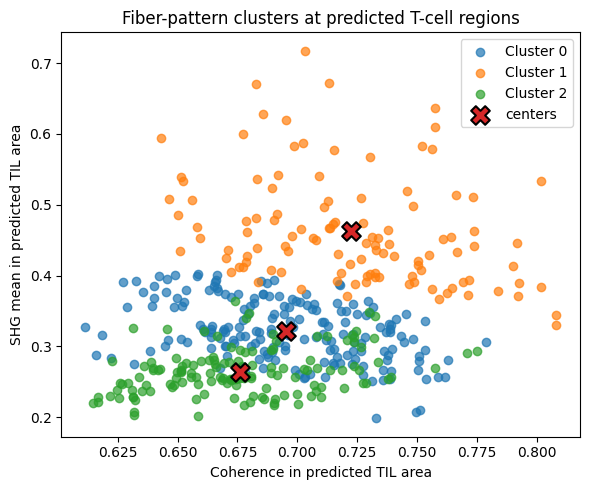

In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
import numpy as np

# -------- choose features for clustering --------
feature_cols = ["fiber_mean_pred", "fiber_std_pred", "coh_pred", "pred_area_frac"]

df_cluster = df_feat.dropna(subset=feature_cols).copy()
X = df_cluster[feature_cols].values

# Standardize
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# K-means (change K if you want more/less clusters)
K = 3
kmeans = KMeans(n_clusters=K, random_state=0, n_init=10)
labels = kmeans.fit_predict(X_scaled)
df_cluster["cluster"] = labels

print(df_cluster["cluster"].value_counts())
display(df_cluster.groupby("cluster")[feature_cols].mean())

# -------- scatter plot of clusters --------
plt.figure(figsize=(6, 5))
for k in range(K):
    sel = (df_cluster["cluster"] == k)
    plt.scatter(df_cluster.loc[sel, "coh_pred"],
                df_cluster.loc[sel, "fiber_mean_pred"],
                alpha=0.7,
                label=f"Cluster {k}")

# also show cluster centers
centers = kmeans.cluster_centers_
centers_inv = scaler.inverse_transform(centers)
plt.scatter(centers_inv[:, feature_cols.index("coh_pred")],
            centers_inv[:, feature_cols.index("fiber_mean_pred")],
            marker="X", s=180, edgecolor="k", linewidth=1.5, label="centers")

plt.xlabel("Coherence in predicted TIL area")
plt.ylabel("SHG mean in predicted TIL area")
plt.title("Fiber-pattern clusters at predicted T-cell regions")
plt.legend()
plt.tight_layout()
plt.show()


Representative rows: [35, 183, 245]


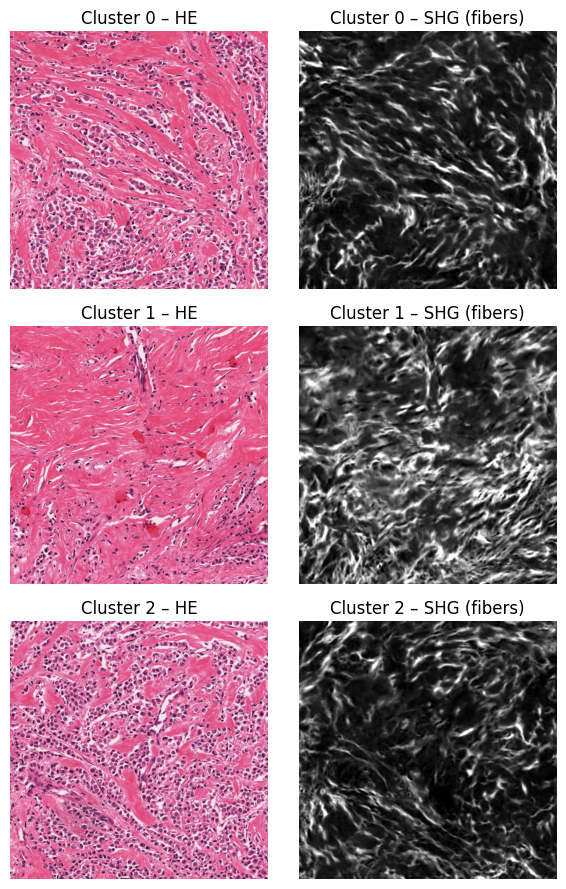

In [ ]:
import cv2

# -------- find representative index for each cluster --------
rep_indices = []

for k in range(K):
    idx_k = np.where(labels == k)[0]
    if len(idx_k) == 0:
        continue
    cluster_pts = X_scaled[idx_k]
    center = kmeans.cluster_centers_[k]

    # Euclidean distance to cluster center
    dists = np.linalg.norm(cluster_pts - center, axis=1)
    nearest_local = idx_k[np.argmin(dists)]

    # original dataframe index
    rep_indices.append(df_cluster.index[nearest_local])

print("Representative rows:", rep_indices)

# -------- plot one HE + SHG pair per cluster --------
n_clusters_to_show = len(rep_indices)
fig, axes = plt.subplots(n_clusters_to_show, 2, figsize=(6, 3*n_clusters_to_show))

if n_clusters_to_show == 1:
    axes = np.expand_dims(axes, 0)

for row_ax, idx in zip(axes, rep_indices):
    row = df_cluster.loc[idx]
    patient = row["patient"]
    patch   = row["patch"]
    cluster_id = int(row["cluster"])

    he_path  = DATA_ROOT / patient / "HE"  / patch
    shg_path = DATA_ROOT / patient / "SHG" / patch

    he  = cv2.cvtColor(cv2.imread(str(he_path)), cv2.COLOR_BGR2RGB)
    shg = cv2.imread(str(shg_path), cv2.IMREAD_GRAYSCALE).astype(np.float32)
    shg_disp = (shg - shg.min()) / (shg.max() - shg.min() + 1e-8)

    row_ax[0].imshow(he)
    row_ax[0].set_title(f"Cluster {cluster_id} – HE")
    row_ax[0].axis("off")

    row_ax[1].imshow(shg_disp, cmap="gray")
    row_ax[1].set_title(f"Cluster {cluster_id} – SHG (fibers)")
    row_ax[1].axis("off")

plt.tight_layout()
plt.show()


In [ ]:
# Mean and distribution of predicted TIL mass per cluster
cluster_stats = df_cluster.groupby("cluster")["pred_TIL_mass"].agg(
    ["count", "mean", "median", "std"]
)

print(cluster_stats.sort_values("mean", ascending=False))


         count          mean        median          std
cluster                                                
2          141  22003.557804  22066.408203  1175.215940
0          189  19224.582517  19278.878906  1538.129627
1          112  18597.390904  18375.698242  1699.489350


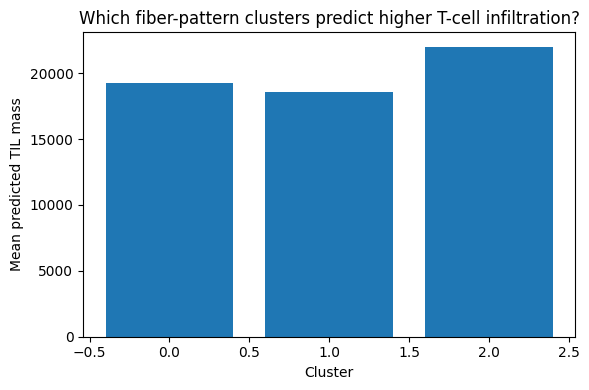

In [ ]:
plt.figure(figsize=(6,4))
plt.bar(cluster_stats.index, cluster_stats["mean"])
plt.xlabel("Cluster")
plt.ylabel("Mean predicted TIL mass")
plt.title("Which fiber-pattern clusters predict higher T-cell infiltration?")
plt.tight_layout()
plt.show()


=== Global coherence vs predicted TIL mass ===
slope (a):      -1.379e+04
intercept (b):  2.955e+04
R^2:            0.0719
p-value (lin):  1.023e-08
Spearman rho:   -0.2605
Spearman p:     2.725e-08


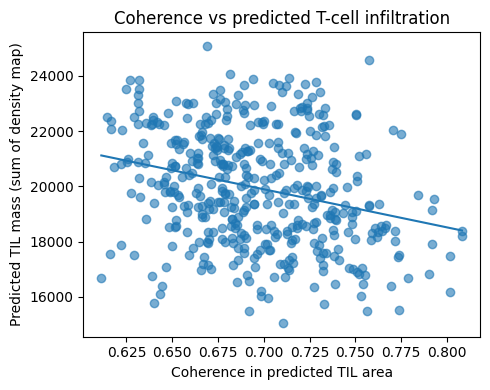

In [ ]:
import numpy as np
from scipy.stats import linregress, spearmanr
import matplotlib.pyplot as plt

# drop NaNs just in case
df_reg = df_feat.dropna(subset=["coh_pred", "pred_TIL_mass"]).copy()

x = df_reg["coh_pred"].values          # coherence in predicted TIL area
y = df_reg["pred_TIL_mass"].values     # integrated predicted TIL density

# linear regression
lin = linregress(x, y)
r2 = lin.rvalue ** 2

# Spearman correlation
rho, p_spear = spearmanr(x, y)

print("=== Global coherence vs predicted TIL mass ===")
print(f"slope (a):      {lin.slope:.4g}")
print(f"intercept (b):  {lin.intercept:.4g}")
print(f"R^2:            {r2:.4f}")
print(f"p-value (lin):  {lin.pvalue:.3e}")
print(f"Spearman rho:   {rho:.4f}")
print(f"Spearman p:     {p_spear:.3e}")

# scatter + regression line
plt.figure(figsize=(5,4))
plt.scatter(x, y, alpha=0.6)
x_line = np.linspace(x.min(), x.max(), 200)
y_line = lin.slope * x_line + lin.intercept
plt.plot(x_line, y_line)
plt.xlabel("Coherence in predicted TIL area")
plt.ylabel("Predicted TIL mass (sum of density map)")
plt.title("Coherence vs predicted T-cell infiltration")
plt.tight_layout()
plt.show()



=== Cluster 0: coherence vs predicted TIL mass ===
n patches:      189
slope (a):      -606.5
intercept (b):  1.965e+04
R^2:            0.0002
p-value (lin):  8.512e-01
Spearman rho:   -0.0292
Spearman p:     6.901e-01


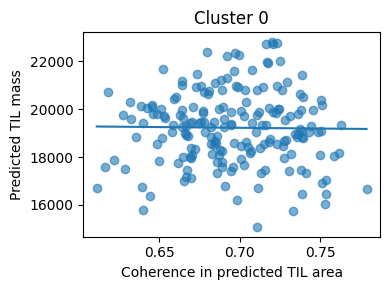


=== Cluster 1: coherence vs predicted TIL mass ===
n patches:      112
slope (a):      -1100
intercept (b):  1.939e+04
R^2:            0.0007
p-value (lin):  7.853e-01
Spearman rho:   -0.0653
Spearman p:     4.943e-01


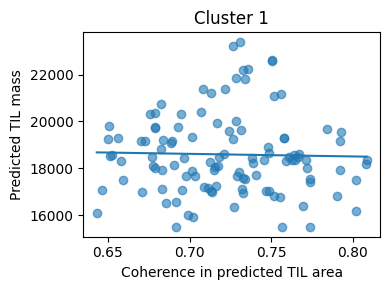


=== Cluster 2: coherence vs predicted TIL mass ===
n patches:      141
slope (a):      1873
intercept (b):  2.074e+04
R^2:            0.0029
p-value (lin):  5.242e-01
Spearman rho:   0.0787
Spearman p:     3.533e-01


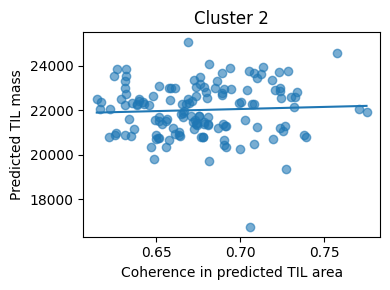

In [ ]:
import numpy as np
from scipy.stats import linregress, spearmanr
import matplotlib.pyplot as plt

clusters = sorted(df_cluster["cluster"].unique())

for k in clusters:
    sub = df_cluster[df_cluster["cluster"] == k].dropna(
        subset=["coh_pred", "pred_TIL_mass"]
    )
    if len(sub) < 3:
        print(f"\nCluster {k}: too few points ({len(sub)}) for regression.")
        continue

    x = sub["coh_pred"].values
    y = sub["pred_TIL_mass"].values

    lin = linregress(x, y)
    r2 = lin.rvalue ** 2
    rho, p_spear = spearmanr(x, y)

    print(f"\n=== Cluster {k}: coherence vs predicted TIL mass ===")
    print(f"n patches:      {len(sub)}")
    print(f"slope (a):      {lin.slope:.4g}")
    print(f"intercept (b):  {lin.intercept:.4g}")
    print(f"R^2:            {r2:.4f}")
    print(f"p-value (lin):  {lin.pvalue:.3e}")
    print(f"Spearman rho:   {rho:.4f}")
    print(f"Spearman p:     {p_spear:.3e}")

    # optional: small scatter plot per cluster
    plt.figure(figsize=(4,3))
    plt.scatter(x, y, alpha=0.6)
    x_line = np.linspace(x.min(), x.max(), 200)
    y_line = lin.slope * x_line + lin.intercept
    plt.plot(x_line, y_line)
    plt.xlabel("Coherence in predicted TIL area")
    plt.ylabel("Predicted TIL mass")
    plt.title(f"Cluster {k}")
    plt.tight_layout()
    plt.show()


In [ ]:
import torch
import numpy as np
import pandas as pd
from torch.utils.data import DataLoader
from skimage.feature import structure_tensor
from scipy.stats import linregress, spearmanr
import matplotlib.pyplot as plt

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = model.to(DEVICE).eval()

test_loader = DataLoader(test_ds, batch_size=1, shuffle=False, num_workers=0)

# ---- eigenvalues helper (since structure_tensor_eigvals is missing) ----
def structure_tensor_eigvals(Axx, Axy, Ayy):
    tmp  = 0.5 * (Axx + Ayy)
    diff = 0.5 * (Axx - Ayy)
    rad  = np.sqrt(diff**2 + Axy**2)
    l1 = tmp + rad
    l2 = tmp - rad
    return l1, l2

def coherence_mean(shg_img, sigma=2.0):
    """Mean coherence over the whole patch."""
    img = shg_img.astype(np.float32)
    Axx, Axy, Ayy = structure_tensor(img, sigma=sigma)
    l1, l2 = structure_tensor_eigvals(Axx, Axy, Ayy)
    coh = (l1 - l2) / (l1 + l2 + 1e-8)        # 0 = isotropic, 1 = highly aligned
    return float(np.nanmean(coh))

records = []

with torch.no_grad():
    for x, y, meta in test_loader:
        # x: (1,C,H,W), y: (1,1,H,W)
        x_dev = x.to(DEVICE)
        pred  = torch.sigmoid(model(x_dev))         # (1,1,H,W)

        pred_np = pred.cpu().numpy()[0, 0]          # (H,W)
        gt_np   = y.numpy()[0, 0]                   # (H,W)
        x_np    = x.squeeze(0).numpy()              # (C,H,W)

        # ---- get SHG channel, normalize to [0,1] ----
        if x_np.shape[0] == 4:          # HE+SHG
            shg = x_np[3]
        elif x_np.shape[0] == 1:        # SHG only
            shg = x_np[0]
        else:
            # if no SHG, skip this patch
            continue

        # already roughly 0–1, but re-normalize for safety
        shg = shg.astype(np.float32)
        mn, mx = shg.min(), shg.max()
        if mx > mn:
            shg = (shg - mn) / (mx - mn)
        else:
            shg = np.zeros_like(shg, dtype=np.float32)

        # ---- patch-level fiber metrics ----
        fiber_mean = float(shg.mean())
        fiber_std  = float(shg.std())
        coh_full   = coherence_mean(shg, sigma=2.0)

        # ---- patch-level TIL masses ----
        pred_mass = float(pred_np.sum())
        gt_mass   = float(gt_np.sum())

        records.append({
            "patient":        meta["patient"][0],
            "patch":          meta["name"][0],
            "fiber_mean":     fiber_mean,
            "fiber_std":      fiber_std,
            "coherence":      coh_full,
            "pred_TIL_mass":  pred_mass,
            "gt_TIL_mass":    gt_mass,
        })

df_patch = pd.DataFrame(records)
print("Number of test patches:", len(df_patch))
display(df_patch.head())


Number of test patches: 512


,patient,patch,fiber_mean,fiber_std,coherence,pred_TIL_mass,gt_TIL_mass
0,BCRAA5DD_band_overlap,BCRAA5DD_band_overlap_patch_0008_y0_x0.png,0.325626,0.231070,0.625953,20157.683594,6138.850098
1,BCRAA5DD_band_overlap,BCRAA5DD_band_overlap_patch_0008_y0_x1024.png,0.319150,0.241213,0.634664,18001.396484,1056.000000
2,BCRAA5DD_band_overlap,BCRAA5DD_band_overlap_patch_0008_y0_x1536.png,0.252282,0.217614,0.625083,19410.683594,25658.244141
3,BCRAA5DD_band_overlap,BCRAA5DD_band_overlap_patch_0008_y0_x512.png,0.316922,0.230247,0.624853,18044.273438,0.000000
4,BCRAA5DD_band_overlap,BCRAA5DD_band_overlap_patch_0008_y1024_x0.png,0.183552,0.156047,0.585611,18300.234375,15776.546875


=== Global coherence vs predicted TIL mass ===
slope (a):      6.302e+03
intercept (b):  1.526e+04
R^2:            0.0088
p-value (lin):  3.335e-02
Spearman rho:   0.0837
Spearman p:     5.846e-02


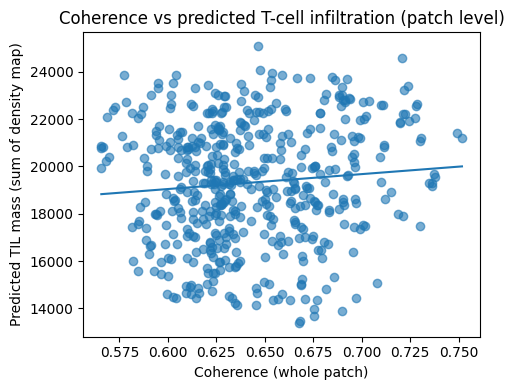

In [ ]:
# ---- coherence vs predicted TIL mass ----
x = df_patch["coherence"].values
y = df_patch["pred_TIL_mass"].values

lin = linregress(x, y)
rho, p_s = spearmanr(x, y)

print("=== Global coherence vs predicted TIL mass ===")
print(f"slope (a):      {lin.slope:.3e}")
print(f"intercept (b):  {lin.intercept:.3e}")
print(f"R^2:            {lin.rvalue**2:.4f}")
print(f"p-value (lin):  {lin.pvalue:.3e}")
print(f"Spearman rho:   {rho:.4f}")
print(f"Spearman p:     {p_s:.3e}")

plt.figure(figsize=(5,4))
plt.scatter(x, y, alpha=0.6)
x_line = np.linspace(x.min(), x.max(), 200)
y_line = lin.slope * x_line + lin.intercept
plt.plot(x_line, y_line)
plt.xlabel("Coherence (whole patch)")
plt.ylabel("Predicted TIL mass (sum of density map)")
plt.title("Coherence vs predicted T-cell infiltration (patch level)")
plt.tight_layout()
plt.show()


=== Fiber density vs predicted TIL mass ===
slope (a):      -1.294e+04
intercept (b):  2.262e+04
R^2:            0.1416
p-value (lin):  1.156e-18
Spearman rho:   -0.3736
Spearman p:     2.079e-18


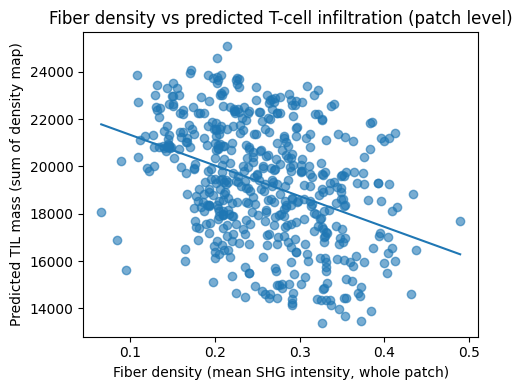

In [ ]:
x_d = df_patch["fiber_mean"].values
y_d = df_patch["pred_TIL_mass"].values

lin_d = linregress(x_d, y_d)
rho_d, p_s_d = spearmanr(x_d, y_d)

print("=== Fiber density vs predicted TIL mass ===")
print(f"slope (a):      {lin_d.slope:.3e}")
print(f"intercept (b):  {lin_d.intercept:.3e}")
print(f"R^2:            {lin_d.rvalue**2:.4f}")
print(f"p-value (lin):  {lin_d.pvalue:.3e}")
print(f"Spearman rho:   {rho_d:.4f}")
print(f"Spearman p:     {p_s_d:.3e}")

plt.figure(figsize=(5,4))
plt.scatter(x_d, y_d, alpha=0.6)
x_line = np.linspace(x_d.min(), x_d.max(), 200)
y_line = lin_d.slope * x_line + lin_d.intercept
plt.plot(x_line, y_line)
plt.xlabel("Fiber density (mean SHG intensity, whole patch)")
plt.ylabel("Predicted TIL mass (sum of density map)")
plt.title("Fiber density vs predicted T-cell infiltration (patch level)")
plt.tight_layout()
plt.show()


Patches used for clustering: 331

Cluster counts:
cluster
0    133
1    122
2     76
Name: count, dtype: int64

Cluster-wise fiber stats:


,fiber_mean_full,coh_full
cluster,,
0,0.175993,0.614773
1,0.271399,0.642339
2,0.305469,0.702610



Cluster-wise predicted TIL mass:


,count,mean,std,min,25%,50%,75%,max
cluster,,,,,,,,
0,133.0,21108.406970,1439.629601,18378.318359,20008.826172,21010.056641,22262.667969,24082.107422
1,122.0,20255.864530,1470.325737,18377.583984,19177.869629,19811.174805,21266.648926,25076.207031
2,76.0,21243.445621,1586.912235,18379.316406,19863.815918,21330.943359,22612.284180,24576.214844


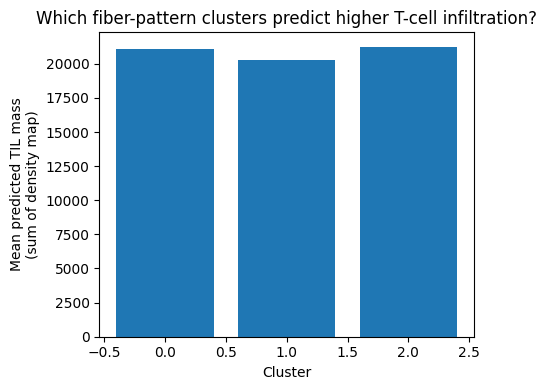

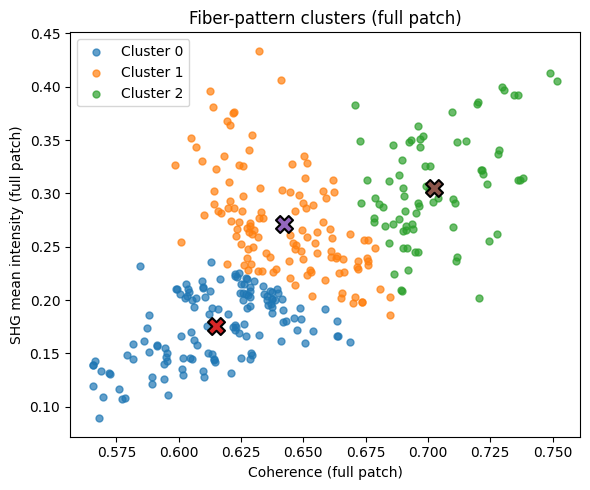

In [ ]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

# df_feat columns we need:
# ["patient", "patch", "fiber_mean_full", "coh_full", "pred_TIL_mass", "gt_TIL_mass", ...]


# -------------------------------------------------
# 1. Prepare data for clustering
# -------------------------------------------------
feature_cols = ["fiber_mean_full", "coh_full"]

df_clust = df_feat.dropna(subset=feature_cols).copy()

# Optional: keep only patches with at least some predicted T cells
til_q = np.percentile(df_clust["pred_TIL_mass"], 25)  # 25th percentile
df_clust = df_clust[df_clust["pred_TIL_mass"] >= til_q].reset_index(drop=True)
print("Patches used for clustering:", len(df_clust))

X = df_clust[feature_cols].values

# -------------------------------------------------
# 2. Standardize + K-means in (fiber_mean_full, coh_full) space
# -------------------------------------------------
# Using a new variable name for StandardScaler to avoid any potential state persistence issues
current_scaler = StandardScaler()
X_scaled = current_scaler.fit_transform(X)

K = 3  # three fiber-pattern clusters (loosish, intermediate, TACS2-like)
kmeans = KMeans(n_clusters=K, random_state=0, n_init=20)
labels = kmeans.fit_predict(X_scaled)
df_clust["cluster"] = labels

print("\nCluster counts:")
print(df_clust["cluster"].value_counts())

print("\nCluster-wise fiber stats:")
display(df_clust.groupby("cluster")[feature_cols].mean())

# -------------------------------------------------
# 3. Which clusters predict higher T-cell infiltration?
# -------------------------------------------------
cluster_stats = df_clust.groupby("cluster")["pred_TIL_mass"].describe()
print("\nCluster-wise predicted TIL mass:")
display(cluster_stats)

# Bar plot of mean predicted TIL per cluster
plt.figure(figsize=(5,4))
plt.bar(cluster_stats.index, cluster_stats["mean"])
plt.xlabel("Cluster")
plt.ylabel("Mean predicted TIL mass\n(sum of density map)")
plt.title("Which fiber-pattern clusters predict higher T-cell infiltration?")
plt.tight_layout()
plt.show()

# -------------------------------------------------
# 4. Scatter plot of clusters in fiber space
# -------------------------------------------------
plt.figure(figsize=(6,5))
colors = ["tab:blue", "tab:orange", "tab:green"]

for k in range(K):
    sel = df_clust["cluster"] == k
    plt.scatter(df_clust.loc[sel, "coh_full"],
                df_clust.loc[sel, "fiber_mean_full"],
                alpha=0.7, label=f"Cluster {k}", s=25)

# Show cluster centers (inverse-transform from standardized space)
centers = current_scaler.inverse_transform(kmeans.cluster_centers_)
for k in range(K):
    plt.scatter(centers[k, 1],  # coh_full
                centers[k, 0],  # fiber_mean_full
                marker="X", s=150, edgecolor="k", linewidth=1.5)

plt.xlabel("Coherence (full patch)")
plt.ylabel("SHG mean intensity (full patch)")
plt.title("Fiber-pattern clusters (full patch)")
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
def channel_occlusion(model, x):
    model.eval()
    base_pred = model(x).detach()

    results = {}
    for ch in range(x.shape[1]):
        x_occ = x.clone()
        x_occ[:, ch] = 0.0   # remove channel
        pred_occ = model(x_occ).detach()
        diff = (base_pred - pred_occ).abs().mean().item()
        results[f"channel_{ch}"] = diff
    return results


In [ ]:
import torch

# Assuming 'x' is available from a previous cell and is a numpy array
# Convert x to a PyTorch tensor and move it to CUDA
x_tensor_cuda = torch.from_numpy(x).float().unsqueeze(0).to("cuda")

imp = channel_occlusion(model, x_tensor_cuda)
print(imp)

AttributeError: 'numpy.ndarray' object has no attribute 'cuda'

=== Global coherence vs predicted TIL mass ===
slope (a):       -1.118e+05
intercept (b):   1.063e+05
R^2:             0.1754
p-value (lin):   3.393e-03
Spearman rho:    -0.2170
Spearman p-val:  1.428e-01


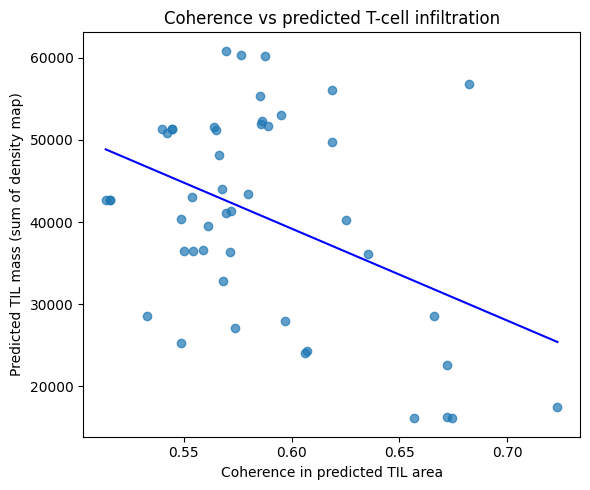

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import linregress, spearmanr

# Clean data
df_reg = df_feat.dropna(subset=["coh_pred", "pred_TIL_mass"]).copy()

x = df_reg["coh_pred"].values
y = df_reg["pred_TIL_mass"].values

# Linear regression
lin = linregress(x, y)

# Spearman correlation
rho, p_spear = spearmanr(x, y)

print("=== Global coherence vs predicted TIL mass ===")
print(f"slope (a):       {lin.slope:.3e}")
print(f"intercept (b):   {lin.intercept:.3e}")
print(f"R^2:             {lin.rvalue**2:.4f}")
print(f"p-value (lin):   {lin.pvalue:.3e}")
print(f"Spearman rho:    {rho:.4f}")
print(f"Spearman p-val:  {p_spear:.3e}")

# Plot
plt.figure(figsize=(6,5))
plt.scatter(x, y, alpha=0.7)
x_line = np.linspace(x.min(), x.max(), 200)
y_line = lin.slope * x_line + lin.intercept
plt.plot(x_line, y_line, color='blue')
plt.xlabel("Coherence in predicted TIL area")
plt.ylabel("Predicted TIL mass (sum of density map)")
plt.title("Coherence vs predicted T-cell infiltration")
plt.tight_layout()
plt.show()


In [ ]:
from skimage.feature import structure_tensor

coh_map = coherence_map(shg)        # shape ~512×512
coh_small = cv2.resize(coh_map, (32, 32))   # flatten to 1024 dims

# Recompute Axx, Axy, Ayy for direct use
Axx, Axy, Ayy = structure_tensor(shg, sigma=2.0) # Using the same sigma as coherence_map
angles = np.arctan2(Axy, Axx - Ayy)
angles_small = cv2.resize(angles, (32, 32))

In [ ]:
from sklearn.decomposition import PCA

# Define X_fiber using relevant columns from df_patch
# Ensure there are no NaNs in the selected columns for PCA
# The columns fiber_mean, fiber_std, and coherence were calculated in df_patch

X_fiber = df_patch[['fiber_mean', 'fiber_std', 'coherence']].dropna().values

# Correct n_components to be at most the number of features (3 in this case)
pca = PCA(n_components=3)
X_pca = pca.fit_transform(X_fiber)


In [ ]:
from sklearn.cluster import KMeans

kmeans = KMeans(n_clusters=3, random_state=0)
labels = kmeans.fit_predict(X_pca)


In [ ]:
import matplotlib.pyplot as plt
import cv2
import numpy as np

# --- Start of definitions copied from cell T3mn6RNOigW_ to resolve NameError ---
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

# Assuming df_feat is already defined from cell 1myQZkAybqzo.

feature_cols = ["fiber_mean_full", "coh_full"]

df_clust = df_feat.dropna(subset=feature_cols).copy()

# Optional: keep only patches with at least some predicted T cells
til_q = np.percentile(df_clust["pred_TIL_mass"], 25)  # 25th percentile
df_clust = df_clust[df_clust["pred_TIL_mass"] >= til_q].reset_index(drop=True)

X = df_clust[feature_cols].values

# Standardize
current_scaler = StandardScaler()
X_scaled = current_scaler.fit_transform(X)

# K-means (K from T3mn6RNOigW_)
K = 3
kmeans = KMeans(n_clusters=K, random_state=0, n_init=20)
labels = kmeans.fit_predict(X_scaled)
df_clust["cluster"] = labels
# --- End of copied definitions ---

def show_cluster_examples(df_cluster, kmeans, scaler, feature_cols, DATA_ROOT, model=None):
    """
    Show one representative HE + SHG + Pred TIL (if model provided)
    for each cluster.
    """

    unique_clusters = sorted(df_cluster["cluster"].unique())
    rep_rows = []

    X_func = df_cluster[feature_cols].values
    X_scaled_func = scaler.transform(X_func)
    labels_func = df_cluster["cluster"].values

    for k in unique_clusters:
        idx_k = np.where(labels_func == k)[0]
        if len(idx_k) == 0:
            continue

        # cluster center
        center = kmeans.cluster_centers_[k]

        # find the closest patch to the center
        # Use X_scaled_func for distance calculation, as centers are in scaled space
        cluster_pts = X_scaled_func[idx_k]
        dist = np.linalg.norm(cluster_pts - center, axis=1)
        nearest_local = idx_k[np.argmin(dist)]

        # original dataframe index
        rep_rows.append(df_cluster.index[nearest_local])

    # Plot each representative
    n = len(rep_rows)
    fig, axes = plt.subplots(n, 3, figsize=(10, 4*n))

    if n == 1:
        axes = np.expand_dims(axes, 0)

    for row_ax, idx in zip(axes, rep_rows):
        row = df_cluster.loc[idx]
        cluster_id = int(row["cluster"])
        patient = row["patient"]
        patch   = row["patch"]

        # --- Load images ---
        he_path  = DATA_ROOT / patient / "HE"  / patch
        shg_path = DATA_ROOT / patient / "SHG" / patch
        til_path = DATA_ROOT / patient / "TIL_DEN" / patch # GT TIL for completeness

        he = cv2.cvtColor(cv2.imread(str(he_path)), cv2.COLOR_BGR2RGB)
        shg = cv2.imread(str(shg_path), cv2.IMREAD_GRAYSCALE).astype(np.float32)
        til = cv2.imread(str(til_path), cv2.IMREAD_GRAYSCALE).astype(np.float32)

        # normalize SHG + TIL for display
        shg_disp = (shg - shg.min()) / (shg.max() - shg.min() + 1e-8)
        til_disp = (til - til.min()) / (til.max() - til.min() + 1e-8)

        # --- Optional: predicted TIL map ---
        if model is not None:
            # Assuming model expects single-channel SHG input as float tensor
            shg_input = shg_disp # Already 0-1 normalized
            x = torch.from_numpy(shg_input[None, None, :, :]).float().to(model.device)

            with torch.no_grad():
                pred = torch.sigmoid(model(x)).cpu().numpy()[0,0]
            pred_disp = (pred - pred.min())/(pred.max()-pred.min()+1e-8)
        else:
            pred_disp = None

        # --- Plot ---
        row_ax[0].imshow(he)
        row_ax[0].set_title(f"Cluster {cluster_id} – HE")
        row_ax[0].axis("off")

        row_ax[1].imshow(shg_disp, cmap="gray")
        row_ax[1].set_title("SHG (fiber structure)")
        row_ax[1].axis("off")

        if pred_disp is not None:
            row_ax[2].imshow(pred_disp, cmap="magma")
            row_ax[2].set_title("Predicted TIL")
            row_ax[2].axis("off")
        else:
            row_ax[2].imshow(til_disp, cmap="magma")
            row_ax[2].set_title("GT TIL density")
            row_ax[2].axis("off")

    plt.tight_layout()
    plt.show()


# ---- RUN IT ----
# Assuming DATA_ROOT and model are defined in previous cells
show_cluster_examples(
    df_cluster=df_clust,
    kmeans=kmeans,
    scaler=current_scaler,
    feature_cols=feature_cols,
    DATA_ROOT=DATA_ROOT,
    model=model  # or None if you want GT TIL only
)

NameError: name 'df_clust' is not defined

In [ ]:
######################################Below is SHG only training####################################################################3

Detected patients: ['BCRAA04Y_band_overlap', 'BCRAA0AY_band_overlap', 'BCRAA0BG_band_overlap', 'BCRAA0C1_band_overlap', 'BCRAA0CK_band_overlap', 'BCRAA0IP_band_overlap', 'BCRAA0JI_band_overlap', 'BCRAA0SD_band_overlap', 'BCRAA0SF_band_overlap', 'BCRAA0SH_band_overlap', 'BCRAA0SI_band_overlap', 'BCRAA0SM_band_overlap', 'BCRAA0SP_band_overlap', 'BCRAA0SQ_band_overlap', 'BCRAA0YC_band_overlap', 'BCRAA1FC_band_overlap', 'BCRAA1LI_band_overlap', 'BCRAA22D_band_overlap', 'BCRAA278_band_overlap', 'BCRAA2DA_band_overlap', 'BCRAA2LE_band_overlap', 'BCRAA3OD_band_overlap', 'BCRAA3Y0_band_overlap', 'BCRAA3YJ_band_overlap', 'BCRAA4S2_band_overlap', 'BCRAA4SF_band_overlap', 'BCRAA5DD_band_overlap', 'BCRAA74U_band_overlap', 'BCRAAB41_band_overlap']
All patients: ['BCRAA04Y_band_overlap', 'BCRAA0AY_band_overlap', 'BCRAA0BG_band_overlap', 'BCRAA0C1_band_overlap', 'BCRAA0CK_band_overlap', 'BCRAA0IP_band_overlap', 'BCRAA0JI_band_overlap', 'BCRAA0SD_band_overlap', 'BCRAA0SF_band_overlap', 'BCRAA0SH_band_

/usr/local/lib/python3.12/dist-packages/albumentations/core/validation.py:114: UserWarning: ShiftScaleRotate is a special case of Affine transform. Please use Affine transform instead.
  original_init(self, **validated_kwargs)
/tmp/ipython-input-1115154644.py:205: UserWarning: Argument(s) 'var_limit' are not valid for transform GaussNoise
  A.GaussNoise(


Global TIL scale (p99.5) = 0.9961
[BCRAA0CK_band_overlap,BCRAA3YJ_band_overlap,BCRAA0SI_band_overlap,BCRAA0JI_band_overlap,BCRAA4S2_band_overlap,BCRAA0AY_band_overlap,BCRAA1FC_band_overlap,BCRAA04Y_band_overlap,BCRAA0SF_band_overlap,BCRAA3OD_band_overlap,BCRAA74U_band_overlap,BCRAA2LE_band_overlap,BCRAA1LI_band_overlap,BCRAA2DA_band_overlap,BCRAA0SH_band_overlap,BCRAA0SP_band_overlap,BCRAA22D_band_overlap,BCRAA0IP_band_overlap,BCRAA0YC_band_overlap,BCRAA3Y0_band_overlap,BCRAA0C1_band_overlap,BCRAA4SF_band_overlap,BCRAA0SQ_band_overlap] patches: 3808, positive: 2437 (64.0%)
[BCRAA0BG_band_overlap,BCRAAB41_band_overlap,BCRAA278_band_overlap] patches: 672, positive: 421 (62.6%)
[BCRAA0SD_band_overlap,BCRAA5DD_band_overlap,BCRAA0SM_band_overlap] patches: 624, positive: 189 (30.3%)

=== Using mild reweighting of positive/negative patches ===
Current train positive rate   : 0.640
Test positive rate            : 0.303
Mild target train pos. rate   : 0.471
Positive weight scale s_pos   : 0.502

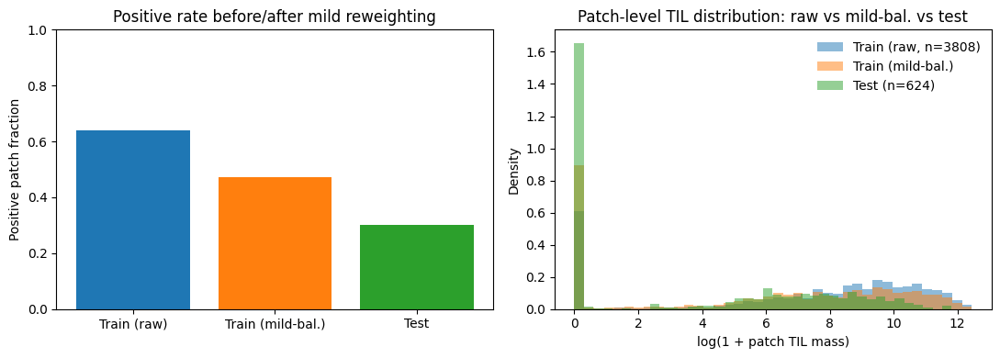

In [ ]:
import os
from pathlib import Path
import random
import numpy as np
from PIL import Image

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler

from sklearn.metrics import roc_auc_score, average_precision_score

# ================== CONFIG ==================
DATA_ROOT      = Path("/content/Outputs_512_den_new")   # <--- change if needed
OUT_DIR        = Path("/content/models_shg_attunet_cont")
OUT_DIR.mkdir(parents=True, exist_ok=True)

DEVICE         = torch.device("cuda" if torch.cuda.is_available() else "cpu")

BATCH_SIZE     = 2
NUM_WORKERS    = 4
MAX_EPOCHS     = 60
PATIENCE       = 5
BASE_LR        = 1e-4
WEIGHT_DECAY   = 1e-4

TIL_FOLDER_NAME = "TIL_DEN"
TIL_PERCENTILE  = 99.5   # for global TIL normalization
TIL_BIN_THR     = 0.1    # used only for defining “positive” pixels for sampling & metrics
MIN_POS_PIXELS  = 5    # min pixels above threshold to call a patch “positive”

# Sampling strategy
SAMPLING_MODE  = "mild_balance"  # "pos_balance" or "none"
POS_OVERSAMPLE = 3.0            # weight multiplier for positive patches


SEED = 123
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Discover patients based on presence of SHG folder
PATIENT_CODES = sorted(
    [p.name for p in DATA_ROOT.iterdir()
     if p.is_dir() and (p / "SHG").exists()]
)
print("Detected patients:", PATIENT_CODES)

# ================== DATASET ==================

class SHGOnlyTILDataset(Dataset):
    """
    SHG-only dataset:
    - SHG:    grayscale PNG, scaled to [0,1], brightness preserved.
    - TIL:    grayscale PNG in TIL_DEN, interpreted as continuous density
              and normalized by a global percentile scale.
    - Training target: continuous normalized TIL density map (no binarization).
    - Binary mask is used only for patch-level sampling & metrics.
    """
    def __init__(self,
                 data_root,
                 patient_list,
                 til_folder_name="TIL_DEN",
                 til_percentile=99.5,
                 til_bin_thr=0.1,
                 precomputed_scale=None,
                 transform=None):
        super().__init__()
        self.data_root      = Path(data_root)
        self.patients       = patient_list
        self.til_folder     = til_folder_name
        self.til_percentile = til_percentile
        self.til_bin_thr    = til_bin_thr
        self.transform      = transform

        self.samples = []   # list of (shg_path, til_path)

        for pid in self.patients:
            pdir    = self.data_root / pid
            shg_dir = pdir / "SHG"
            til_dir = pdir / self.til_folder

            if not shg_dir.exists():
                print(f"[WARN] No SHG dir for {pid}")
                continue
            if not til_dir.exists():
                print(f"[WARN] No TIL dir '{self.til_folder}' for {pid}")
                continue

            for shg_file in sorted(shg_dir.glob("*.png")):
                stem = shg_file.stem
                til_path = til_dir / f"{stem}.png"
                if til_path.exists():
                    self.samples.append((shg_file, til_path))
                else:
                    print(f"[WARN] Missing TIL for {shg_file.name} (expected {til_path.name})")

        if len(self.samples) == 0:
            raise RuntimeError(
                f"No SHG–TIL pairs found for patients {self.patients}. "
                f"Check folder names and file patterns."
            )

        # ----- global percentile scale for TIL density -----
        if precomputed_scale is None:
            print("Computing global TIL density percentile scale from PNGs...")
            all_vals = []
            for _, til_path in self.samples:
                til_img = Image.open(til_path).convert("F")
                den = np.array(til_img, dtype=np.float32) / 255.0  # [0,1]
                nz = den[den > 0]
                if nz.size > 0:
                    all_vals.append(nz)
            if len(all_vals) == 0:
                self.til_scale = 1.0
            else:
                all_vals = np.concatenate(all_vals)
                self.til_scale = np.percentile(all_vals, self.til_percentile) + 1e-6
            print(f"Global TIL scale (p{self.til_percentile}) = {self.til_scale:.4f}")
        else:
            self.til_scale = precomputed_scale

        # ----- patch-level stats for sampling -----
        self.patch_mass   = []
        self.is_pos_patch = []
        for _, til_path in self.samples:
            til_img = Image.open(til_path).convert("F")
            den = np.array(til_img, dtype=np.float32) / 255.0
            den_norm = np.clip(den / self.til_scale, 0.0, 1.0)
            self.patch_mass.append(float(den_norm.sum()))
            pos_pixels = (den_norm >= self.til_bin_thr).sum()
            self.is_pos_patch.append(pos_pixels >= MIN_POS_PIXELS)

        self.patch_mass   = np.array(self.patch_mass, dtype=np.float32)
        self.is_pos_patch = np.array(self.is_pos_patch, dtype=bool)

        # Print quick stats
        num_pos = int(self.is_pos_patch.sum())
        total   = len(self.is_pos_patch)
        print(f"[{','.join(self.patients)}] patches: {total}, "
              f"positive: {num_pos} ({100.0 * num_pos / total:.1f}%)")

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        shg_path, til_path = self.samples[idx]

        # --- SHG image (input) ---
        shg_img = Image.open(shg_path).convert("L")
        img = np.array(shg_img, dtype=np.float32) / 255.0  # [0,1]

        # --- TIL density (continuous target) ---
        til_img = Image.open(til_path).convert("F")
        den = np.array(til_img, dtype=np.float32) / 255.0  # [0,1]

        den_norm = np.clip(den / self.til_scale, 0.0, 1.0)  # continuous target [0,1]

        img_hwc      = img[..., None]      # (H,W,1)
        den_cont_hwc = den_norm[..., None] # (H,W,1)

        if self.transform is not None:
            import albumentations as A
            from albumentations.pytorch import ToTensorV2

            # Use den_cont as mask so augmentations (flips/rotations) are aligned
            augmented = self.transform(image=img_hwc, mask=den_cont_hwc)
            img_t     = augmented["image"]     # (1,H,W)
            den_cont_t = augmented["mask"]     # (1,H,W), still continuous
        else:
            img_t      = torch.from_numpy(img_hwc.transpose(2,0,1)).float()
            den_cont_t = torch.from_numpy(den_cont_hwc.transpose(2,0,1)).float()

        return img_t, den_cont_t, idx


# ================== TRANSFORMS ==================

def get_train_transform():
    import albumentations as A
    from albumentations.pytorch import ToTensorV2
    return A.Compose([
        A.HorizontalFlip(p=0.5),
        A.VerticalFlip(p=0.5),
        A.RandomRotate90(p=0.5),
        A.ShiftScaleRotate(
            shift_limit=0.05,
            scale_limit=0.1,
            rotate_limit=15,
            border_mode=0,
            p=0.5
        ),
        A.RandomBrightnessContrast(
            brightness_limit=0.15,
            contrast_limit=0.15,
            p=0.5
        ),
        A.RandomGamma(
            gamma_limit=(80, 120),
            p=0.3
        ),
        A.GaussNoise(
            var_limit=(5.0, 20.0),
            p=0.3
        ),
        ToTensorV2()
    ])

def get_val_transform():
    import albumentations as A
    from albumentations.pytorch import ToTensorV2
    return A.Compose([
        ToTensorV2()
    ])

#=========================PSM=============================

import numpy as np
import matplotlib.pyplot as plt

def compute_mild_balance_weights(train_ds, test_ds=None, target_pos_rate=None, save_fig=True):
    """
    Mild, stable patch-level reweighting:
      - we ONLY use the binary label is_pos_patch
      - we compute a global positive scaling factor s_pos that
        moves the effective positive rate from r -> target t
      - weights are soft (no hard dropping), used in WeightedRandomSampler
    """

    y = train_ds.is_pos_patch.astype(int)
    cur_pos_rate = float(y.mean())

    if test_ds is not None:
        test_pos_rate = float(test_ds.is_pos_patch.mean())
    else:
        test_pos_rate = None

    # ---- choose a mild target ----
    if target_pos_rate is None:
        if test_pos_rate is not None:
            # mild: halfway between train and test
            target_pos_rate = 0.5 * cur_pos_rate + 0.5 * test_pos_rate
        else:
            # fallback: move 25% of the way toward 0.5
            target_pos_rate = 0.75 * cur_pos_rate + 0.25 * 0.5

    t = float(target_pos_rate)
    r = cur_pos_rate

    # clamp so we don't try anything crazy
    t = max(0.05, min(0.95, t))

    print(f"Current train positive rate   : {r:.3f}")
    if test_pos_rate is not None:
        print(f"Test positive rate            : {test_pos_rate:.3f}")
    print(f"Mild target train pos. rate   : {t:.3f}")

    # ---- solve for positive scaling factor s_pos ----
    # If we set w_pos = s_pos, w_neg = 1,
    # weighted positive fraction is:
    #   f = s_pos * r / (s_pos * r + (1 - r))
    # Solve for s_pos such that f = t:
    #   s_pos * r / (s_pos * r + 1 - r) = t
    #   => s_pos = t(1 - r) / [ r (1 - t) ]
    eps = 1e-6
    s_pos = t * (1.0 - r) / (r * (1.0 - t) + eps)

    print(f"Positive weight scale s_pos   : {s_pos:.3f}")

    # ---- build weights ----
    w = np.where(y == 1, s_pos, 1.0).astype(np.float32)

    # normalize so mean weight ~1 (helps sampler)
    w = w / w.mean()

    # compute achieved weighted rate
    weighted_pos_rate = float(np.average(y, weights=w))
    print(f"Weighted train positive rate  : {weighted_pos_rate:.3f}")

    # ---- paper-ready visualization ----
    if save_fig:
        fig, axes = plt.subplots(1, 2, figsize=(11, 4))

        # panel 1: positive fraction bar plot
        names = ["Train (raw)", "Train (mild-bal.)", "Test"]
        vals  = [r, weighted_pos_rate,
                 test_pos_rate if test_pos_rate is not None else np.nan]
        colors = ["tab:blue", "tab:orange", "tab:green"]

        axes[0].bar(names, vals, color=colors)
        axes[0].set_ylim(0, 1)
        axes[0].set_ylabel("Positive patch fraction")
        axes[0].set_title("Positive rate before/after mild reweighting")

        # panel 2: TIL mass histograms (for context, same as before)
        til_train = np.asarray(train_ds.patch_mass, dtype=np.float32)
        if test_ds is not None:
            til_test = np.asarray(test_ds.patch_mass, dtype=np.float32)
        else:
            til_test = None

        til_train_log = np.log1p(til_train)
        if test_ds is not None:
            til_test_log = np.log1p(til_test)

        bins = 40
        axes[1].hist(
            til_train_log,
            bins=bins,
            alpha=0.5,
            label=f"Train (raw, n={len(til_train)})",
            density=True,
        )
        axes[1].hist(
            til_train_log,
            bins=bins,
            weights=w / w.mean(),
            alpha=0.5,
            label="Train (mild-bal.)",
            density=True,
        )
        if test_ds is not None:
            axes[1].hist(
                til_test_log,
                bins=bins,
                alpha=0.5,
                label=f"Test (n={len(til_test)})",
                density=True,
            )

        axes[1].set_xlabel("log(1 + patch TIL mass)")
        axes[1].set_ylabel("Density")
        axes[1].set_title("Patch-level TIL distribution: raw vs mild-bal. vs test")
        axes[1].legend(frameon=False)

        plt.tight_layout()
        fig_path = OUT_DIR / "mild_balance.png"
        plt.savefig(fig_path, dpi=300, bbox_inches="tight")
        print(f"Mild balance figure saved to: {fig_path}")

    return w




# ================== MODEL: ATTENTION U-NET (dropout=0.2) ==================

class ConvBlock(nn.Module):
    def __init__(self, in_ch, out_ch, p_drop=0):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, 3, padding=1),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, 3, padding=1),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
        )
        self.drop = nn.Dropout2d(p_drop)

    def forward(self, x):
        return self.drop(self.block(x))


class UpConv(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.up   = nn.Upsample(scale_factor=2, mode='bilinear', align_corners=True)
        self.conv = nn.Conv2d(in_ch, out_ch, 3, padding=1)
        self.bn   = nn.BatchNorm2d(out_ch)
        self.relu = nn.ReLU(inplace=True)

    def forward(self, x):
        x = self.up(x)
        x = self.relu(self.bn(self.conv(x)))
        return x


class AttentionGate(nn.Module):
    def __init__(self, F_g, F_l, F_int):
        super().__init__()
        self.W_g = nn.Sequential(
            nn.Conv2d(F_g, F_int, kernel_size=1),
            nn.BatchNorm2d(F_int)
        )
        self.W_x = nn.Sequential(
            nn.Conv2d(F_l, F_int, kernel_size=1),
            nn.BatchNorm2d(F_int)
        )
        self.psi = nn.Sequential(
            nn.Conv2d(F_int, 1, kernel_size=1),
            nn.BatchNorm2d(1),
            nn.Sigmoid()
        )
        self.relu = nn.ReLU(inplace=True)

        # <--- this is new
        self.last_psi = None

    def forward(self, g, x):
        g1  = self.W_g(g)
        x1  = self.W_x(x)
        psi = self.relu(g1 + x1)
        psi = self.psi(psi)          # [B,1,h,w] in [0,1]
        self.last_psi = psi          # <--- store attention map
        return x * psi

class AttUNet(nn.Module):
    def __init__(self, img_ch=1, output_ch=1, base_ch=32, p_drop=0.2):
        super().__init__()
        c1, c2, c3, c4, c5 = base_ch, base_ch*2, base_ch*4, base_ch*8, base_ch*16

        # encoder
        self.conv1 = ConvBlock(img_ch, c1, p_drop=p_drop); self.pool1 = nn.MaxPool2d(2)
        self.conv2 = ConvBlock(c1, c2, p_drop=p_drop);     self.pool2 = nn.MaxPool2d(2)
        self.conv3 = ConvBlock(c2, c3, p_drop=p_drop);     self.pool3 = nn.MaxPool2d(2)
        self.conv4 = ConvBlock(c3, c4, p_drop=p_drop);     self.pool4 = nn.MaxPool2d(2)
        self.conv5 = ConvBlock(c4, c5, p_drop=p_drop)

        # decoder
        self.up5      = UpConv(c5, c4)
        self.att5     = AttentionBlock(c4, c4, c4//2)
        self.up_conv5 = ConvBlock(c5, c4, p_drop=p_drop)

        self.up4      = UpConv(c4, c3)
        self.att4     = AttentionBlock(c3, c3, c3//2)
        self.up_conv4 = ConvBlock(c4, c3, p_drop=p_drop)

        self.up3      = UpConv(c3, c2)
        self.att3     = AttentionBlock(c2, c2, c2//2)
        self.up_conv3 = ConvBlock(c3, c2, p_drop=p_drop)

        self.up2      = UpConv(c2, c1)
        self.att2     = AttentionBlock(c1, c1, c1//2)
        self.up_conv2 = ConvBlock(c2, c1, p_drop=p_drop)

        self.outc     = nn.Conv2d(c1, output_ch, 1)

    def forward(self, x):
        x1 = self.conv1(x); p1 = self.pool1(x1)
        x2 = self.conv2(p1); p2 = self.pool2(x2)
        x3 = self.conv3(p2); p3 = self.pool3(x3)
        x4 = self.conv4(p3); p4 = self.pool4(x4)
        x5 = self.conv5(p4)

        d5 = self.up5(x5); x4a = self.att5(d5, x4); d5 = self.up_conv5(torch.cat([x4a, d5], dim=1))
        d4 = self.up4(d5); x3a = self.att4(d4, x3); d4 = self.up_conv4(torch.cat([x3a, d4], dim=1))
        d3 = self.up3(d4); x2a = self.att3(d3, x2); d3 = self.up_conv3(torch.cat([x2a, d3], dim=1))
        d2 = self.up2(d3); x1a = self.att2(d2, x1); d2 = self.up_conv2(torch.cat([x1a, d2], dim=1))

        return self.outc(d2)


# ================== LOSS (continuous L1) ==================

class ContinuousL1Loss(nn.Module):
    """
    L1 between sigmoid(logits) and continuous TIL density [0,1].
    """
    def __init__(self):
        super().__init__()
        self.l1 = nn.L1Loss()

    def forward(self, logits, targets):
        probs = torch.sigmoid(logits)
        return self.l1(probs, targets)


# ================== METRICS ==================

def compute_pixel_metrics(pred_logits, true_cont, thr_cont=TIL_BIN_THR):
    """
    Compute AUROC & AUPRC by binarizing the continuous TIL map with thr_cont.
    """
    with torch.no_grad():
        probs = torch.sigmoid(pred_logits).view(-1).cpu().numpy().astype(np.float32)
        gt_bin = (true_cont.view(-1).cpu().numpy().astype(np.float32) >= thr_cont).astype(np.uint8)

        if gt_bin.sum() == 0 or gt_bin.sum() == len(gt_bin):
            return np.nan, np.nan

        auroc = roc_auc_score(gt_bin, probs)
        auprc = average_precision_score(gt_bin, probs)
        return float(auroc), float(auprc)


# ================== TRAIN & EVAL LOOPS ==================

def train_one_epoch(model, loader, optimizer, scaler, criterion):
    model.train()
    running_loss = 0.0

    def _fix_target_shape(den_cont):
    # we want [B, 1, H, W]
        if den_cont.ndim == 4:
            # case like [B, H, W, 1]
            if den_cont.shape[1] != 1 and den_cont.shape[-1] == 1:
                den_cont = den_cont.permute(0, 3, 1, 2).contiguous()
        return den_cont


    for imgs, den_cont, _ in loader:
        imgs     = imgs.to(DEVICE, non_blocking=True)
        den_cont = den_cont.to(DEVICE, non_blocking=True)
        den_cont = _fix_target_shape(den_cont)      # <--- add this line

        optimizer.zero_grad()
        with torch.amp.autocast(device_type='cuda', enabled=(DEVICE.type == "cuda")):
            logits = model(imgs)                    # [B,1,512,512]
            loss   = criterion(logits, den_cont)    # shapes now match


        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        running_loss += loss.item() * imgs.size(0)

    epoch_loss = running_loss / len(loader.dataset)
    return epoch_loss


def eval_model(model, loader, criterion):
    model.eval()
    running_loss = 0.0
    aurocs, auprcs = [], []

    def _fix_target_shape(den_cont):
    # we want [B, 1, H, W]
        if den_cont.ndim == 4:
            # case like [B, H, W, 1]
            if den_cont.shape[1] != 1 and den_cont.shape[-1] == 1:
                den_cont = den_cont.permute(0, 3, 1, 2).contiguous()
        return den_cont


    with torch.no_grad():
        for imgs, den_cont, _ in loader:
            imgs     = imgs.to(DEVICE, non_blocking=True)
            den_cont = den_cont.to(DEVICE, non_blocking=True)
            den_cont = _fix_target_shape(den_cont)      # <--- same fix

            with torch.amp.autocast(device_type='cuda', enabled=(DEVICE.type == "cuda")):
                logits = model(imgs)
                loss   = criterion(logits, den_cont)


            running_loss += loss.item() * imgs.size(0)

            a, p = compute_pixel_metrics(logits, den_cont)
            if not np.isnan(a):
                aurocs.append(a)
            if not np.isnan(p):
                auprcs.append(p)

    mean_loss  = running_loss / len(loader.dataset)
    mean_auroc = float(np.mean(aurocs)) if len(aurocs) > 0 else np.nan
    mean_auprc = float(np.mean(auprcs)) if len(auprcs) > 0 else np.nan
    return mean_loss, mean_auroc, mean_auprc


# ================== BUILD LOADERS ==================

from torch.utils.data import DataLoader, WeightedRandomSampler

from torch.utils.data import DataLoader, WeightedRandomSampler

def build_loaders_for_fold(train_patients, val_patients, test_patients):

    train_ds = SHGOnlyTILDataset(
        DATA_ROOT,
        train_patients,
        til_folder_name=TIL_FOLDER_NAME,
        til_percentile=TIL_PERCENTILE,
        til_bin_thr=TIL_BIN_THR,
        precomputed_scale=None,
        transform=get_train_transform()
    )
    til_scale = train_ds.til_scale

    val_ds = SHGOnlyTILDataset(
        DATA_ROOT,
        val_patients,
        til_folder_name=TIL_FOLDER_NAME,
        til_percentile=TIL_PERCENTILE,
        til_bin_thr=TIL_BIN_THR,
        precomputed_scale=til_scale,
        transform=get_val_transform()
    )

    test_ds = SHGOnlyTILDataset(
        DATA_ROOT,
        test_patients,
        til_folder_name=TIL_FOLDER_NAME,
        til_percentile=TIL_PERCENTILE,
        til_bin_thr=TIL_BIN_THR,
        precomputed_scale=til_scale,
        transform=get_val_transform()
    )

    # ---- TRAIN LOADER ----
    if SAMPLING_MODE == "mild_balance":
        print("\n=== Using mild reweighting of positive/negative patches ===")
        weights = compute_mild_balance_weights(
            train_ds,
            test_ds=test_ds,
            target_pos_rate=None,
            save_fig=True,
        )
        sampler = WeightedRandomSampler(
            weights=weights,
            num_samples=len(weights),
            replacement=True,
        )
        train_loader = DataLoader(
            train_ds,
            batch_size=BATCH_SIZE,
            sampler=sampler,
            num_workers=NUM_WORKERS,
            pin_memory=True,
        )

    elif SAMPLING_MODE == "pos_balance":
        print("\n=== Using simple positive oversampling ===")
        weights = np.where(train_ds.is_pos_patch, POS_OVERSAMPLE, 1.0).astype(np.float32)
        sampler = WeightedRandomSampler(
            weights=weights,
            num_samples=len(weights),
            replacement=True,
        )
        train_loader = DataLoader(
            train_ds,
            batch_size=BATCH_SIZE,
            sampler=sampler,
            num_workers=NUM_WORKERS,
            pin_memory=True,
        )

    else:  # "none"
        print("\n=== Using plain shuffled train loader ===")
        train_loader = DataLoader(
            train_ds,
            batch_size=BATCH_SIZE,
            shuffle=True,
            num_workers=NUM_WORKERS,
            pin_memory=True,
        )

    # ---- VAL & TEST ----
    val_loader = DataLoader(
        val_ds,
        batch_size=1,
        shuffle=False,
        num_workers=NUM_WORKERS,
        pin_memory=True,
    )
    test_loader = DataLoader(
        test_ds,
        batch_size=1,
        shuffle=False,
        num_workers=NUM_WORKERS,
        pin_memory=True,
    )

    return train_loader, val_loader, test_loader, train_ds, val_ds, test_ds




# ================== MAIN TRAINING (2 val, 2 test) ==================

def run_training():
    print("All patients:", PATIENT_CODES)

    # 1) Single split: 3 val, 3 test, rest train
    patient_codes = np.array(PATIENT_CODES)
    rng = np.random.default_rng(SEED)
    perm = rng.permutation(len(patient_codes))
    patient_codes = patient_codes[perm]

    val_patients   = patient_codes[:3].tolist()
    test_patients  = patient_codes[3:6].tolist()
    train_patients = patient_codes[6:].tolist()

    print("\n===== Patient Split =====")
    print("Train:", train_patients)
    print("Val:  ", val_patients)
    print("Test: ", test_patients)
    print("=========================\n")

    # 2) Build loaders
    train_loader, val_loader, test_loader, train_ds, val_ds, test_ds = \
        build_loaders_for_fold(train_patients, val_patients, test_patients)

    # 3) Model, optimizer, scheduler, loss, AMP scaler
    model = AttUNet(img_ch=1, output_ch=1, base_ch=32, p_drop=0.2).to(DEVICE)

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=BASE_LR,
        weight_decay=WEIGHT_DECAY
    )

    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer,
        mode='min',
        factor=0.5,
        patience=3

    )

    criterion = ContinuousL1Loss()
    scaler = torch.amp.GradScaler(enabled=(DEVICE.type == "cuda"))

    best_val_loss = float("inf")
    best_ckpt_path = OUT_DIR / "best_shg_attunet_single_split.pt"
    epochs_no_improve = 0

    # 4) Training loop with early stopping; save best as we go
    for epoch in range(1, MAX_EPOCHS + 1):
        print(f"\nEpoch {epoch}/{MAX_EPOCHS}")

        train_loss = train_one_epoch(
            model, train_loader, optimizer, scaler, criterion
        )
        val_loss, val_auroc, val_auprc = eval_model(
            model, val_loader, criterion
        )

        scheduler.step(val_loss)

        print(
            f"Epoch {epoch:03d} | "
            f"Train Loss: {train_loss:.4f} | "
            f"Val Loss: {val_loss:.4f} | "
            f"Val AUROC: {val_auroc:.3f} | "
            f"Val AUPRC: {val_auprc:.3f}"
        )

        # ---- Save best weights immediately when val improves ----
        if val_loss < best_val_loss - 1e-4:
            best_val_loss = val_loss
            epochs_no_improve = 0

            torch.save({
                "epoch": epoch,
                "model_state": model.state_dict(),
                "optimizer_state": optimizer.state_dict(),
                "val_loss": val_loss,
                "val_auroc": val_auroc,
                "val_auprc": val_auprc,
                "train_patients": train_patients,
                "val_patients": val_patients,
                "test_patients": test_patients,
            }, best_ckpt_path)
            print(f"--> New best model saved at {best_ckpt_path}")
        else:
            epochs_no_improve += 1
            if epochs_no_improve >= PATIENCE:
                print("Early stopping triggered.")
                break

    # 5) Load best model and evaluate on test set
    if not best_ckpt_path.exists():
        print("No best checkpoint found. Something went wrong.")
        return

    ckpt = torch.load(best_ckpt_path, map_location=DEVICE)
    model.load_state_dict(ckpt["model_state"])

    test_loss, test_auroc, test_auprc = eval_model(
        model, test_loader, criterion
    )

    print("\n===== FINAL TEST RESULT =====")
    print(f"Test Loss : {test_loss:.4f}")
    print(f"Test AUROC: {test_auroc:.3f}")
    print(f"Test AUPRC: {test_auprc:.3f}")
    print("=============================")


if __name__ == "__main__":
    run_training()


In [ ]:
# Build dataset first (use your actual train/val/test split)
ds = SHGOnlyTILDataset(
    DATA_ROOT,
    PATIENT_CODES,               # or train_patients / all patients
    til_folder_name="TIL_DEN",
    til_percentile=TIL_PERCENTILE,
    til_bin_thr=TIL_BIN_THR,
    transform=None,
)

# Compute stats
is_pos = ds.is_pos_patch
total = len(is_pos)
num_pos = int(is_pos.sum())
percent = 100.0 * num_pos / total

print(f"Total patches: {total}")
print(f"Positive patches: {num_pos}")
print(f"Percentage positive: {percent:.2f}%")


Computing global TIL density percentile scale from PNGs...
Global TIL scale (p99.5) = 0.9961
[BCRAA04Y_band_overlap,BCRAA0AY_band_overlap,BCRAA0BG_band_overlap,BCRAA0C1_band_overlap,BCRAA0CK_band_overlap,BCRAA0IP_band_overlap,BCRAA0JI_band_overlap,BCRAA0SD_band_overlap,BCRAA0SF_band_overlap,BCRAA0SH_band_overlap,BCRAA0SI_band_overlap,BCRAA0SM_band_overlap,BCRAA0SP_band_overlap,BCRAA0SQ_band_overlap,BCRAA0YC_band_overlap,BCRAA1FC_band_overlap,BCRAA1LI_band_overlap,BCRAA22D_band_overlap,BCRAA278_band_overlap,BCRAA2DA_band_overlap,BCRAA2LE_band_overlap,BCRAA3OD_band_overlap,BCRAA3Y0_band_overlap,BCRAA3YJ_band_overlap,BCRAA4S2_band_overlap,BCRAA4SF_band_overlap,BCRAA5DD_band_overlap,BCRAA74U_band_overlap,BCRAAB41_band_overlap] patches: 5104, positive: 3029 (59.3%)
Total patches: 5104
Positive patches: 3029
Percentage positive: 59.35%


Best checkpoint from epoch: 10
Train: ['BCRAA0CK_band_overlap', 'BCRAA3YJ_band_overlap', 'BCRAA0SI_band_overlap', 'BCRAA0JI_band_overlap', 'BCRAA4S2_band_overlap', 'BCRAA0AY_band_overlap', 'BCRAA1FC_band_overlap', 'BCRAA04Y_band_overlap', 'BCRAA0SF_band_overlap', 'BCRAA3OD_band_overlap', 'BCRAA74U_band_overlap', 'BCRAA2LE_band_overlap', 'BCRAA1LI_band_overlap', 'BCRAA2DA_band_overlap', 'BCRAA0SH_band_overlap', 'BCRAA0SP_band_overlap', 'BCRAA22D_band_overlap', 'BCRAA0IP_band_overlap', 'BCRAA0YC_band_overlap', 'BCRAA3Y0_band_overlap', 'BCRAA0C1_band_overlap', 'BCRAA4SF_band_overlap', 'BCRAA0SQ_band_overlap']
Val:   ['BCRAA0BG_band_overlap', 'BCRAAB41_band_overlap', 'BCRAA278_band_overlap']
Test:  ['BCRAA0SD_band_overlap', 'BCRAA5DD_band_overlap', 'BCRAA0SM_band_overlap']
Computing global TIL density percentile scale from PNGs...


/usr/local/lib/python3.12/dist-packages/albumentations/core/validation.py:114: UserWarning: ShiftScaleRotate is a special case of Affine transform. Please use Affine transform instead.
  original_init(self, **validated_kwargs)
/tmp/ipython-input-1115154644.py:205: UserWarning: Argument(s) 'var_limit' are not valid for transform GaussNoise
  A.GaussNoise(


Global TIL scale (p99.5) = 0.9961
[BCRAA0CK_band_overlap,BCRAA3YJ_band_overlap,BCRAA0SI_band_overlap,BCRAA0JI_band_overlap,BCRAA4S2_band_overlap,BCRAA0AY_band_overlap,BCRAA1FC_band_overlap,BCRAA04Y_band_overlap,BCRAA0SF_band_overlap,BCRAA3OD_band_overlap,BCRAA74U_band_overlap,BCRAA2LE_band_overlap,BCRAA1LI_band_overlap,BCRAA2DA_band_overlap,BCRAA0SH_band_overlap,BCRAA0SP_band_overlap,BCRAA22D_band_overlap,BCRAA0IP_band_overlap,BCRAA0YC_band_overlap,BCRAA3Y0_band_overlap,BCRAA0C1_band_overlap,BCRAA4SF_band_overlap,BCRAA0SQ_band_overlap] patches: 3808, positive: 2437 (64.0%)
[BCRAA0BG_band_overlap,BCRAAB41_band_overlap,BCRAA278_band_overlap] patches: 672, positive: 421 (62.6%)
[BCRAA0SD_band_overlap,BCRAA5DD_band_overlap,BCRAA0SM_band_overlap] patches: 624, positive: 189 (30.3%)

=== Using mild reweighting of positive/negative patches ===
Current train positive rate   : 0.640
Test positive rate            : 0.303
Mild target train pos. rate   : 0.471
Positive weight scale s_pos   : 0.502

AttUNet(
  (conv1): ConvBlock(
    (block): Sequential(
      (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (4): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (5): ReLU(inplace=True)
    )
    (drop): Dropout2d(p=0.2, inplace=False)
  )
  (pool1): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv2): ConvBlock(
    (block): Sequential(
      (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (4): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=Tr

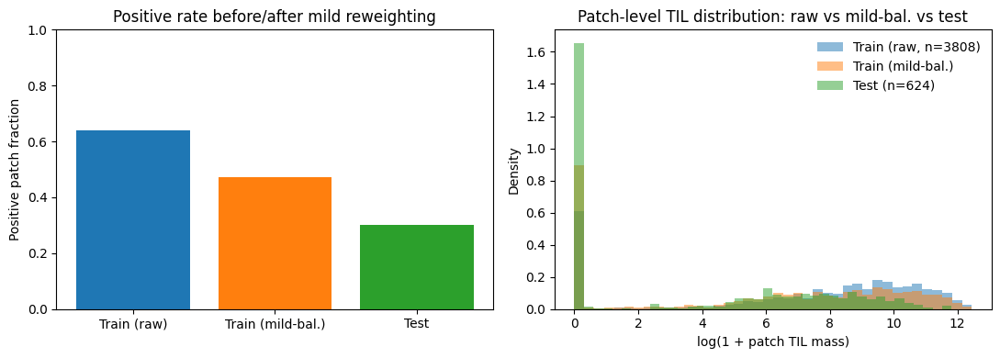

In [ ]:
from sklearn.metrics import roc_curve, precision_recall_curve, auc

best_ckpt_path = OUT_DIR / "best_shg_attunet_single_split.pt"
ckpt = torch.load(best_ckpt_path, map_location=DEVICE)

train_patients = ckpt["train_patients"]
val_patients   = ckpt["val_patients"]
test_patients  = ckpt["test_patients"]

print("Best checkpoint from epoch:", ckpt["epoch"])
print("Train:", train_patients)
print("Val:  ", val_patients)
print("Test: ", test_patients)

# rebuild loaders so train_ds recomputes til_scale and shares it with val/test
train_loader, val_loader, test_loader, train_ds, val_ds, test_ds = \
    build_loaders_for_fold(train_patients, val_patients, test_patients)

# rebuild model and load weights
model = AttUNet(img_ch=1, output_ch=1, base_ch=32, p_drop=0.2).to(DEVICE)
model.load_state_dict(ckpt["model_state"])
model.eval()


In [ ]:
def _fix_target_shape(den_cont):
    # ensure [B, 1, H, W]
    if den_cont.ndim == 4:
        if den_cont.shape[1] != 1 and den_cont.shape[-1] == 1:
            den_cont = den_cont.permute(0, 3, 1, 2).contiguous()
    return den_cont


In [ ]:
def collect_test_scores(model, loader, thr_cont=TIL_BIN_THR):
    model.eval()
    all_scores = []
    all_labels = []

    with torch.no_grad():
        for imgs, den_cont, _ in loader:
            imgs     = imgs.to(DEVICE, non_blocking=True)
            den_cont = den_cont.to(DEVICE, non_blocking=True)
            den_cont = _fix_target_shape(den_cont)

            with torch.amp.autocast(device_type='cuda', enabled=(DEVICE.type == "cuda")):
                logits = model(imgs)
                probs  = torch.sigmoid(logits)

            # binary GT for ROC/PR
            gt_bin = (den_cont >= thr_cont).float()

            all_scores.append(probs.cpu().view(-1))
            all_labels.append(gt_bin.cpu().view(-1))

    y_scores = torch.cat(all_scores).numpy()
    y_true   = torch.cat(all_labels).numpy().astype(np.uint8)
    return y_true, y_scores

y_true, y_scores = collect_test_scores(model, test_loader)
print("Collected pixels:", y_true.shape[0])
print("Positive pixels: ", y_true.sum(), f"({100*y_true.mean():.2f}%)")


Collected pixels: 163577856
Positive pixels:  5566897 (3.40%)


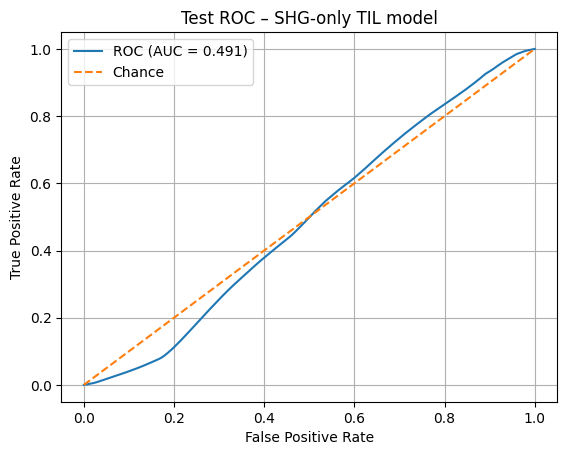

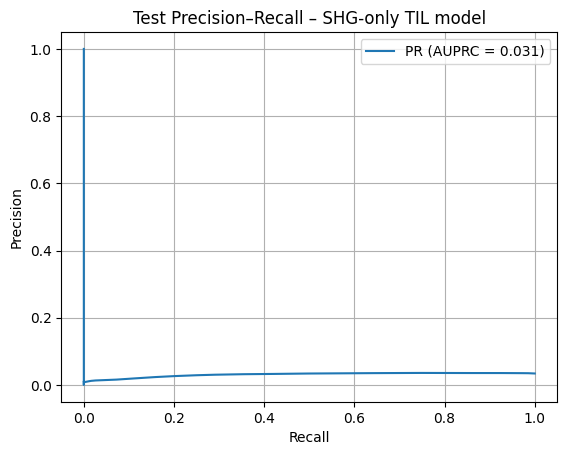

In [ ]:
import matplotlib.pyplot as plt

# ROC
fpr, tpr, _ = roc_curve(y_true, y_scores)
roc_auc = auc(fpr, tpr)

plt.figure()
plt.plot(fpr, tpr, label=f"ROC (AUC = {roc_auc:.3f})")
plt.plot([0, 1], [0, 1], linestyle="--", label="Chance")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Test ROC – SHG-only TIL model")
plt.legend()
plt.grid(True)
plt.show()

# Precision–Recall
precision, recall, _ = precision_recall_curve(y_true, y_scores)
pr_auc = auc(recall, precision)

plt.figure()
plt.plot(recall, precision, label=f"PR (AUPRC = {pr_auc:.3f})")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Test Precision–Recall – SHG-only TIL model")
plt.legend()
plt.grid(True)
plt.show()


In [ ]:
class AttentionGate(nn.Module):
    def __init__(self, F_g, F_l, F_int):
        super().__init__()
        self.W_g = nn.Sequential(
            nn.Conv2d(F_g, F_int, kernel_size=1),
            nn.BatchNorm2d(F_int)
        )
        self.W_x = nn.Sequential(
            nn.Conv2d(F_l, F_int, kernel_size=1),
            nn.BatchNorm2d(F_int)
        )
        self.psi = nn.Sequential(
            nn.Conv2d(F_int, 1, kernel_size=1),
            nn.BatchNorm2d(1),
            nn.Sigmoid()
        )
        self.relu = nn.ReLU(inplace=True)
        self.last_psi = None   # <--- store last attention map

    def forward(self, g, x):
        g1  = self.W_g(g)
        x1  = self.W_x(x)
        psi = self.relu(g1 + x1)
        psi = self.psi(psi)        # [B,1,h,w] , values in [0,1]
        self.last_psi = psi        # <--- save it here
        return x * psi


In [ ]:
import torch.nn.functional as F
import matplotlib.pyplot as plt
import numpy as np

def run_with_attention(model, ds, idx):
    """
    Run model on a single sample from dataset ds[idx]
    and return SHG, GT TIL, Pred TIL, and attention maps from each gate.
    """
    model.eval()
    img_t, den_cont_t, _ = ds[idx]

    # fix target shape if needed, but mostly we care about img here
    if den_cont_t.ndim == 3 and den_cont_t.shape[0] != 1 and den_cont_t.shape[-1] == 1:
        den_cont_t = den_cont_t.permute(2, 0, 1)

    img = img_t.unsqueeze(0).to(DEVICE)          # [1,1,H,W]
    den_cont = den_cont_t.unsqueeze(0).to(DEVICE)

    with torch.no_grad():
        with torch.amp.autocast(device_type='cuda', enabled=(DEVICE.type == "cuda")):
            logits = model(img)
            probs  = torch.sigmoid(logits)

    # base maps for plotting
    shg_np  = img_t[0].cpu().numpy()
    gt_np   = den_cont_t[0].cpu().numpy()
    pred_np = probs[0, 0].cpu().numpy()

    H, W = shg_np.shape

    # collect attention maps from each gate (if present)
    att_maps = []
    att_names = []

    # adjust these names if your model uses different attribute names
    gates = [
        ("up1", getattr(model, "up1", None)),
        ("up2", getattr(model, "up2", None)),
        ("up3", getattr(model, "up3", None)),
        ("up4", getattr(model, "up4", None)),
    ]

    for name, up_block in gates:
        if up_block is None:
            continue
        gate = getattr(up_block, "att", None)
        if gate is None or gate.last_psi is None:
            continue

        psi = gate.last_psi[0, 0]          # [h,w]
        psi_up = F.interpolate(
            gate.last_psi, size=(H, W), mode="bilinear", align_corners=False
        )[0, 0].cpu().numpy()              # upsample to input size

        att_maps.append(psi_up)
        att_names.append(name)

    return shg_np, gt_np, pred_np, att_maps, att_names


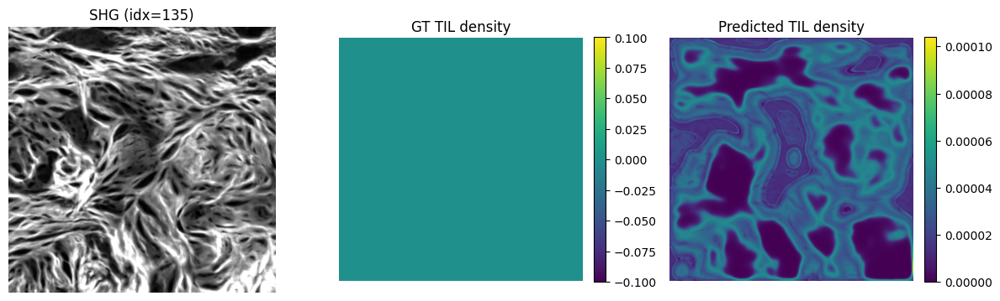

In [ ]:
import numpy as np

def show_attention_example(model, ds, idx=None):
    if idx is None:
        idx = np.random.randint(len(ds))

    shg_np, gt_np, pred_np, att_maps, att_names = run_with_attention(model, ds, idx)

    n_att = len(att_maps)
    n_cols = 3 + n_att   # SHG, GT, Pred + attention maps

    fig, axes = plt.subplots(1, n_cols, figsize=(4 * n_cols, 4))

    # SHG
    axes[0].imshow(shg_np, cmap="gray")
    axes[0].set_title(f"SHG (idx={idx})")
    axes[0].axis("off")

    # GT TIL
    im1 = axes[1].imshow(gt_np)
    axes[1].set_title("GT TIL density")
    axes[1].axis("off")
    plt.colorbar(im1, ax=axes[1], fraction=0.046, pad=0.04)

    # Predicted TIL
    im2 = axes[2].imshow(pred_np)
    axes[2].set_title("Predicted TIL density")
    axes[2].axis("off")
    plt.colorbar(im2, ax=axes[2], fraction=0.046, pad=0.04)

    # Attention maps (overlay on SHG-like colormap)
    for i, (amap, name) in enumerate(zip(att_maps, att_names), start=3):
        axes[i].imshow(shg_np, cmap="gray")
        axes[i].imshow(amap, cmap="jet", alpha=0.5)  # attention overlay
        axes[i].set_title(f"Attention {name}")
        axes[i].axis("off")

    plt.tight_layout()
    plt.show()

# Example usage: each call picks a NEW random test sample
show_attention_example(model, test_ds)


In [ ]:
import os
import numpy as np
import cv2
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from tqdm import tqdm
from scipy.stats import spearmanr, pearsonr

DATA_ROOT = Path("/content/Outputs_512_den_new")
PATIENTS = sorted([p.name for p in DATA_ROOT.iterdir() if p.is_dir()])
print("Patients:", PATIENTS)

def load_gray(path):
    img = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)
    return img.astype(np.float32) / 255.0

records = []

for pid in PATIENTS:
    shg_dir = DATA_ROOT / pid / "SHG"
    til_dir = DATA_ROOT / pid / "TIL_DEN"
    if not shg_dir.exists() or not til_dir.exists():
        print(f"Skipping {pid} (missing SHG or TIL_DEN)")
        continue

    shg_files = sorted([f for f in shg_dir.glob("*.png")])

    for sf in tqdm(shg_files, desc=f"Processing {pid}"):
        til_path = til_dir / sf.name
        if not til_path.exists():
            continue

        shg = load_gray(sf)
        til = load_gray(til_path)

        til_mass = til.sum()

        # SHG FEATURES
        shg_mean = shg.mean()
        shg_std  = shg.std()
        shg_max  = shg.max()
        shg_p90  = np.percentile(shg, 90)

        # fiber area = % pixels > threshold
        thr = np.percentile(shg, 75)    # adaptive threshold
        fiber_area = (shg > thr).mean()

        records.append([
            pid, sf.name, til_mass,
            shg_mean, shg_std, shg_max, shg_p90, fiber_area
        ])
import pandas as pd

cols = ["patient", "patch", "til_mass",
        "shg_mean", "shg_std", "shg_max", "shg_p90", "fiber_area"]

df = pd.DataFrame(records, columns=cols)
df.head()

shg_features = ["shg_mean", "shg_std", "shg_max", "shg_p90", "fiber_area"]

corr_table = []
for feat in shg_features:
    rho, pval = spearmanr(df[feat], df["til_mass"])
    corr_table.append([feat, rho, pval])

corr_df = pd.DataFrame(corr_table, columns=["feature", "spearman_rho", "p_value"])
corr_df


Patients: ['BCRAA04Y_band_overlap', 'BCRAA0AY_band_overlap', 'BCRAA0BG_band_overlap', 'BCRAA0C1_band_overlap', 'BCRAA0CK_band_overlap', 'BCRAA0IP_band_overlap', 'BCRAA0JI_band_overlap', 'BCRAA0SD_band_overlap', 'BCRAA0SF_band_overlap', 'BCRAA0SH_band_overlap', 'BCRAA0SI_band_overlap', 'BCRAA0SM_band_overlap', 'BCRAA0SP_band_overlap', 'BCRAA0SQ_band_overlap', 'BCRAA0YC_band_overlap', 'BCRAA1FC_band_overlap', 'BCRAA1LI_band_overlap', 'BCRAA22D_band_overlap', 'BCRAA278_band_overlap', 'BCRAA2DA_band_overlap', 'BCRAA2LE_band_overlap', 'BCRAA3OD_band_overlap', 'BCRAA3Y0_band_overlap', 'BCRAA3YJ_band_overlap', 'BCRAA4S2_band_overlap', 'BCRAA4SF_band_overlap', 'BCRAA5DD_band_overlap', 'BCRAA74U_band_overlap', 'BCRAAB41_band_overlap']


Processing BCRAAB41_band_overlap: 100%|██████████| 304/304 [00:02<00:00, 107.12it/s]


,feature,spearman_rho,p_value
0,shg_mean,-0.103364,1.335598e-13
1,shg_std,-0.079456,1.315067e-08
2,shg_max,-0.022926,1.014874e-01
3,shg_p90,-0.091998,4.550991e-11
4,fiber_area,-0.012400,3.757953e-01


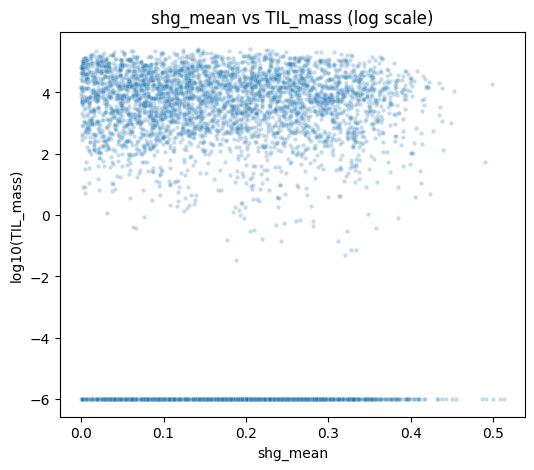

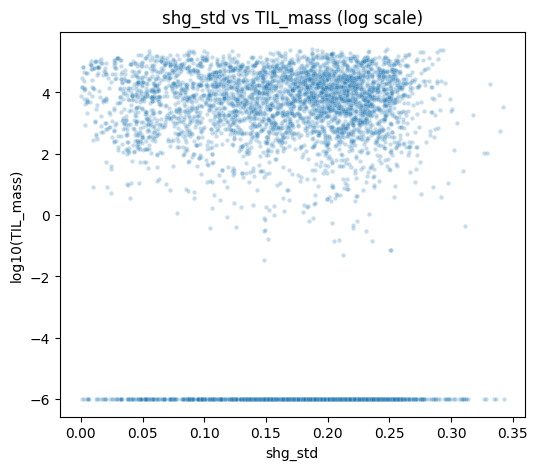

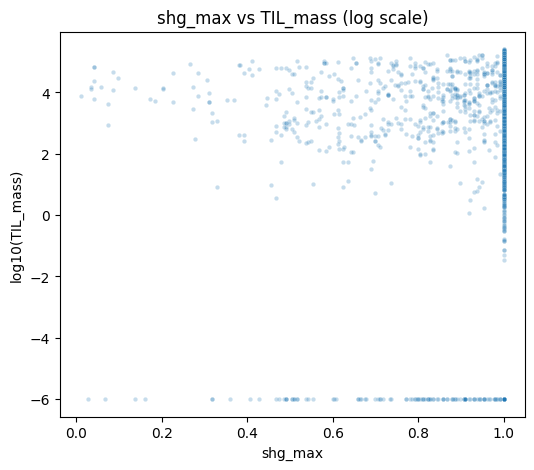

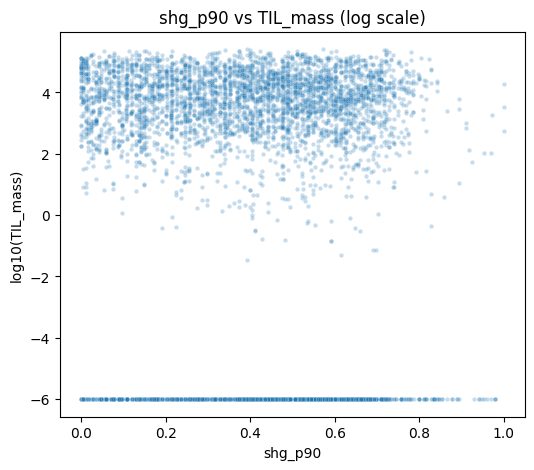

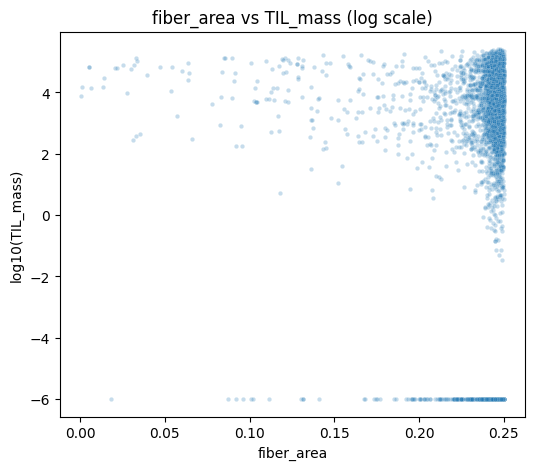

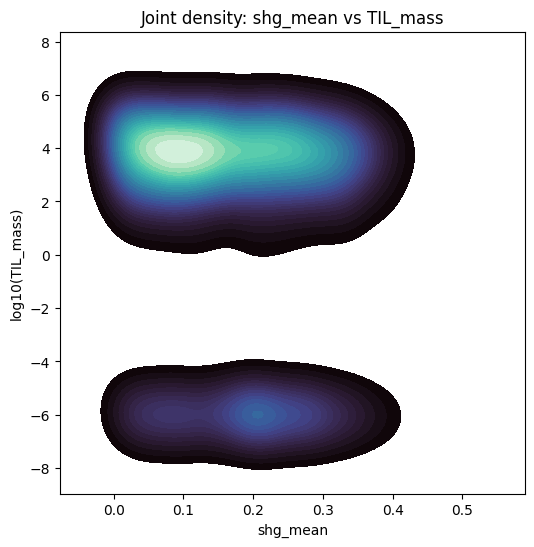

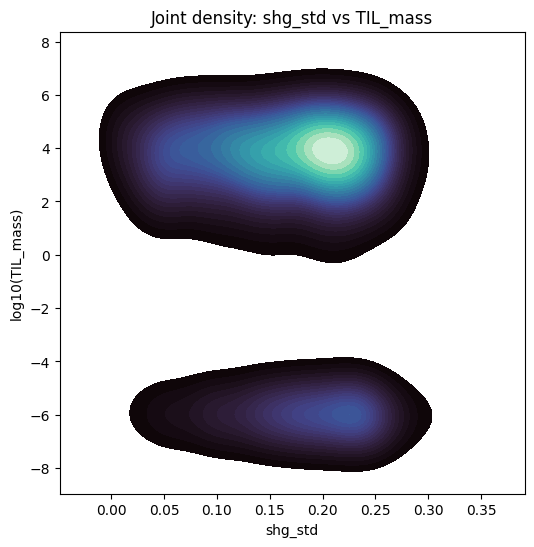

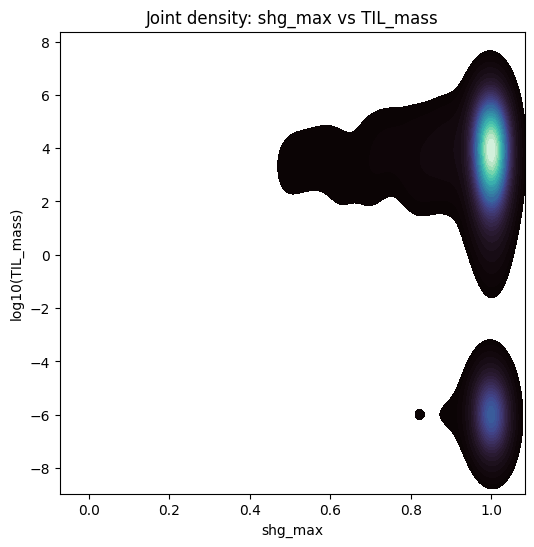

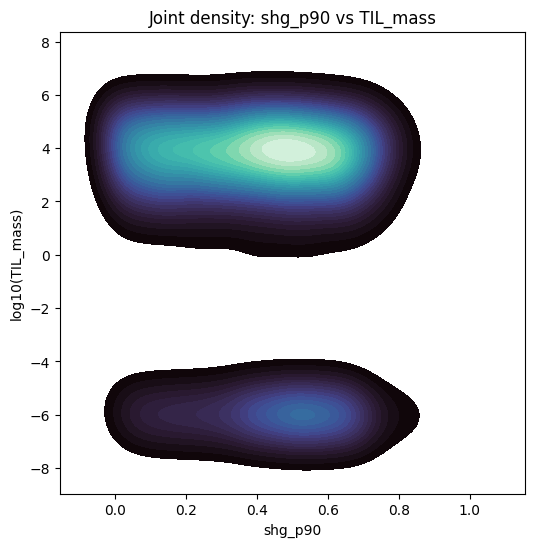

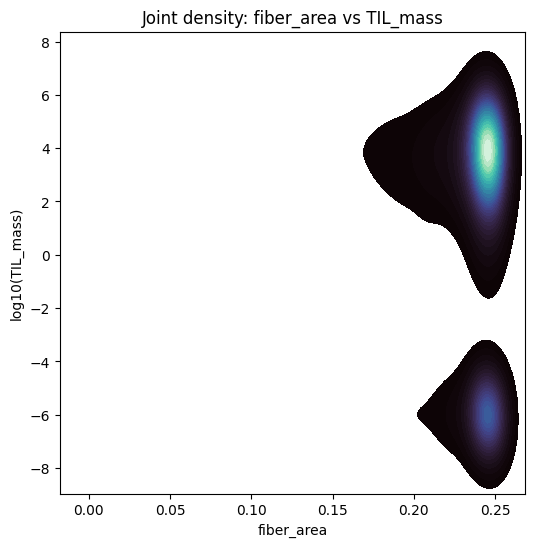

In [ ]:
df["til_log"] = np.log10(df["til_mass"] + 1e-6)
for feat in shg_features:
    plt.figure(figsize=(6,5))
    sns.scatterplot(
        x=df[feat], y=df["til_log"], alpha=0.25, s=10
    )
    plt.xlabel(feat)
    plt.ylabel("log10(TIL_mass)")
    plt.title(f"{feat} vs TIL_mass (log scale)")
    plt.show()
for feat in shg_features:
    plt.figure(figsize=(6,6))
    sns.kdeplot(
        x=df[feat], y=df["til_log"],
        fill=True, cmap="mako", levels=30, thresh=0.05
    )
    plt.xlabel(feat)
    plt.ylabel("log10(TIL_mass)")
    plt.title(f"Joint density: {feat} vs TIL_mass")
    plt.show()


In [ ]:
import numpy as np
import cv2
from pathlib import Path
from tqdm import tqdm
import pandas as pd
from scipy.stats import spearmanr
from skimage.feature import structure_tensor
from skimage.filters import gabor
from skimage.morphology import skeletonize
from skimage.measure import label, regionprops

In [ ]:
def structure_tensor_eigvals(Axx, Axy, Ayy):
    tmp  = 0.5 * (Axx + Ayy)
    diff = 0.5 * (Axx - Ayy)
    rad  = np.sqrt(diff**2 + Axy**2)
    l1 = tmp + rad
    l2 = tmp - rad
    return l1, l2

def structure_tensor_features(img):
    Axx, Axy, Ayy = structure_tensor(img, sigma=1)
    e1, e2 = structure_tensor_eigvals(Axx, Axy, Ayy)

    coherence = (e1 - e2) / (e1 + e2 + 1e-8)

    # Orientation angle
    theta = 0.5 * np.arctan2(2*Axy, Axx - Ayy)

    return {
        "coh_mean": coherence.mean(),
        "coh_std": coherence.std(),
        "ori_mean": np.mean(theta),
        "ori_std": np.std(theta),
    }

In [ ]:
def gabor_energy(img, freq=0.2):
    feats = {}
    for theta in [0, np.pi/4, np.pi/2, 3*np.pi/4]:
        filt_real, filt_imag = gabor(img, frequency=freq, theta=theta)
        feats[f"gabor_{int(theta*180/np.pi)}"] = filt_real.mean()
    return feats


In [ ]:
def fiber_skeleton_features(img):
    # Threshold using Otsu -> get fiber mask
    thr = cv2.threshold((img*255).astype(np.uint8), 0, 255, cv2.THRESH_OTSU)[1]
    mask = thr > 0

    skel = skeletonize(mask)

    # Get labeled skeleton components
    labeled = label(skel)
    props = regionprops(labeled)

    lengths = []
    straightness = []
    curvature_vals = []

    for p in props:
        coords = p.coords
        if len(coords) < 10:
            continue

        # length = number of pixels
        L = len(coords)
        lengths.append(L)

        # straightness = chord / arc length
        d = np.linalg.norm(coords[0] - coords[-1])
        straightness.append(d / (L + 1e-6))

        # curvature (approximate)
        diffs = np.diff(coords, axis=0)
        angles = np.arctan2(diffs[:,1], diffs[:,0])
        curvature = np.std(np.diff(angles))
        curvature_vals.append(curvature)

    if len(lengths)==0:
        return dict(fiber_len_mean=0, straight_mean=0, curv_mean=0)

    return {
        "fiber_len_mean": np.mean(lengths),
        "straight_mean": np.mean(straightness),
        "curv_mean": np.mean(curvature_vals),
    }


In [ ]:
records = []

DATA_ROOT = Path("/content/Outputs_512_den_new")
PATIENTS = sorted([p.name for p in DATA_ROOT.iterdir() if p.is_dir()])

for pid in PATIENTS:
    shg_dir = DATA_ROOT / pid / "SHG"
    til_dir = DATA_ROOT / pid / "TIL_DEN"

    for shg_file in tqdm(list(shg_dir.glob("*.png")), desc=pid):
        til_file = til_dir / shg_file.name
        if not til_file.exists():
            continue

        # load images
        shg = cv2.imread(str(shg_file), cv2.IMREAD_GRAYSCALE).astype(np.float32)/255
        til = cv2.imread(str(til_file), cv2.IMREAD_GRAYSCALE).astype(np.float32)/255

        til_mass = til.sum()

        # Extract secondary features
        st_feats = structure_tensor_features(shg)
        gab_feats = gabor_energy(shg)
        skel_feats = fiber_skeleton_features(shg)

        feature_row = {
            "patient": pid,
            "patch": shg_file.name,
            "til_mass": til_mass,
        }
        feature_row.update(st_feats)
        feature_row.update(gab_feats)
        feature_row.update(skel_feats)

        records.append(feature_row)

df = pd.DataFrame(records)
df.to_csv("shg_secondary_features.csv", index=False)
df.head()


BCRAAB41_band_overlap: 100%|██████████| 304/304 [03:41<00:00,  1.37it/s]


,patient,patch,til_mass,coh_mean,coh_std,ori_mean,ori_std,gabor_0,gabor_45,gabor_90,gabor_135,fiber_len_mean,straight_mean,curv_mean
0,BCRAA04Y_band_overlap,BCRAA04Y_band_overlap_patch_0022_y512_x1536.png,66655.140625,0.511832,0.413646,-0.219164,0.657646,0.000072,0.000042,0.000072,0.000042,41.484848,0.964021,0.817196
1,BCRAA04Y_band_overlap,BCRAA04Y_band_overlap_patch_0014_y512_x1536.png,42107.824219,0.616856,0.360587,0.139946,0.856239,0.000105,0.000061,0.000105,0.000061,52.718750,0.824863,1.325660
2,BCRAA04Y_band_overlap,BCRAA04Y_band_overlap_patch_0013_y1536_x1024.png,15026.161133,0.446821,0.414029,-0.116494,0.575850,0.000064,0.000037,0.000064,0.000037,56.471698,0.782766,1.140936
3,BCRAA04Y_band_overlap,BCRAA04Y_band_overlap_patch_0021_y1024_x1024.png,1855.874268,0.414714,0.408778,0.031980,0.705138,0.000022,0.000013,0.000022,0.000013,36.921053,0.835404,1.255892
4,BCRAA04Y_band_overlap,BCRAA04Y_band_overlap_patch_0014_y1536_x1536.png,25235.765625,0.462097,0.416652,-0.152709,0.730568,0.000050,0.000029,0.000050,0.000029,50.790323,0.911391,0.941134


In [ ]:
features = [c for c in df.columns if c not in ["patient","patch","til_mass"]]

corr_list = []
for f in features:
    rho, p = spearmanr(df[f], df["til_mass"])
    corr_list.append([f, rho, p])

corr_df = pd.DataFrame(corr_list, columns=["feature", "rho", "p"])
corr_df.sort_values("rho", ascending=False)


,feature,rho,p
9,straight_mean,0.071221,3.516265e-07
2,ori_mean,0.070745,4.208109e-07
1,coh_std,0.038081,6.509661e-03
10,curv_mean,-0.027456,4.983238e-02
3,ori_std,-0.046171,9.684340e-04
0,coh_mean,-0.063938,4.844409e-06
5,gabor_45,-0.103331,1.359415e-13
6,gabor_90,-0.103364,1.335598e-13
4,gabor_0,-0.103364,1.335598e-13
7,gabor_135,-0.103386,1.319540e-13
